In [1]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import MinMaxScaler
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Wedge
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle




sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [40]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'
integr_output = '../../../3_integrated_assay_results/3_outputs'

In [ ]:
orf_distances = pd.read_csv(f"{outputs_dir}/orf_distances.csv").pipe(pl.from_pandas)
edge_df = pd.read_csv(f"{outputs_dir}/edges_df.csv")
all_assay_df = pd.read_csv(f"{integr_output}/0_all_gene_variants_assayed_summary.tsv", sep="\t")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/1768444604.py:2: DtypeWarning: Columns (162,165,190,208,209,226,227,228,229,230,231,232,233,234,240,241,283,284,609,611,673,675,677,963,970,973,993,1003,1005,1009,1012,1013,1019,1023,1025,1028) have mixed types. Specify dtype option on import or set low_memory=False.
  edge_df = pd.read_csv(f"{outputs_dir}/edges_df.csv")
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/1768444604.py:3: DtypeWarning: Columns (163,197,208,211,215,216,217,218,252,253,256,257,478,480,522,552,554,556,568,570,582,584,592,594,646,648,650,656,658,662,666,698,700,702,822,874,876,878,880,882,937,946,948,951,953,958,959,966,971,976,977,978,982,985,994,995,996) have mixed types. Specify dtype option on import or set low_memory=False.
  all_assay_df = pd.read_csv(f"{integr_output}/0_all_gene_variants_assayed_summary.tsv", sep="\t")


# Simple Log2FC

In [37]:
def plot_log2fc_panel(edge_df, db_symbol, orf_distances=None,
                      clnsig_column='clinvar_clnsig_clean',
                      palette_dict=None, row_height=2.0,
                      figsize=(10, 12), save_path=None):
    """
    Plot Log2FC panel with RMS distance for a given gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    db_symbol : str
        Gene symbol to plot
    orf_distances : pd.DataFrame or pl.DataFrame, optional
        DataFrame with ORF distance data
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each row in the plot
    figsize : tuple
        Figure size (width, height)
    save_path : str, optional
        Path to save the figure
    
    Returns:
    --------
    fig, ax : matplotlib figure and axes
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Pivot for structure and sorting
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    
    # Mappings
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    # --- SORT VARIANTS ---
    interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
    pivot_raw_ordered = pivot_raw[interactor_means.index]
    pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
    pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
    
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    variants_sorted = pivot_sorted.index.tolist()
    interactors = pivot_sorted.columns.tolist()

    # --- FIGURE SETUP ---
    fig, ax = plt.subplots(figsize=figsize)
    
    # Add header for RMS distance
    if orf_distances is not None:
        header_y = len(variants_sorted) * row_height
        ax.text(-0.25, header_y, "RMS\nDist.", 
                fontsize=9, ha='right', va='bottom', fontweight='bold', color='#555555',
                transform=ax.get_yaxis_transform())

    # --- PLOT EACH VARIANT ---
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        # RMS distance text
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if not pd.isna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax.text(-0.25, y_pos, f"{dist_val:.2f}", 
                        fontsize=10, ha='right', va='center', 
                        fontfamily='monospace', color=dist_color,
                        transform=ax.get_yaxis_transform())
        
        # Variant label
        ax.text(-0.05, y_pos, variant, fontsize=10, ha='right', va='center',
                fontweight='bold', color=variant_color,
                transform=ax.get_yaxis_transform())
        
        # Plot points
        if variant == 'WT':
            for interactor in interactors:
                ax.scatter(0, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax.scatter(log2fc, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.8)
    
    # --- STYLING ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=3 (unperturbed)')
    ax.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=-3 (perturbed)')
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_xlim(-12, 6)
    ax.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Horizontal grid lines
    for i in range(len(variants_sorted)):
        ax.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.set_title(f"{db_symbol} - Log2FC with RMS Distance", fontsize=14, fontweight='bold')
    
    # --- LEGENDS ---
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    leg1 = ax.legend(handles=interactor_patches, bbox_to_anchor=(1.02, 1), loc='upper left',
                     title='Interactor', fontsize=8, title_fontsize=9)
    
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        leg2 = ax.legend(handles=clinvar_patches, bbox_to_anchor=(1.02, 0.5), loc='upper left',
                         title='ClinVar', fontsize=8, title_fontsize=9)
        ax.add_artist(leg1)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, ax

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3773049836.py:70: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


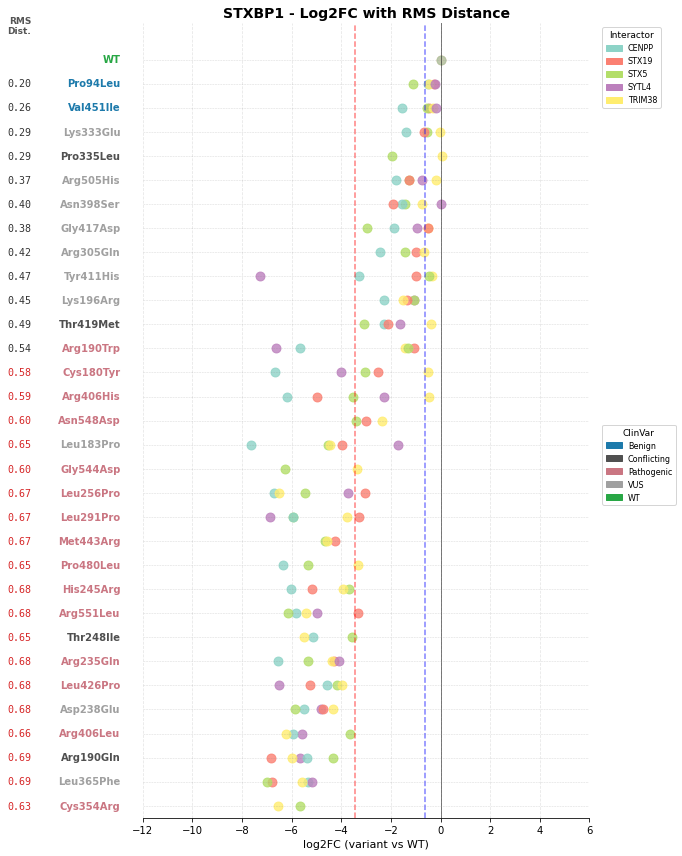

In [38]:
# Single gene plot

fig, ax = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    palette_dict=palette_dict,
    # save_path=f"{outputs_dir}/ZMYND10_log2fc.pdf"
)

In [11]:
edge_df[['plddt_f32', 'rsa_f32', 'AlphaMissense_score', 
 'gnomAD4.1_joint_AF','phyloP100way_vertebrate', 'phastCons100way_vertebrate', 'GERP++_RS', 'PROVEAN_score']]

,plddt_f32,rsa_f32,AlphaMissense_score,gnomAD4.1_joint_AF,phyloP100way_vertebrate,phastCons100way_vertebrate,GERP++_RS,PROVEAN_score
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,96.78,0.000000,.,.,7.761,1.0,5.05,.
2,77.82,3.680982,.,.,4.177,1.0,4.75,.
3,86.92,60.080647,.,3.717430e-06,3.165,1.0,5.05,.
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
2224,92.79,2.222222,0.9994,.,9.552,1.0,5.36,.
2225,86.83,5.325444,0.9696,.,7.674,1.0,5.58,.
2226,95.13,1.762115,0.9996,.,7.674,1.0,5.73,.
2227,95.06,13.076923,0.9264,.,7.568,1.0,5.73,.


# Heatmap

In [35]:
def plot_log2fc_panel(edge_df, db_symbol, orf_distances=None,
                      clnsig_column='clinvar_clnsig_clean',
                      palette_dict=None, row_height=2.0,
                      figsize=(18, 12), save_path=None,
                      annotation_cols=None):
    """
    Plot Log2FC panel with RMS distance and annotation bars for a given gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    db_symbol : str
        Gene symbol to plot
    orf_distances : pd.DataFrame or pl.DataFrame, optional
        DataFrame with ORF distance data
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each row in the plot
    figsize : tuple
        Figure size (width, height)
    save_path : str, optional
        Path to save the figure
    annotation_cols : list, optional
        List of column names to plot as vertical bars
    
    Returns:
    --------
    fig, axes : matplotlib figure and axes
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    if annotation_cols is None:
        annotation_cols = ['plddt_f32', 'rsa_f32', 'AlphaMissense_score', 
                          'gnomAD4.1_joint_AF', 'phyloP100way_vertebrate', 
                          'phastCons100way_vertebrate', 'GERP++_RS', 'PROVEAN_score']
    
    # Filter to only columns that exist in the dataframe
    annotation_cols = [col for col in annotation_cols if col in edge_df.columns]
    
    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Pivot for structure and sorting
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    
    # Mappings
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # Get annotation values per variant (take first value per variant)
    variant_annotations = gene_data.groupby('aa_change')[annotation_cols].first()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    # --- SORT VARIANTS ---
    interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
    pivot_raw_ordered = pivot_raw[interactor_means.index]
    pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
    pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
    
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    variants_sorted = pivot_sorted.index.tolist()
    interactors = pivot_sorted.columns.tolist()

    # --- FIGURE SETUP WITH GRIDSPEC ---
    n_annotations = len(annotation_cols)
    width_ratios = [3] + [0.3] * n_annotations  # Main plot + narrow bars for annotations
    
    fig, axes = plt.subplots(1, 1 + n_annotations, figsize=figsize,
                             gridspec_kw={'width_ratios': width_ratios, 'wspace': 0.02})
    
    ax = axes[0]  # Main log2fc axis
    
    # Add header for RMS distance
    if orf_distances is not None:
        header_y = len(variants_sorted) * row_height
        ax.text(-0.25, header_y, "RMS\nDist.", 
                fontsize=9, ha='right', va='bottom', fontweight='bold', color='#555555',
                transform=ax.get_yaxis_transform())

    # --- PLOT EACH VARIANT ON MAIN AXIS ---
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        # RMS distance text
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if not pd.isna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax.text(-0.25, y_pos, f"{dist_val:.2f}", 
                        fontsize=10, ha='right', va='center', 
                        fontfamily='monospace', color=dist_color,
                        transform=ax.get_yaxis_transform())
        
        # Variant label
        ax.text(-0.05, y_pos, variant, fontsize=10, ha='right', va='center',
                fontweight='bold', color=variant_color,
                transform=ax.get_yaxis_transform())
        
        # Plot points
        if variant == 'WT':
            for interactor in interactors:
                ax.scatter(0, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax.scatter(log2fc, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.8)
    
    # --- STYLING MAIN AXIS ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=3 (unperturbed)')
    ax.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=-3 (perturbed)')
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_xlim(-12, 6)
    ax.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Horizontal grid lines
    for i in range(len(variants_sorted)):
        ax.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.set_title(f"{db_symbol} - Log2FC with RMS Distance", fontsize=14, fontweight='bold')
    
    # --- ANNOTATION BAR PLOTS ---
    # Define colormaps for different annotation types
    annotation_cmaps = {
        'plddt_f32': 'RdYlGn',           # High is good (green)
        'rsa_f32': 'viridis',             # Neutral
        'AlphaMissense_score': 'RdYlGn_r', # High is bad (red)
        'gnomAD4.1_joint_AF': 'Blues',    # Frequency
        'phyloP100way_vertebrate': 'RdYlGn',  # High = conserved (good)
        'phastCons100way_vertebrate': 'RdYlGn',  # High = conserved
        'GERP++_RS': 'RdYlGn',            # High = conserved
        'PROVEAN_score': 'RdYlGn',        # High (less negative) = benign
    }
    
    # Define display names
    annotation_labels = {
        'plddt_f32': 'pLDDT',
        'rsa_f32': 'RSA',
        'AlphaMissense_score': 'AM',
        'gnomAD4.1_joint_AF': 'gnomAD',
        'phyloP100way_vertebrate': 'phyloP',
        'phastCons100way_vertebrate': 'phastCons',
        'GERP++_RS': 'GERP',
        'PROVEAN_score': 'PROVEAN',
    }
    

    for col_idx, col in enumerate(annotation_cols):
        ax_bar = axes[col_idx + 1]
        
        # Get values for this annotation
        values = []
        for variant in variants_sorted:
            if variant in variant_annotations.index:
                val = variant_annotations.loc[variant, col]
                # Convert to float, handle non-numeric values
                try:
                    values.append(float(val) if pd.notna(val) else np.nan)
                except (ValueError, TypeError):
                    values.append(np.nan)
            else:
                values.append(np.nan)
        
        values = np.array(values, dtype=float)
        
        # Normalize values for coloring (handle NaN)
        valid_mask = ~np.isnan(values)

        if valid_mask.sum() > 0:
            vmin, vmax = np.nanmin(values), np.nanmax(values)
            if vmin == vmax:
                normalized = np.where(valid_mask, 0.5, np.nan)
            else:
                normalized = (values - vmin) / (vmax - vmin)
        else:
            normalized = np.full_like(values, np.nan)
        
        # Get colormap
        cmap_name = annotation_cmaps.get(col, 'viridis')
        cmap_obj = plt.cm.get_cmap(cmap_name)
        
        # Plot horizontal bars
        for i, variant in enumerate(variants_sorted):
            y_pos = i * row_height
            
            if pd.notna(values[i]):
                color = cmap_obj(normalized[i])
                ax_bar.barh(y_pos, 1, height=row_height * 0.8, color=color, alpha=0.8)
            else:
                # Gray for missing data
                ax_bar.barh(y_pos, 1, height=row_height * 0.8, color='#E0E0E0', alpha=0.5)
        
        # Styling for annotation axes
        ax_bar.set_xlim(0, 1)
        ax_bar.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
        ax_bar.set_xticks([])
        ax_bar.set_yticks([])
        ax_bar.spines['left'].set_visible(False)
        ax_bar.spines['right'].set_visible(False)
        ax_bar.spines['top'].set_visible(False)
        ax_bar.spines['bottom'].set_visible(False)
        
        # Add column label at top
        label = annotation_labels.get(col, col)
        ax_bar.set_title(label, fontsize=8, rotation=45, ha='left', fontweight='bold')
        
        # Add horizontal grid lines to match main plot
        for i in range(len(variants_sorted)):
            ax_bar.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    # --- LEGENDS ON MAIN AXIS ---
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    leg1 = ax.legend(handles=interactor_patches, bbox_to_anchor=(-0.35, 1), loc='upper right',
                     title='Interactor', fontsize=8, title_fontsize=9)
    
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        leg2 = ax.legend(handles=clinvar_patches, bbox_to_anchor=(-0.35, 0.5), loc='upper right',
                         title='ClinVar', fontsize=8, title_fontsize=9)
        ax.add_artist(leg1)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, axes

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/2729365479.py:84: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/2729365479.py:224: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = plt.cm.get_cmap(cmap_name)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/2729365479.py:269: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout

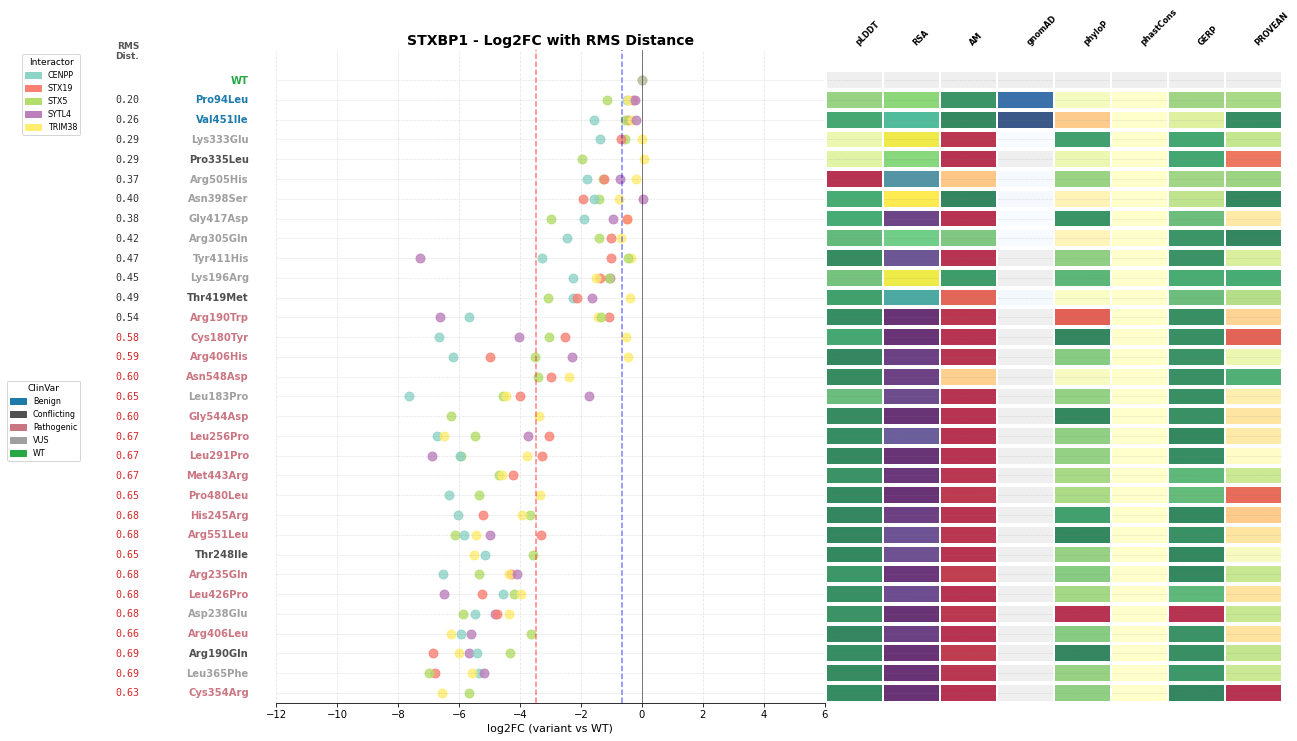

In [36]:
# Single gene plot with all annotations
fig, axes = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    palette_dict=palette_dict,
    # Optionally specify which columns to show:
    # annotation_cols=['plddt_f32', 'AlphaMissense_score', 'phyloP100way_vertebrate'],
)

# Barplot

In [39]:
def plot_log2fc_panel(edge_df, db_symbol, orf_distances=None,
                      clnsig_column='clinvar_clnsig_clean',
                      palette_dict=None, row_height=2.0,
                      figsize=(24, 12), save_path=None,
                      annotation_cols=None):
    """
    Plot Log2FC panel with RMS distance and annotation bar plots for a given gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    db_symbol : str
        Gene symbol to plot
    orf_distances : pd.DataFrame or pl.DataFrame, optional
        DataFrame with ORF distance data
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each row in the plot
    figsize : tuple
        Figure size (width, height)
    save_path : str, optional
        Path to save the figure
    annotation_cols : list, optional
        List of column names to plot as bar plots
    
    Returns:
    --------
    fig, axes : matplotlib figure and axes
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    if annotation_cols is None:
        annotation_cols = ['plddt_f32', 'rsa_f32', 'AlphaMissense_score', 
                          'gnomAD4.1_joint_AF', 'phyloP100way_vertebrate', 
                          'phastCons100way_vertebrate', 'GERP++_RS', 'PROVEAN_score']
    
    # Filter to only columns that exist in the dataframe
    annotation_cols = [col for col in annotation_cols if col in edge_df.columns]
    
    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Pivot for structure and sorting
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    
    # Mappings
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # Get annotation values per variant (take first value per variant)
    variant_annotations = gene_data.groupby('aa_change')[annotation_cols].first()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    # --- SORT VARIANTS ---
    interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
    pivot_raw_ordered = pivot_raw[interactor_means.index]
    pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
    pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
    
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    variants_sorted = pivot_sorted.index.tolist()
    interactors = pivot_sorted.columns.tolist()

    # --- FIGURE SETUP WITH GRIDSPEC ---
    n_annotations = len(annotation_cols)
    # Main plot gets more space, annotation plots get equal smaller space
    width_ratios = [3] + [1] * n_annotations
    
    fig, axes = plt.subplots(1, 1 + n_annotations, figsize=figsize,
                             gridspec_kw={'width_ratios': width_ratios, 'wspace': 0.15})
    
    ax = axes[0]  # Main log2fc axis
    
    # Add header for RMS distance
    if orf_distances is not None:
        header_y = len(variants_sorted) * row_height
        ax.text(-0.25, header_y, "RMS\nDist.", 
                fontsize=9, ha='right', va='bottom', fontweight='bold', color='#555555',
                transform=ax.get_yaxis_transform())

    # --- PLOT EACH VARIANT ON MAIN AXIS ---
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        # RMS distance text
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if not pd.isna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax.text(-0.25, y_pos, f"{dist_val:.2f}", 
                        fontsize=10, ha='right', va='center', 
                        fontfamily='monospace', color=dist_color,
                        transform=ax.get_yaxis_transform())
        
        # Variant label
        ax.text(-0.05, y_pos, variant, fontsize=10, ha='right', va='center',
                fontweight='bold', color=variant_color,
                transform=ax.get_yaxis_transform())
        
        # Plot points
        if variant == 'WT':
            for interactor in interactors:
                ax.scatter(0, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax.scatter(log2fc, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.8)
    
    # --- STYLING MAIN AXIS ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=3 (unperturbed)')
    ax.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=-3 (perturbed)')
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_xlim(-12, 6)
    ax.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Horizontal grid lines
    # for i in range(len(variants_sorted)):
    #     ax.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    # ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.set_title(f"{db_symbol} - Log2FC with RMS Distance", fontsize=14, fontweight='bold')
    
    # --- ANNOTATION BAR PLOTS ---
    # Define bar colors for different annotation types
    annotation_colors = {
        'plddt_f32': '#2ecc71',           # Green - structure confidence
        'rsa_f32': '#3498db',             # Blue - accessibility
        'AlphaMissense_score': '#e74c3c', # Red - pathogenicity
        'gnomAD4.1_joint_AF': '#9b59b6',  # Purple - frequency
        'phyloP100way_vertebrate': '#f39c12',  # Orange - conservation
        'phastCons100way_vertebrate': '#e67e22',  # Dark orange - conservation
        'GERP++_RS': '#1abc9c',            # Teal - conservation
        'PROVEAN_score': '#34495e',        # Dark gray - functional
    }
    
    # Define display names
    annotation_labels = {
        'plddt_f32': 'pLDDT',
        'rsa_f32': 'RSA',
        'AlphaMissense_score': 'AlphaMissense',
        'gnomAD4.1_joint_AF': 'gnomAD AF',
        'phyloP100way_vertebrate': 'phyloP',
        'phastCons100way_vertebrate': 'phastCons',
        'GERP++_RS': 'GERP++',
        'PROVEAN_score': 'PROVEAN',
    }
    
    for col_idx, col in enumerate(annotation_cols):
        ax_bar = axes[col_idx + 1]
        
        # Get values for this annotation
        values = []
        bar_colors = []
        for variant in variants_sorted:
            if variant in variant_annotations.index:
                val = variant_annotations.loc[variant, col]
                try:
                    values.append(float(val) if pd.notna(val) else np.nan)
                except (ValueError, TypeError):
                    values.append(np.nan)
            else:
                values.append(np.nan)
            
            # Get color based on ClinVar status
            if variant == 'WT':
                bar_colors.append('#28a745')
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                bar_colors.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
        
        values = np.array(values, dtype=float)
        y_positions = np.arange(len(variants_sorted)) * row_height
        
        # Plot horizontal bars
        bars = ax_bar.barh(y_positions, values, height=row_height * 0.7, 
                          color=bar_colors, alpha=0.7, edgecolor='black', linewidth=0.5)
        
        # Handle missing values - plot gray placeholder
        for i, val in enumerate(values):
            if np.isnan(val):
                ax_bar.barh(y_positions[i], 0.1, height=row_height * 0.7,
                           color='#E0E0E0', alpha=0.5, edgecolor='gray', linewidth=0.5)
        
        # Styling for annotation axes
        ax_bar.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
        ax_bar.set_yticks([])
        ax_bar.spines['left'].set_visible(False)
        ax_bar.spines['top'].set_visible(False)
        ax_bar.spines['right'].set_visible(False)
        
        # Set x-axis label
        label = annotation_labels.get(col, col)
        ax_bar.set_xlabel(label, fontsize=9, fontweight='bold')
        
        # Add horizontal grid lines to match main plot
        for i in range(len(variants_sorted)):
            ax_bar.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
        
        ax_bar.grid(axis='x', linestyle='--', alpha=0.3)
        
        # Add zero line for scores that can be negative
        if col in ['PROVEAN_score', 'GERP++_RS', 'phyloP100way_vertebrate']:
            ax_bar.axvline(x=0, color='black', linestyle='-', alpha=0.3, linewidth=1)
    
    # --- LEGENDS ON MAIN AXIS ---
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    leg1 = ax.legend(handles=interactor_patches, bbox_to_anchor=(-0.35, 1), loc='upper right',
                     title='Interactor', fontsize=8, title_fontsize=9)
    
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        leg2 = ax.legend(handles=clinvar_patches, bbox_to_anchor=(-0.35, 0.5), loc='upper right',
                         title='ClinVar', fontsize=8, title_fontsize=9)
        ax.add_artist(leg1)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, axes

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/1748664947.py:84: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/1748664947.py:263: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


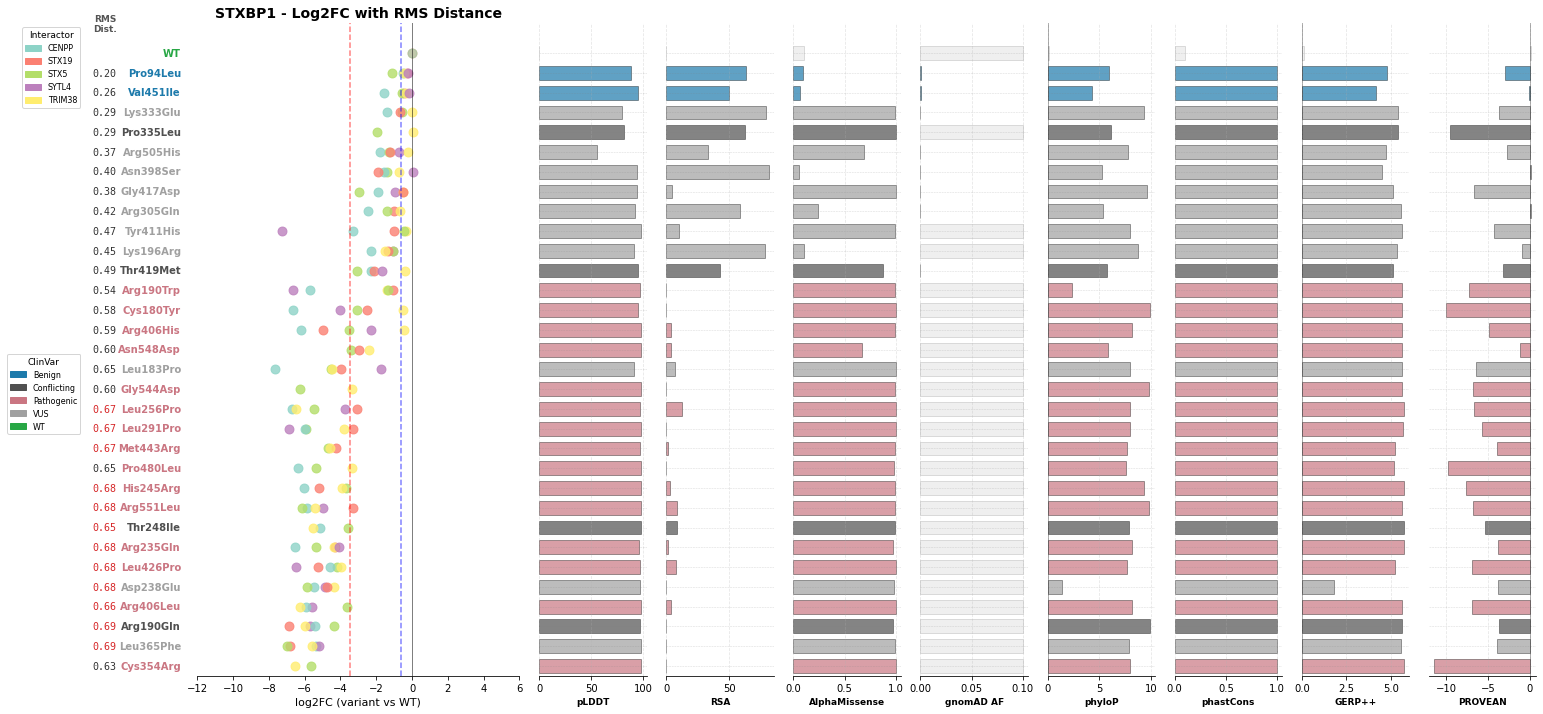

In [34]:
# Single gene plot with all annotations
fig, axes = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    palette_dict=palette_dict,
    # Optionally specify which columns to show:
    # annotation_cols=['plddt_f32', 'AlphaMissense_score', 'phyloP100way_vertebrate'],
)

# Barplot + Misloc + abundance

In [125]:
def plot_log2fc_panel(edge_df, db_symbol, orf_distances=None,
                      all_assay_df=None,
                      clnsig_column='clinvar_clnsig_clean',
                      palette_dict=None, row_height=2.0,
                      figsize=(24, 12), save_path=None,
                      annotation_cols=None):
    """
    Plot Log2FC panel with RMS distance, DualIPA, IMG misloc and annotation bar plots for a given gene.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    db_symbol : str
        Gene symbol to plot
    orf_distances : pd.DataFrame or pl.DataFrame, optional
        DataFrame with ORF distance data
    all_assay_df : pd.DataFrame, optional
        DataFrame with DualIPA and IMG misloc scores
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    row_height : float
        Height of each row in the plot
    figsize : tuple
        Figure size (width, height)
    save_path : str, optional
        Path to save the figure
    annotation_cols : list, optional
        List of column names to plot as bar plots
    
    Returns:
    --------
    fig, axes : matplotlib figure and axes
    """
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    if annotation_cols is None:
        annotation_cols = ['plddt_f32', 'rsa_f32', 'AlphaMissense_score', 
                          'gnomAD4.1_joint_AF', 'phyloP100way_vertebrate', 
                          'GERP++_RS', 'PROVEAN_score']
    
    # Filter to only columns that exist in the dataframe
    annotation_cols = [col for col in annotation_cols if col in edge_df.columns]
    
    # --- DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Pivot for structure and sorting
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    
    # Mappings
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # Get annotation values per variant (take first value per variant)
    variant_annotations = gene_data.groupby('aa_change')[annotation_cols].first()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        if hasattr(orf_distances, 'to_pandas'):
            orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            dist_map = d_df.set_index('aa_change')['norm_dist_rms'].to_dict()

    # --- ASSAY SCORES DATA SETUP ---
    dualipa_map = {}
    dualipa_hit_map = {}
    img_misloc_map = {}
    img_misloc_hit_map = {}
    
    if all_assay_df is not None:
        assay_gene = all_assay_df[all_assay_df['symbol'] == db_symbol].copy()
        if not assay_gene.empty:
            assay_gene['aa_change'] = assay_gene['aa_change'].fillna('WT')
            if 'dualipa_score' in assay_gene.columns:
                dualipa_map = assay_gene.set_index('aa_change')['dualipa_score'].to_dict()
            if 'dualipa_hit' in assay_gene.columns:
                dualipa_hit_map = assay_gene.set_index('aa_change')['dualipa_hit'].to_dict()
            if 'img_misloc_score' in assay_gene.columns:
                img_misloc_map = assay_gene.set_index('aa_change')['img_misloc_score'].to_dict()
            if 'img_misloc_hit' in assay_gene.columns:
                img_misloc_hit_map = assay_gene.set_index('aa_change')['img_misloc_hit'].to_dict()

    # --- SORT VARIANTS ---
    interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
    pivot_raw_ordered = pivot_raw[interactor_means.index]
    pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
    pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
    
    if 'WT' in pivot_sorted.index:
        wt_row = pivot_sorted.loc[['WT']]
        pivot_sorted = pivot_sorted.drop('WT')
        pivot_sorted = pd.concat([pivot_sorted, wt_row])
    
    variants_sorted = pivot_sorted.index.tolist()
    interactors = pivot_sorted.columns.tolist()

    # --- FIGURE SETUP WITH GRIDSPEC ---
    n_annotations = len(annotation_cols)
    n_interactors = len(all_interactors)
    
    # Adjust figure width if we need two columns for legend
    base_width = figsize[0]
    if n_interactors > 15:
        base_width += 3  # Add extra width for two-column legend
    
    # Main plot gets more space, annotation plots get equal smaller space
    width_ratios = [3] + [1] * n_annotations
    
    fig, axes = plt.subplots(1, 1 + n_annotations, figsize=(base_width, figsize[1]),
                             gridspec_kw={'width_ratios': width_ratios, 'wspace': 0.15})
    
    ax = axes[0]  # Main log2fc axis
    
    # Add headers for score columns (from left to right: IMG, DualIPA, RMS)
    header_y = len(variants_sorted) * row_height
    ax.text(-0.45, header_y, "IMG\nMisloc", 
            fontsize=8, ha='right', va='bottom', fontweight='bold', color='#555555',
            transform=ax.get_yaxis_transform())
    ax.text(-0.35, header_y, "Dual\nIPA", 
            fontsize=8, ha='right', va='bottom', fontweight='bold', color='#555555',
            transform=ax.get_yaxis_transform())
    if orf_distances is not None:
        ax.text(-0.25, header_y, "RMS\nDist.", 
                fontsize=8, ha='right', va='bottom', fontweight='bold', color='#555555',
                transform=ax.get_yaxis_transform())

    # --- PLOT EACH VARIANT ON MAIN AXIS ---
    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        # IMG misloc score (leftmost)
        img_val = img_misloc_map.get(variant, np.nan)
        if pd.notna(img_val):
            try:
                img_val = float(img_val)
                img_hit = img_misloc_hit_map.get(variant, False)
                img_color = '#d62728' if img_hit else '#333333'
                ax.text(-0.45, y_pos, f"{img_val:.2f}", 
                        fontsize=9, ha='right', va='center', 
                        fontfamily='monospace', color=img_color,
                        transform=ax.get_yaxis_transform())
            except (ValueError, TypeError):
                pass
        
        # DualIPA score (middle)
        dualipa_val = dualipa_map.get(variant, np.nan)
        if pd.notna(dualipa_val):
            try:
                dualipa_val = float(dualipa_val)
                dualipa_hit = dualipa_hit_map.get(variant, False)
                dualipa_color = '#d62728' if dualipa_hit else '#333333'
                ax.text(-0.35, y_pos, f"{dualipa_val:.2f}", 
                        fontsize=9, ha='right', va='center', 
                        fontfamily='monospace', color=dualipa_color,
                        transform=ax.get_yaxis_transform())
            except (ValueError, TypeError):
                pass
        
        # RMS distance (closest to plot)
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if not pd.isna(dist_val):
                dist_color = '#d62728' if dist_val >= 0.547 else '#333333'
                ax.text(-0.25, y_pos, f"{dist_val:.2f}", 
                        fontsize=9, ha='right', va='center', 
                        fontfamily='monospace', color=dist_color,
                        transform=ax.get_yaxis_transform())
        
        # Variant label
        ax.text(-0.05, y_pos, variant, fontsize=10, ha='right', va='center',
                fontweight='bold', color=variant_color,
                transform=ax.get_yaxis_transform())
        
        # Plot points
        if variant == 'WT':
            for interactor in interactors:
                ax.scatter(0, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax.scatter(log2fc, y_pos, color=interactor_colors[interactor],
                           s=80, alpha=0.8)
    
    # --- STYLING MAIN AXIS ---
    ax.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    ax.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=3 (unperturbed)')
    ax.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5, label='LLR=-3 (perturbed)')
    
    ax.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax.set_xlim(-12, 6)
    ax.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.set_title(f"{db_symbol} - Log2FC with Assay Scores", fontsize=14, fontweight='bold')
    
    # --- ANNOTATION BAR PLOTS ---
    annotation_labels = {
        'plddt_f32': 'pLDDT',
        'rsa_f32': 'RSA',
        'AlphaMissense_score': 'AlphaMissense',
        'gnomAD4.1_joint_AF': 'gnomAD AF',
        'phyloP100way_vertebrate': 'phyloP',
        'phastCons100way_vertebrate': 'phastCons',
        'GERP++_RS': 'GERP++',
        'PROVEAN_score': 'PROVEAN',
    }
    
    for col_idx, col in enumerate(annotation_cols):
        ax_bar = axes[col_idx + 1]
        
        # Get values for this annotation
        values = []
        bar_colors = []
        for variant in variants_sorted:
            if variant in variant_annotations.index:
                val = variant_annotations.loc[variant, col]
                try:
                    values.append(float(val) if pd.notna(val) else np.nan)
                except (ValueError, TypeError):
                    values.append(np.nan)
            else:
                values.append(np.nan)
            
            # Get color based on ClinVar status
            if variant == 'WT':
                bar_colors.append('#28a745')
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                bar_colors.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
        
        values = np.array(values, dtype=float)
        y_positions = np.arange(len(variants_sorted)) * row_height
        
        # Plot horizontal bars
        ax_bar.barh(y_positions, values, height=row_height * 0.7, 
                   color=bar_colors, alpha=0.7, edgecolor='black', linewidth=0.5)
        
        # Handle missing values - plot gray placeholder
        for i, val in enumerate(values):
            if np.isnan(val):
                ax_bar.barh(y_positions[i], 0.1, height=row_height * 0.7,
                           color='#E0E0E0', alpha=0.5, edgecolor='gray', linewidth=0.5)
        
        # Styling for annotation axes
        ax_bar.set_ylim(-row_height * 0.5, len(variants_sorted) * row_height + row_height * 0.5)
        ax_bar.set_yticks([])
        ax_bar.spines['left'].set_visible(False)
        ax_bar.spines['top'].set_visible(False)
        ax_bar.spines['right'].set_visible(False)
        
        label = annotation_labels.get(col, col)
        ax_bar.set_xlabel(label, fontsize=9, fontweight='bold')
        
        for i in range(len(variants_sorted)):
            ax_bar.axhline(y=i * row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
        
        ax_bar.grid(axis='x', linestyle='--', alpha=0.3)
        
        if col in ['PROVEAN_score', 'GERP++_RS', 'phyloP100way_vertebrate']:
            ax_bar.axvline(x=0, color='black', linestyle='-', alpha=0.3, linewidth=1)
    
    
    # --- LEGENDS ON MAIN AXIS ---
    
    # 1. Determine layout parameters first
    n_interactors = len(interactors)
    use_two_cols = n_interactors > 15
    legend_x = -0.55
    
    # 2. Plot ClinVar Legend FIRST (Top)
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    clinvar_height = 0.0
    
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) 
                          for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        
        # Plot at y=1 (Top)
        leg_clinvar = ax.legend(handles=clinvar_patches, bbox_to_anchor=(legend_x, 0.85), loc='upper right',
                                title='ClinVar', fontsize=7, title_fontsize=8)
        
        # Add it manually so the next legend doesn't wipe it out
        ax.add_artist(leg_clinvar)
        
        # Calculate approximate height to offset the next legend
        # ~0.04 height unit per row (items + title + padding)
        clinvar_height = (len(clinvar_patches) * 0.04) + 0.06

    # 3. Plot Interactor Legend SECOND (Below ClinVar)
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    
    # Y position = Top - ClinVar Height - Gap
    interactor_y_pos = 1.0 - clinvar_height - 0.05
    
    leg_interactors = ax.legend(handles=interactor_patches, bbox_to_anchor=(legend_x, interactor_y_pos), loc='upper right',
                                title='Interactor', fontsize=7, title_fontsize=8, 
                                ncol=2 if use_two_cols else 1)
    
    plt.tight_layout()
    
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, axes

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ./tmp/test.pdf


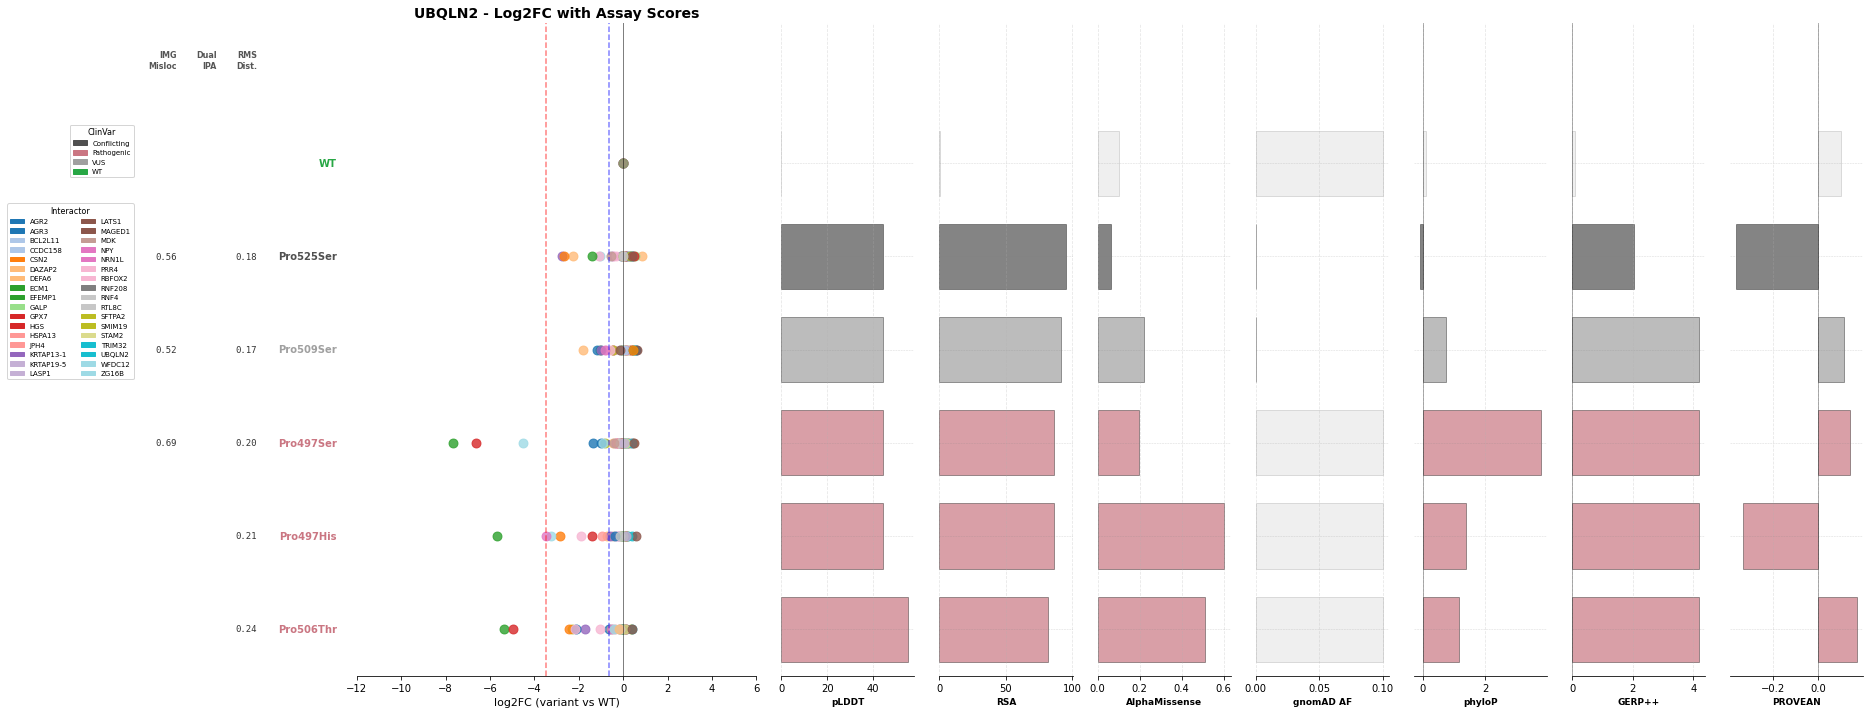

In [126]:
# Single gene plot with all annotations
fig, axes = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='UBQLN2',
    orf_distances=orf_distances,
    all_assay_df=all_assay_df,
    palette_dict=palette_dict,
    save_path='./tmp/test.pdf'
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


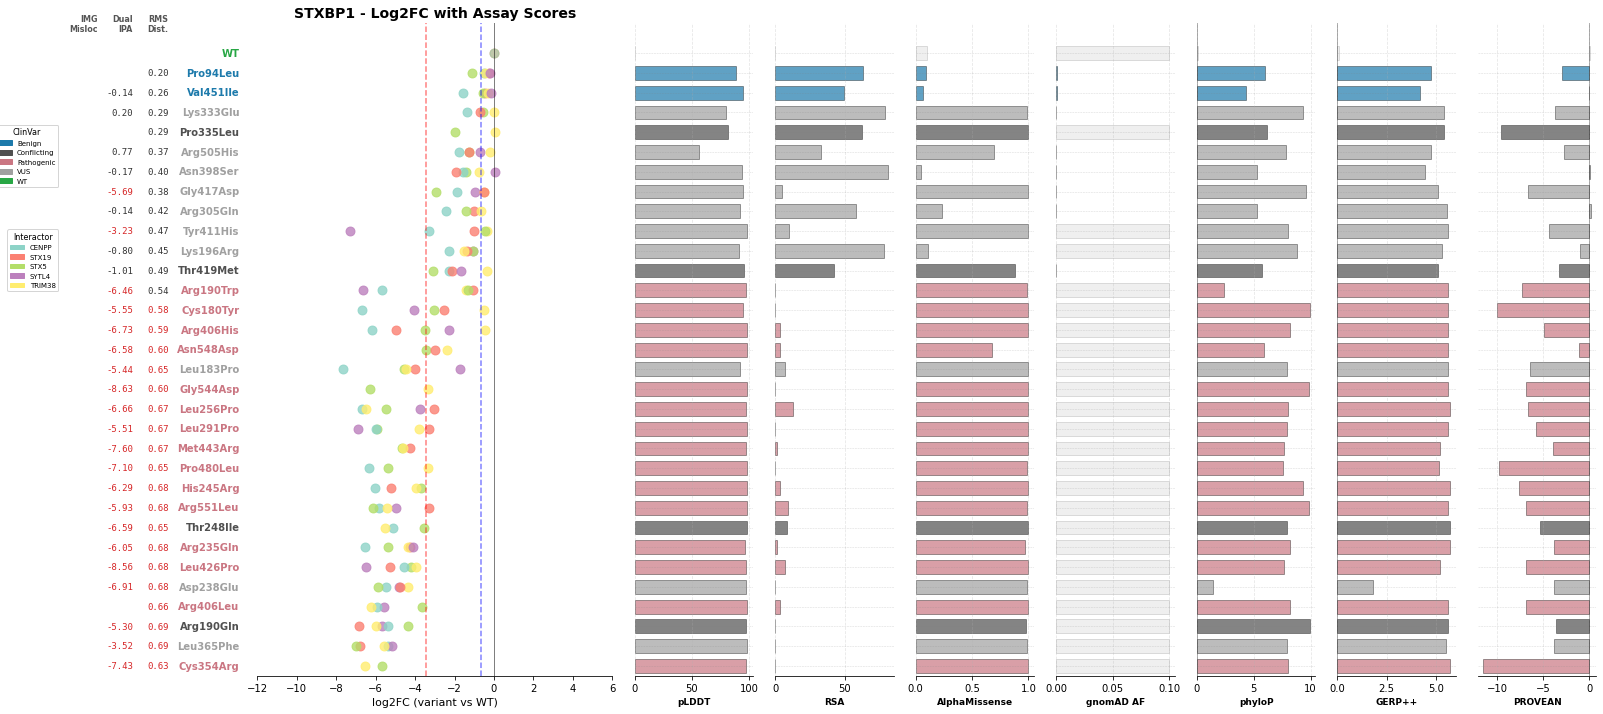

In [127]:
# Single gene plot with all annotations
fig, axes = plot_log2fc_panel(
    edge_df=edge_df,
    db_symbol='STXBP1',
    orf_distances=orf_distances,
    all_assay_df=all_assay_df,
    palette_dict=palette_dict
)

# Loop all genes and save plots

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PMP22_log2fc_panel.pdf


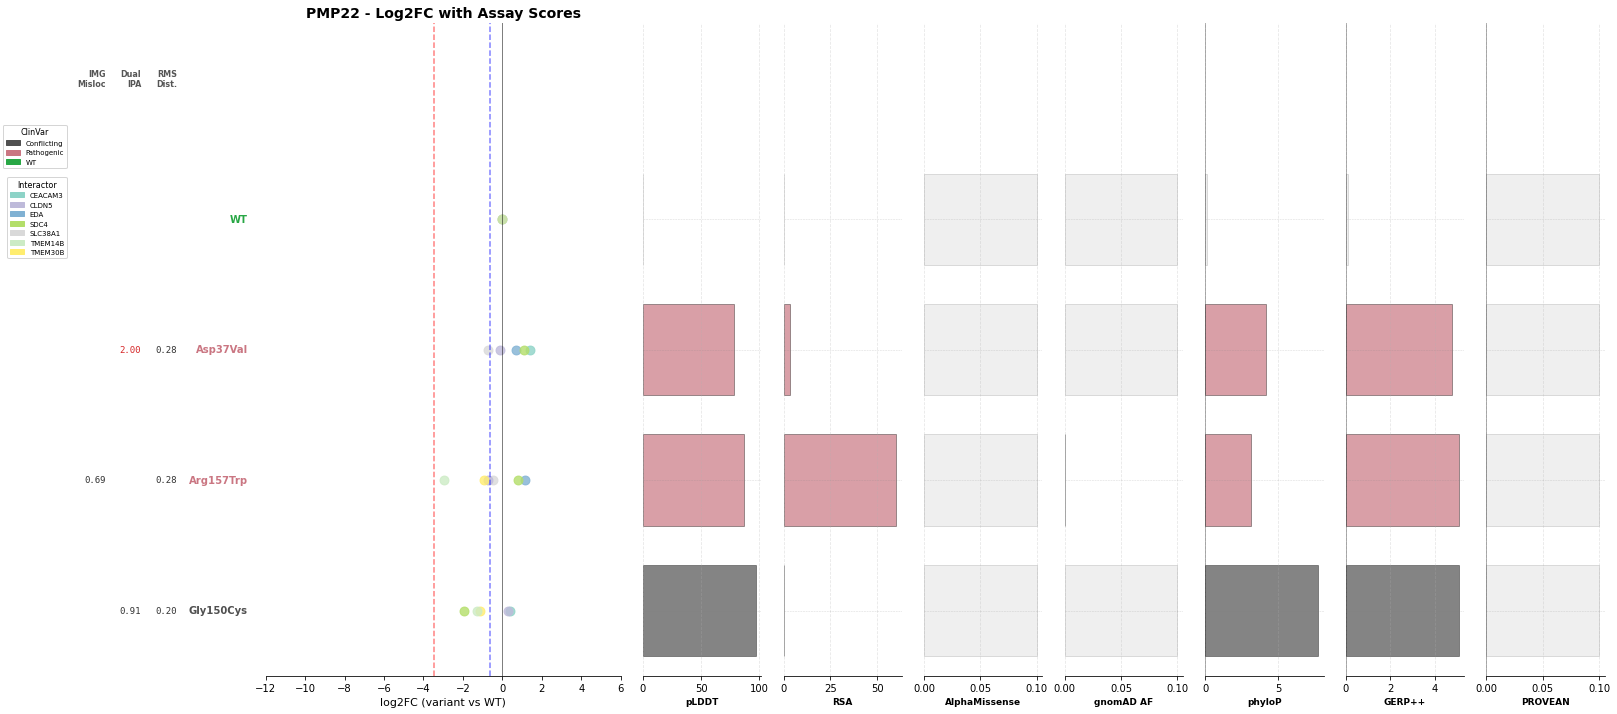

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/HMBS_log2fc_panel.pdf


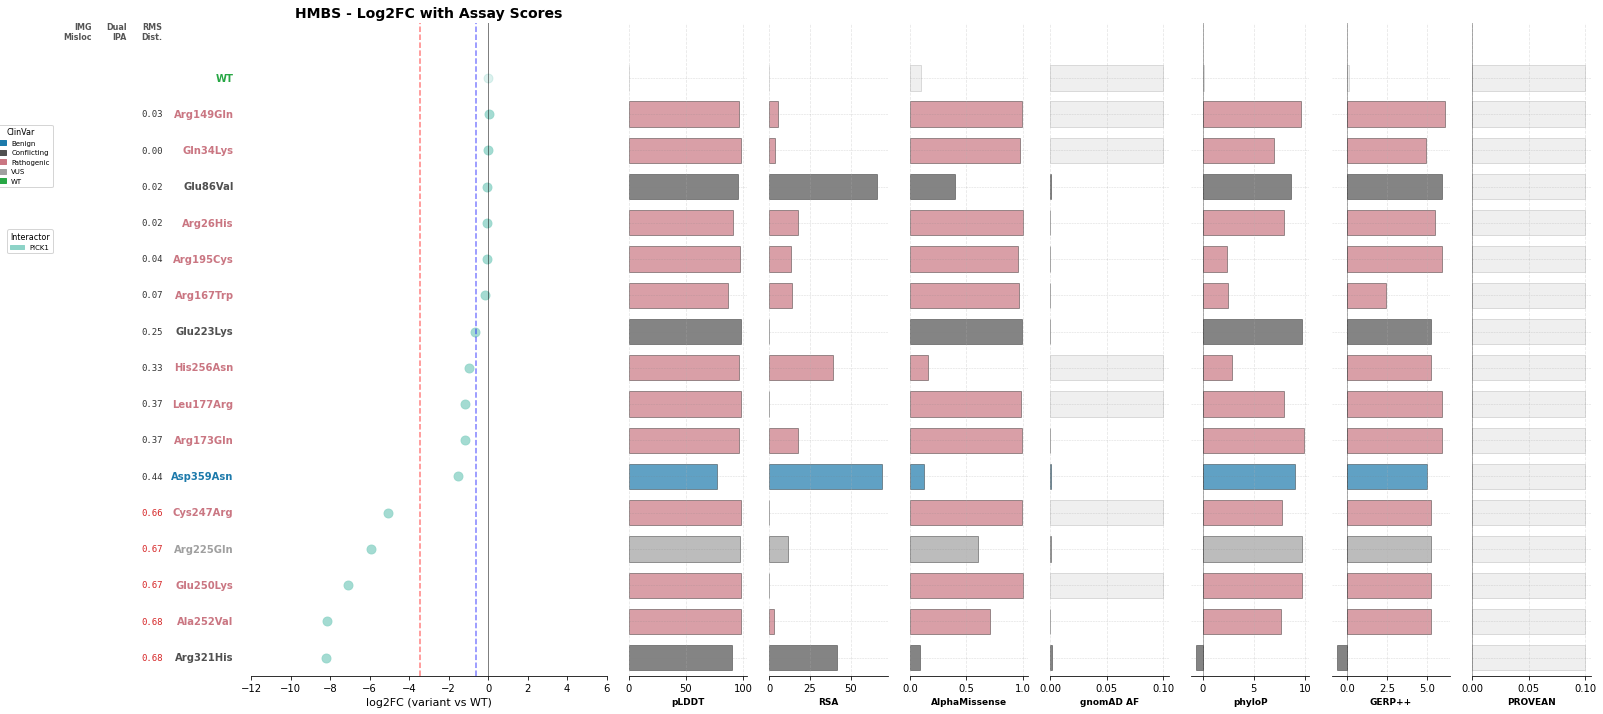

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SMARCB1_log2fc_panel.pdf


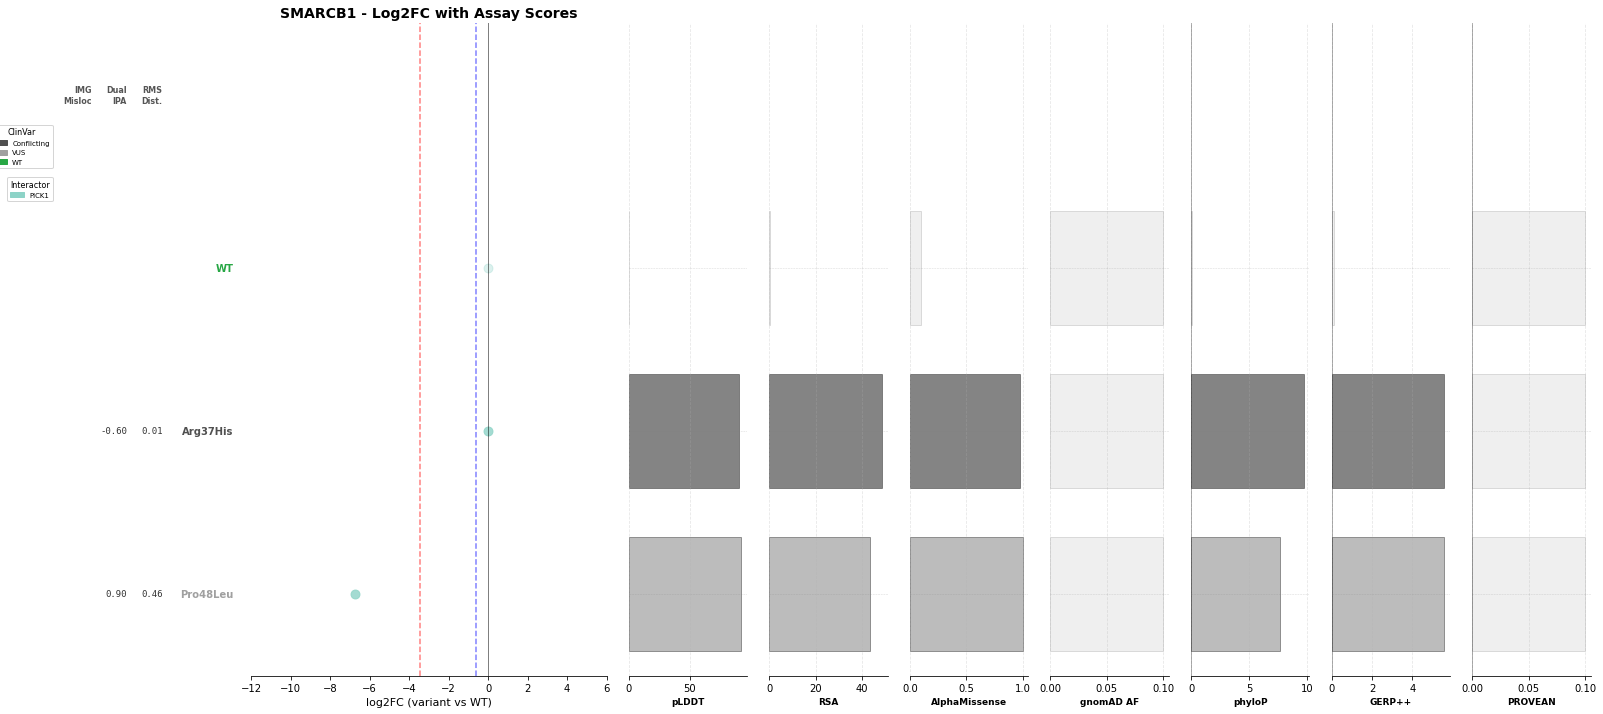

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PNKP_log2fc_panel.pdf


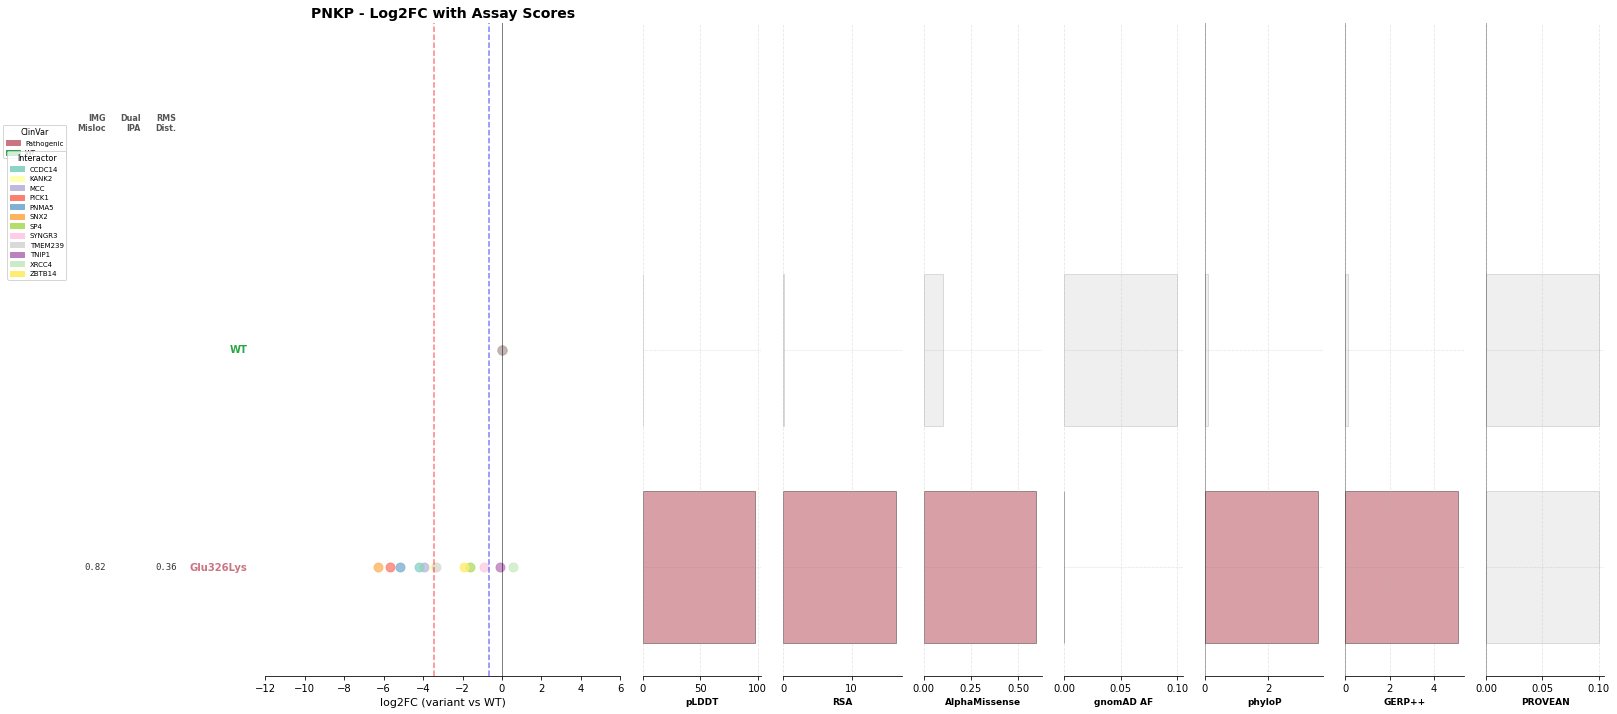

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KCTD7_log2fc_panel.pdf


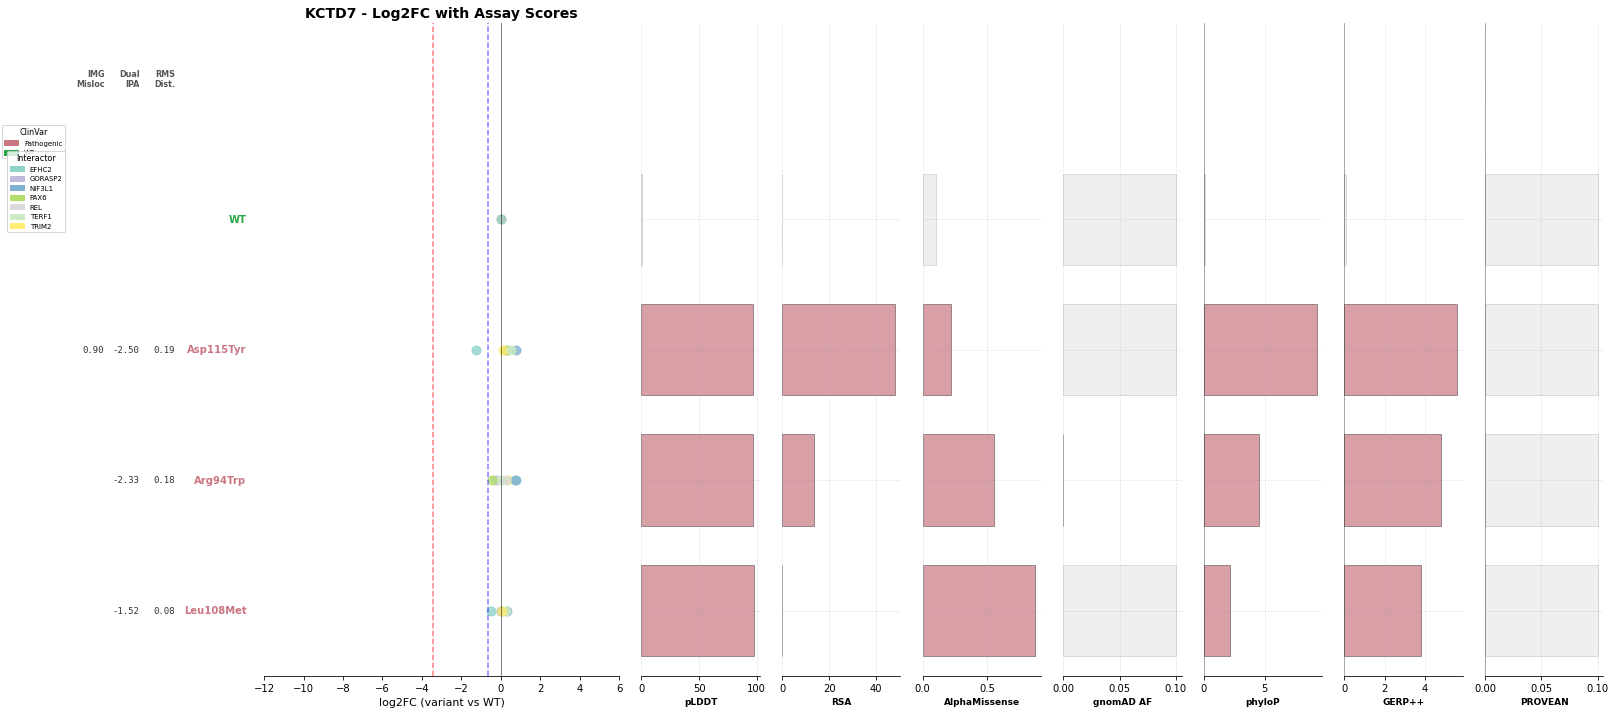

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/UROD_log2fc_panel.pdf


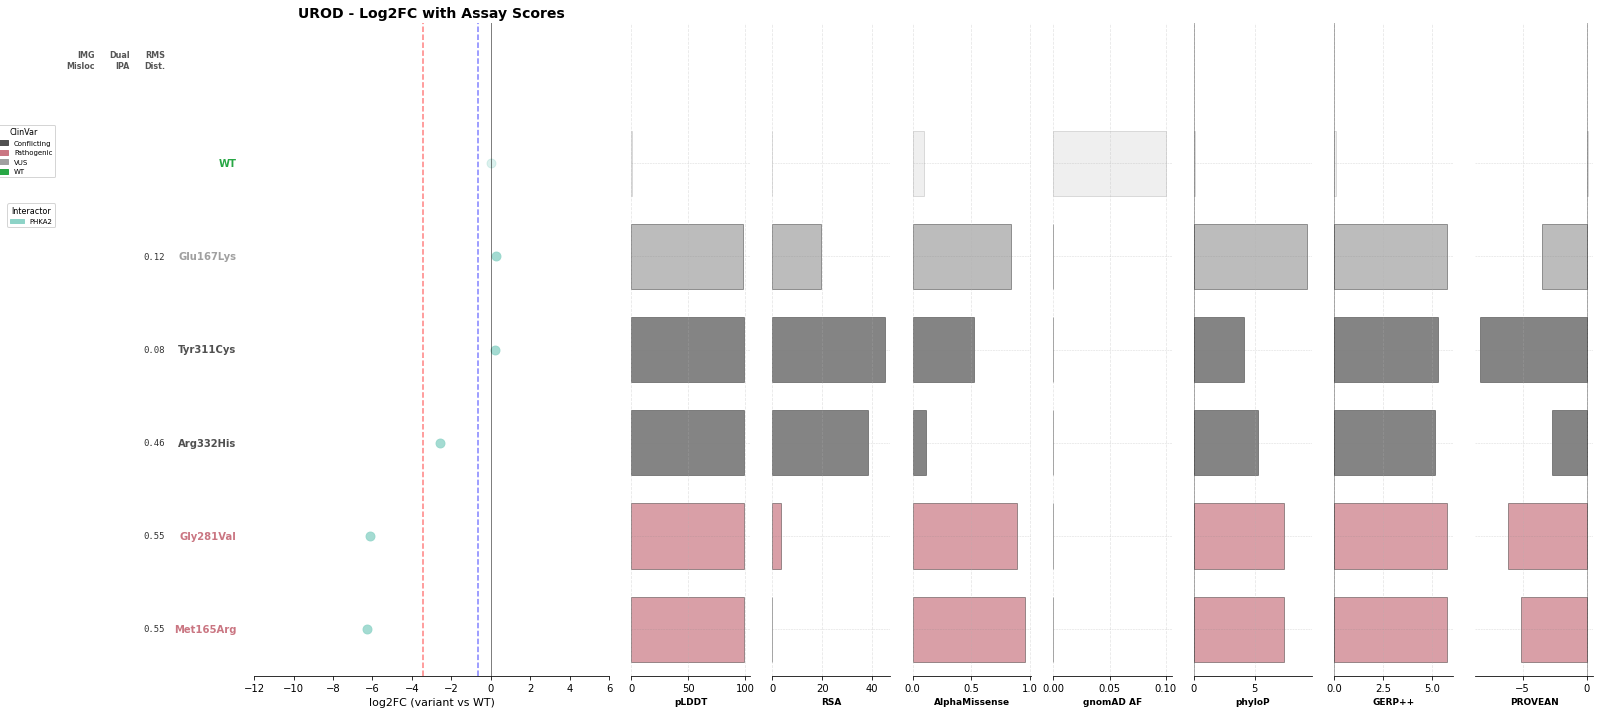

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PITX2_log2fc_panel.pdf


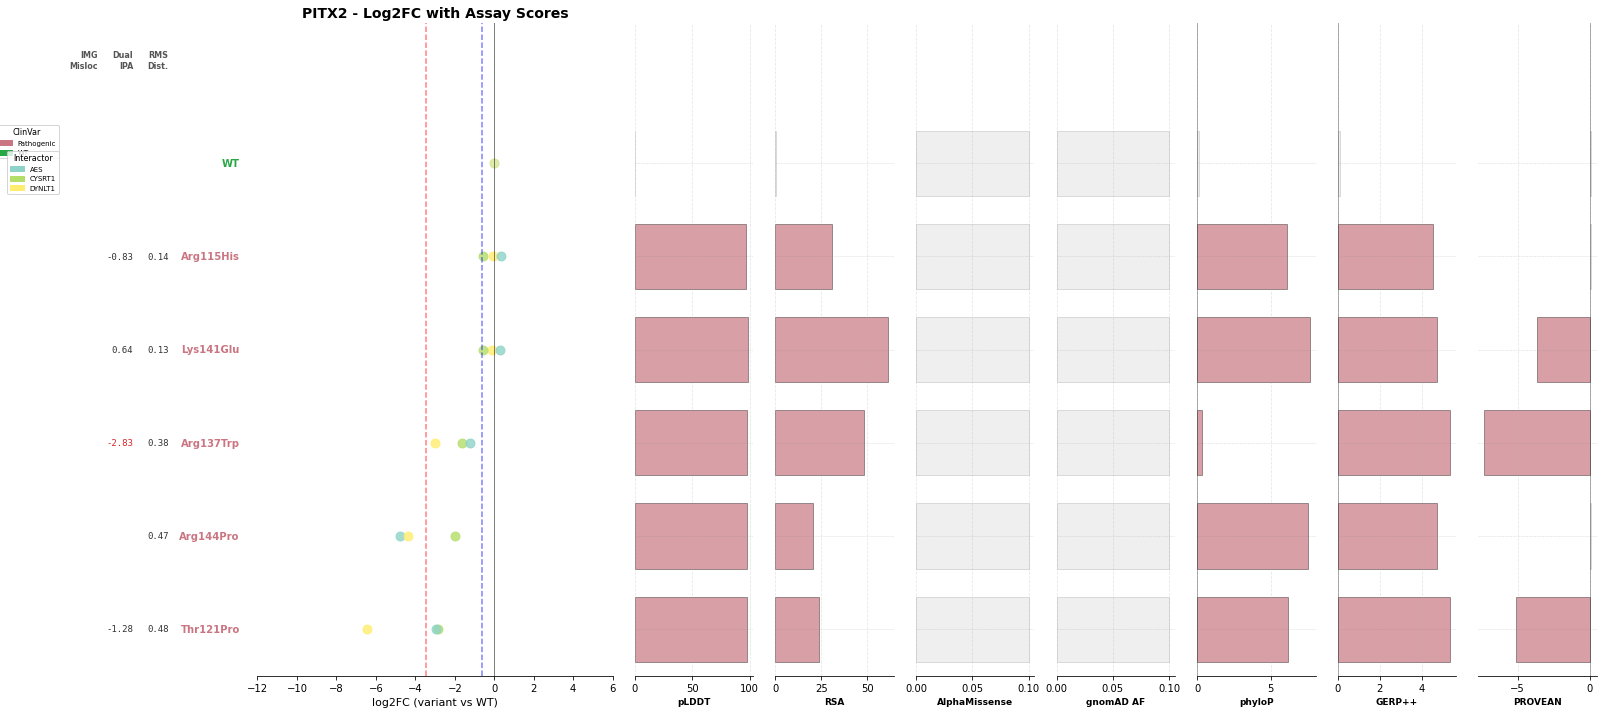

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/UBQLN2_log2fc_panel.pdf


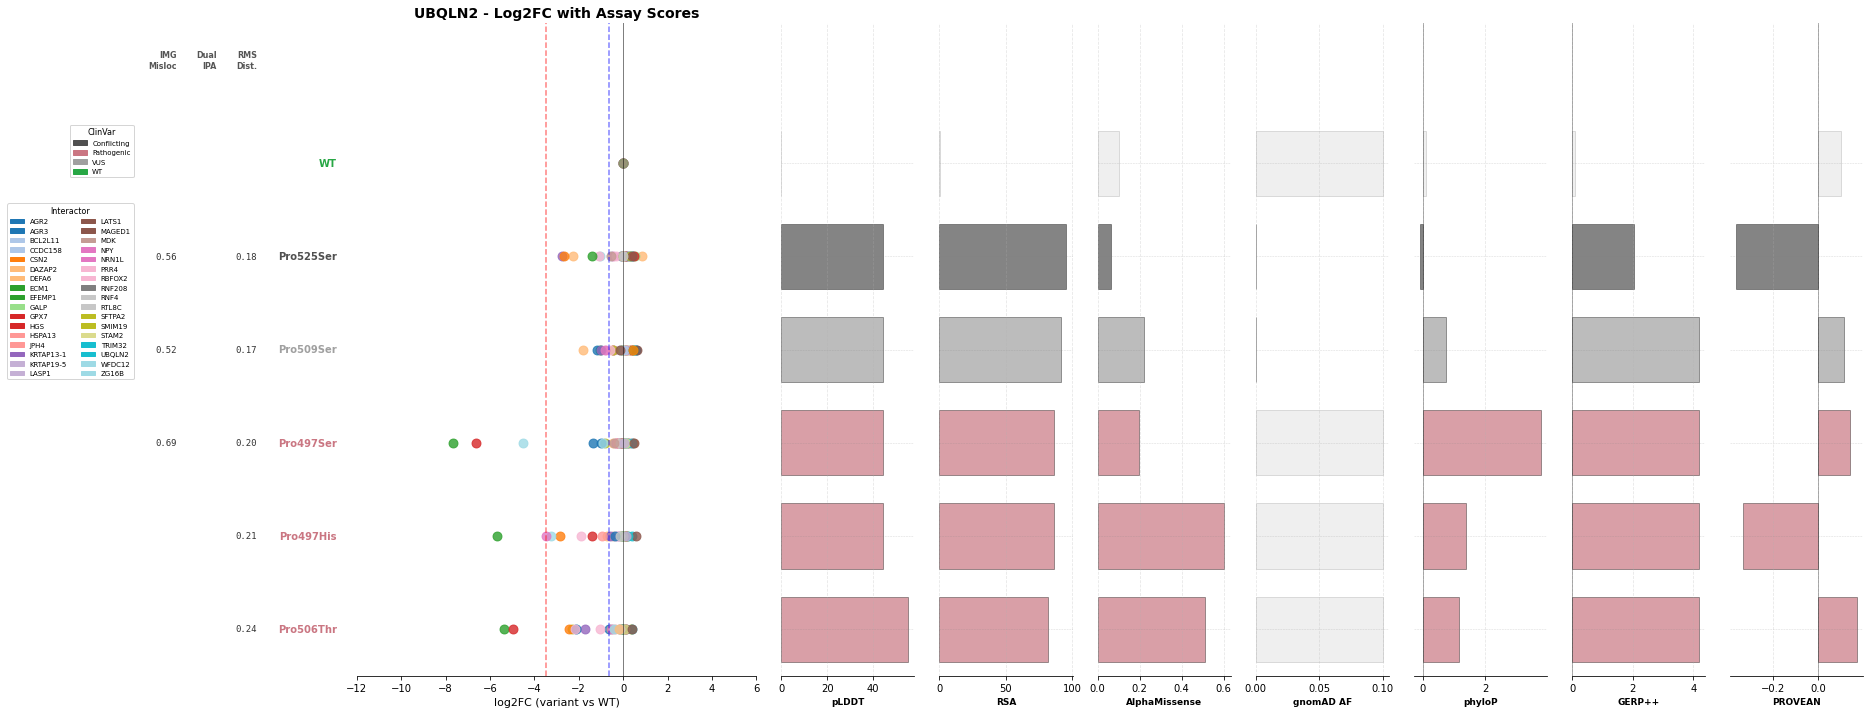

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT86_log2fc_panel.pdf


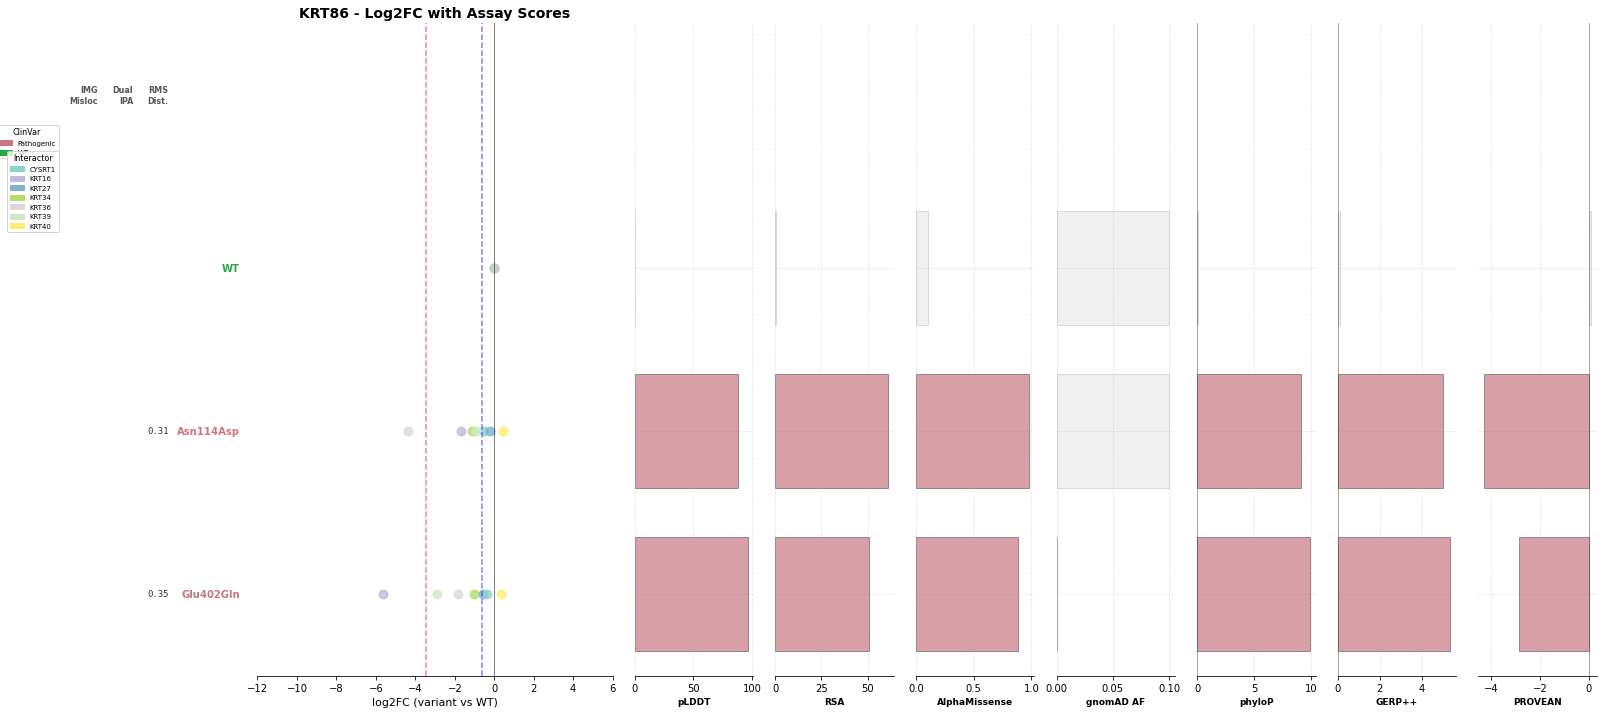

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT8_log2fc_panel.pdf


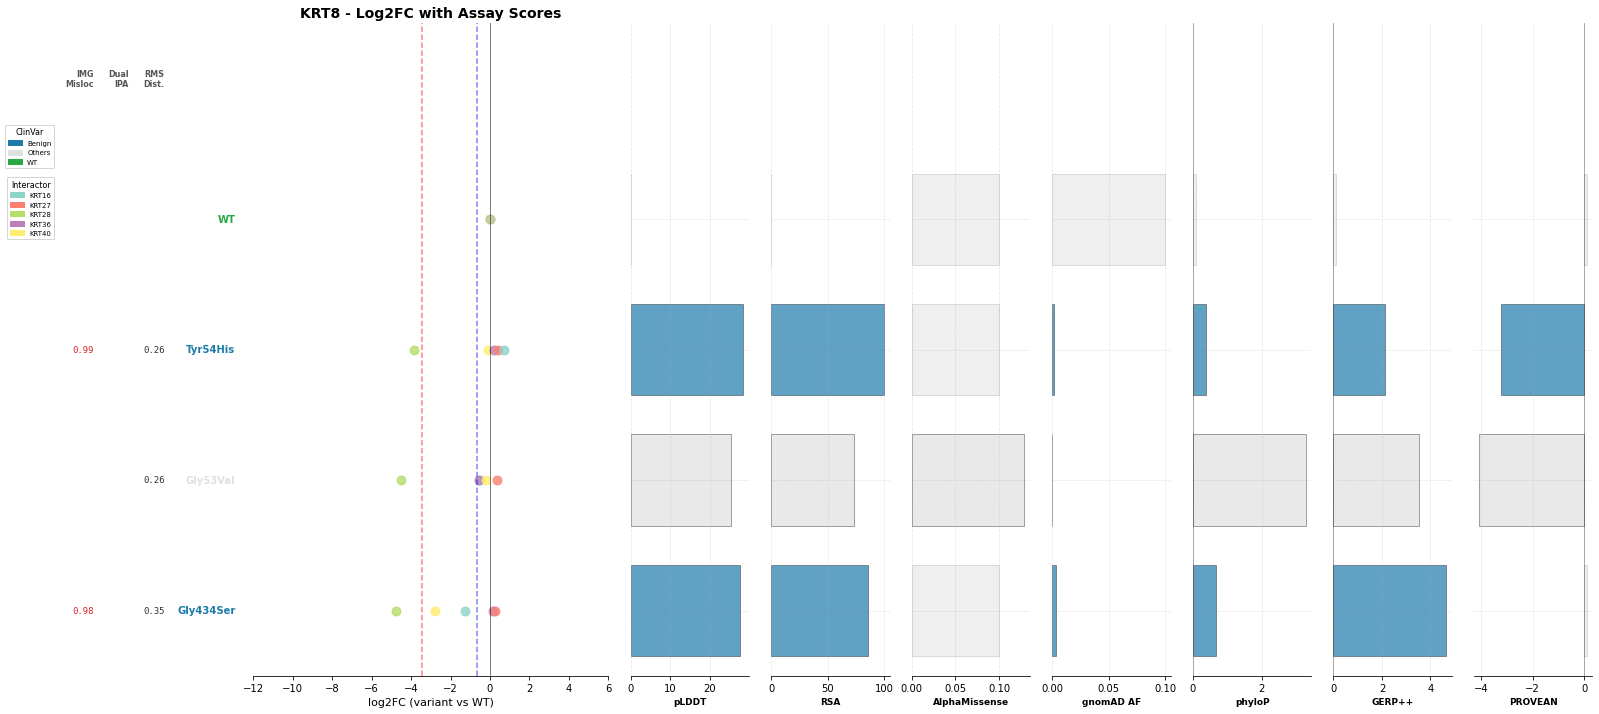

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT5_log2fc_panel.pdf


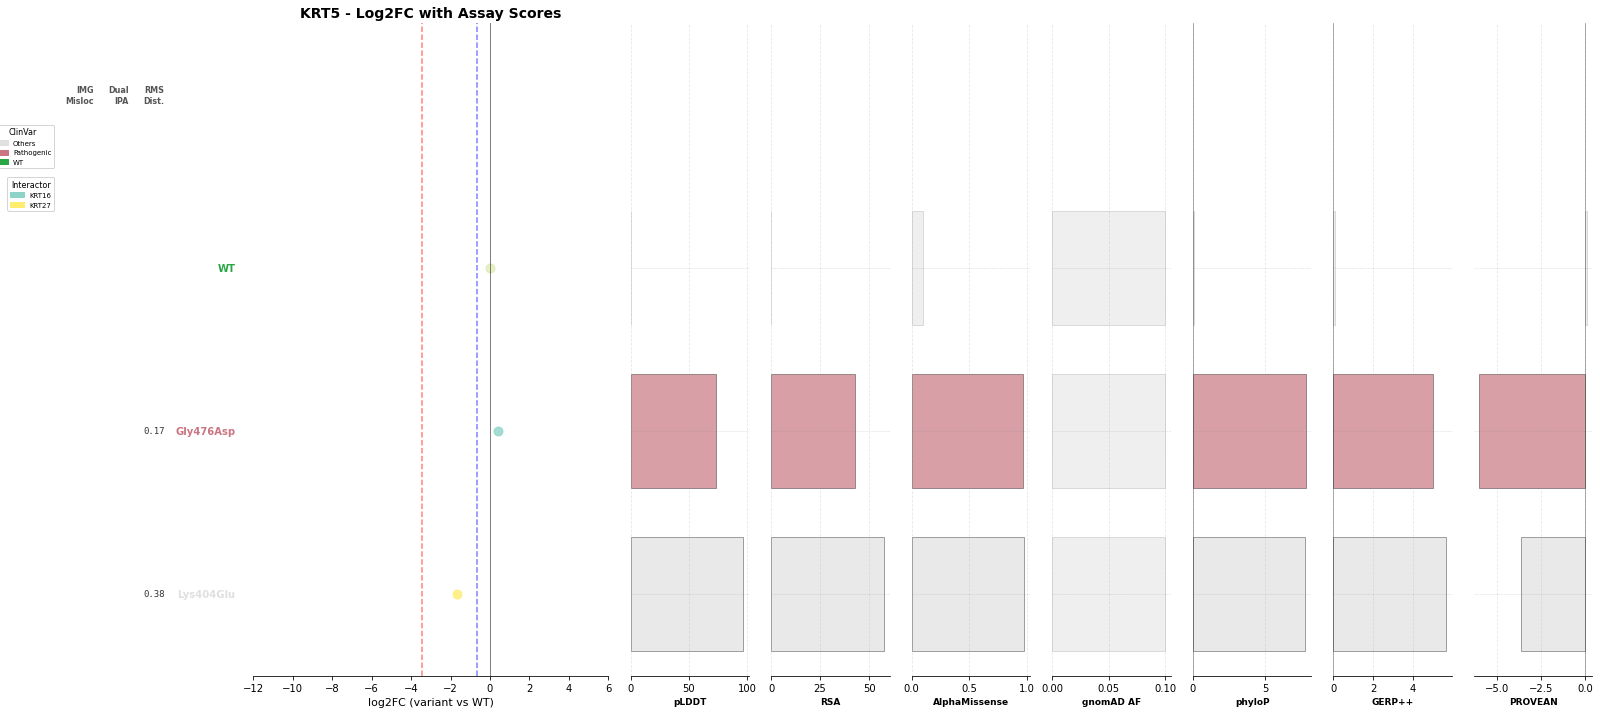

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT6A_log2fc_panel.pdf


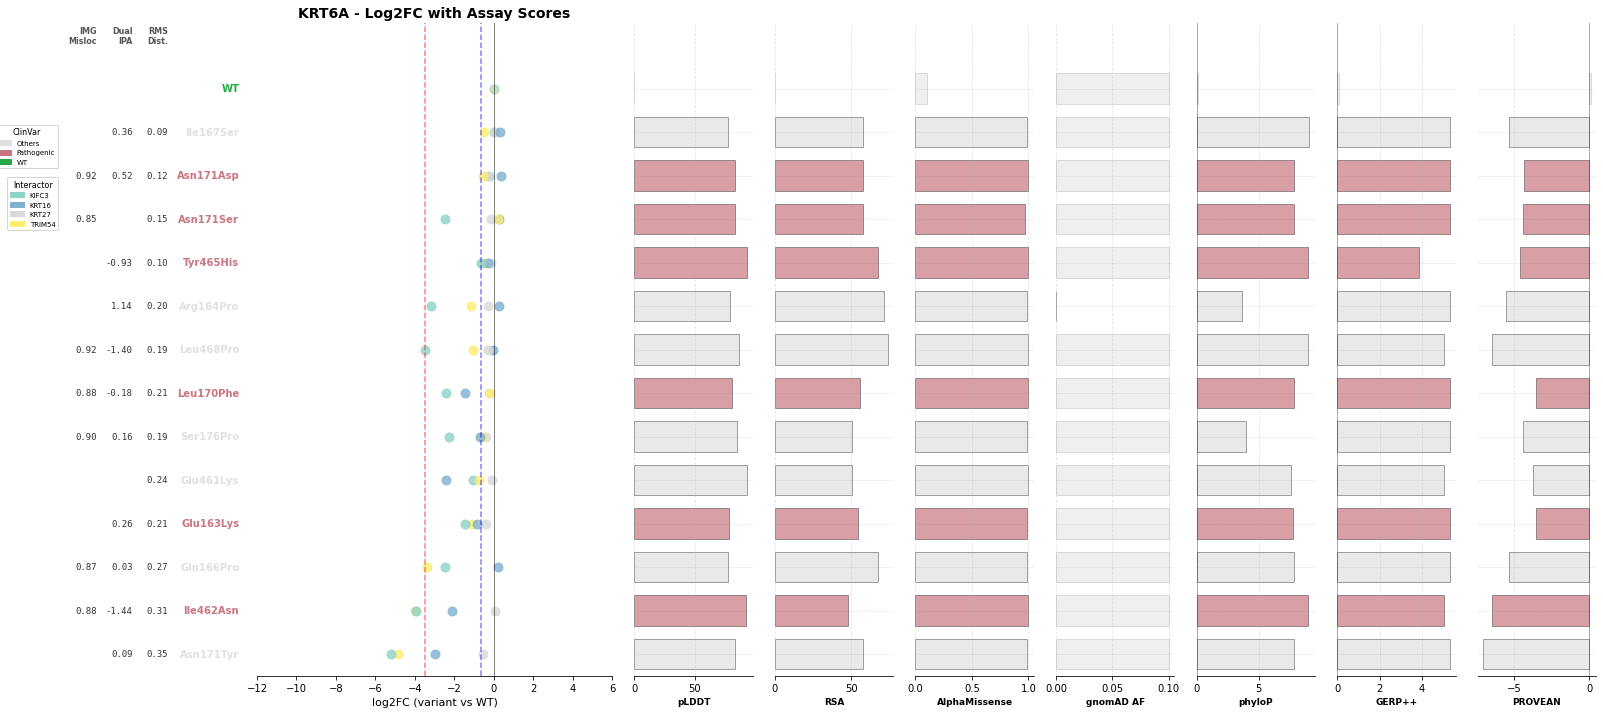

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KRT2_log2fc_panel.pdf


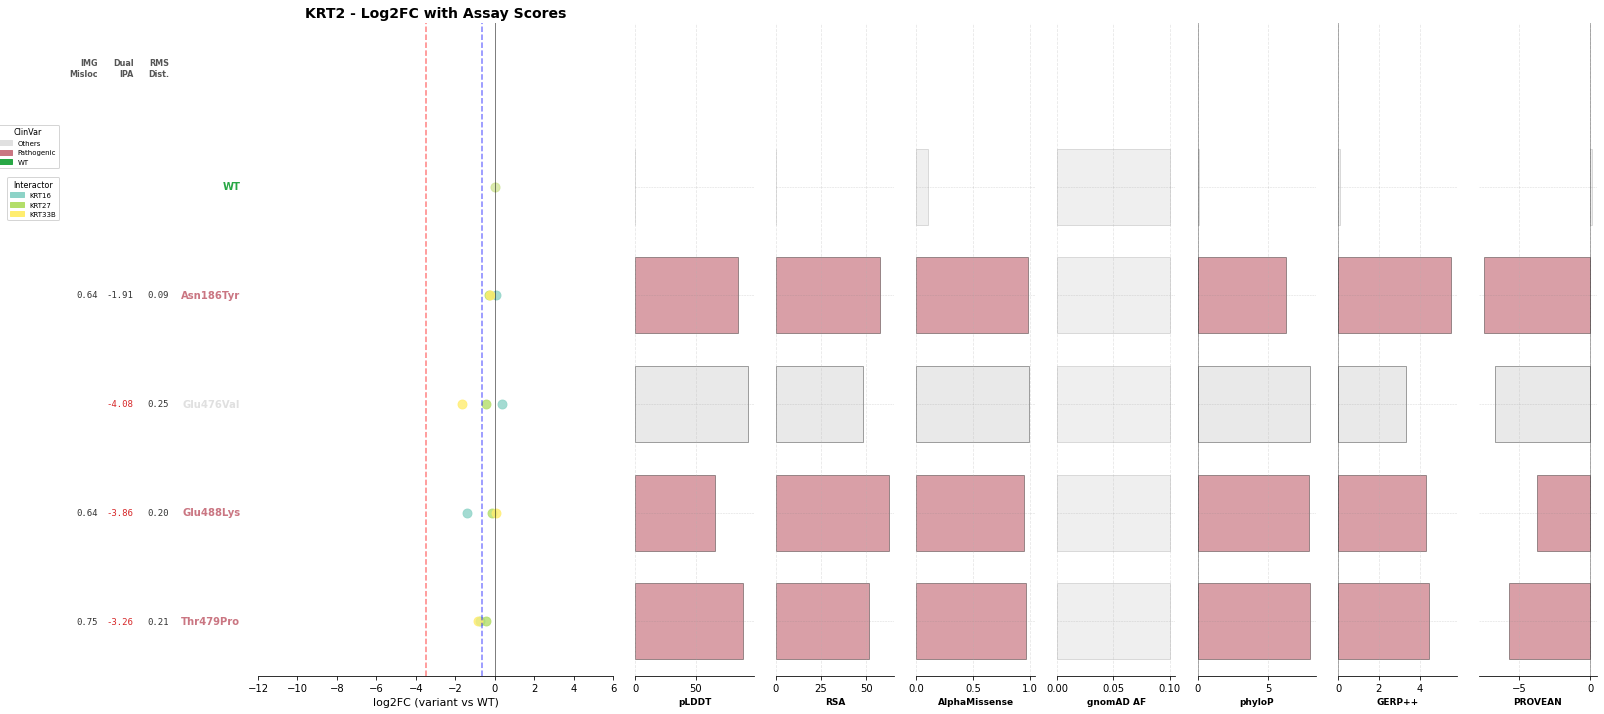

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GRN_log2fc_panel.pdf


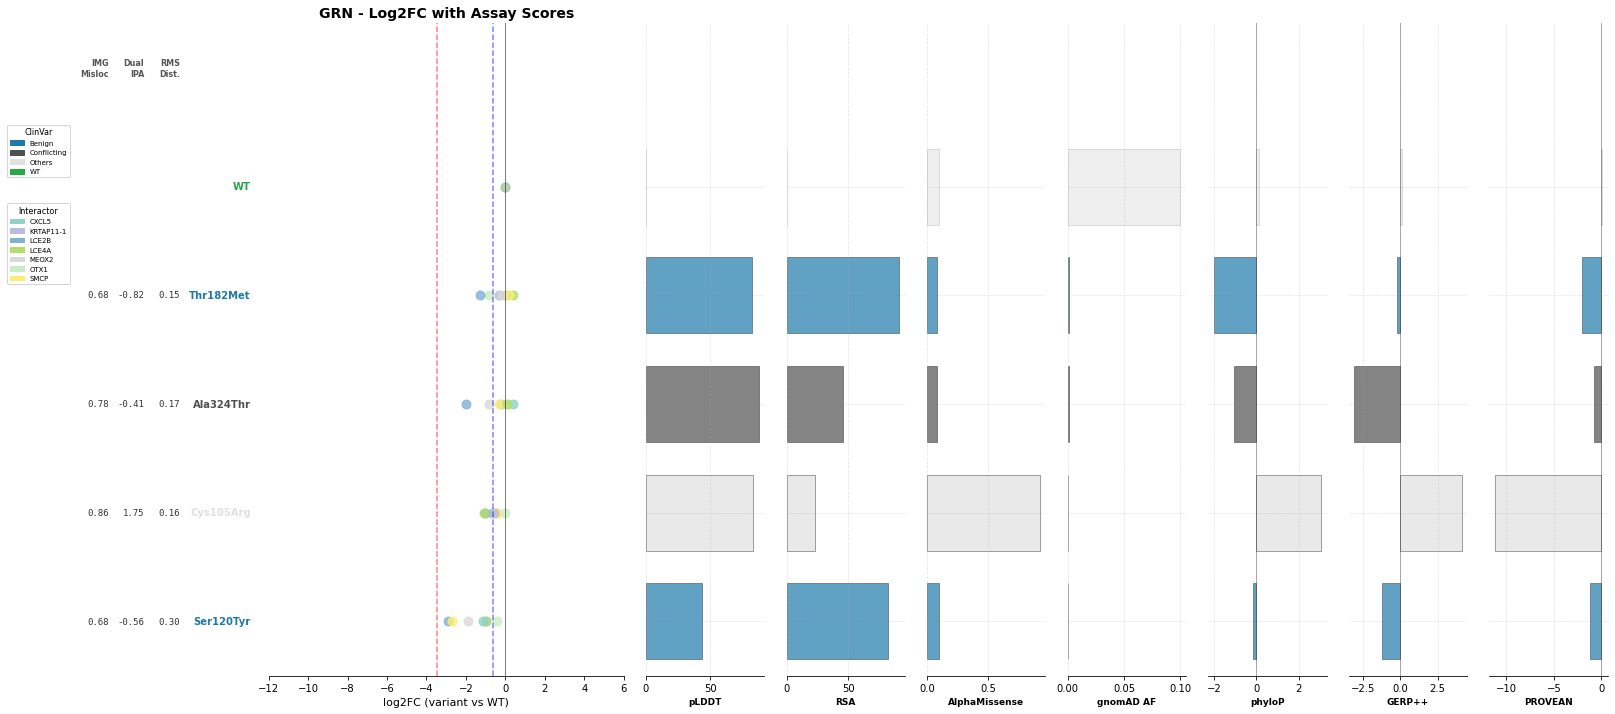

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KCNJ2_log2fc_panel.pdf


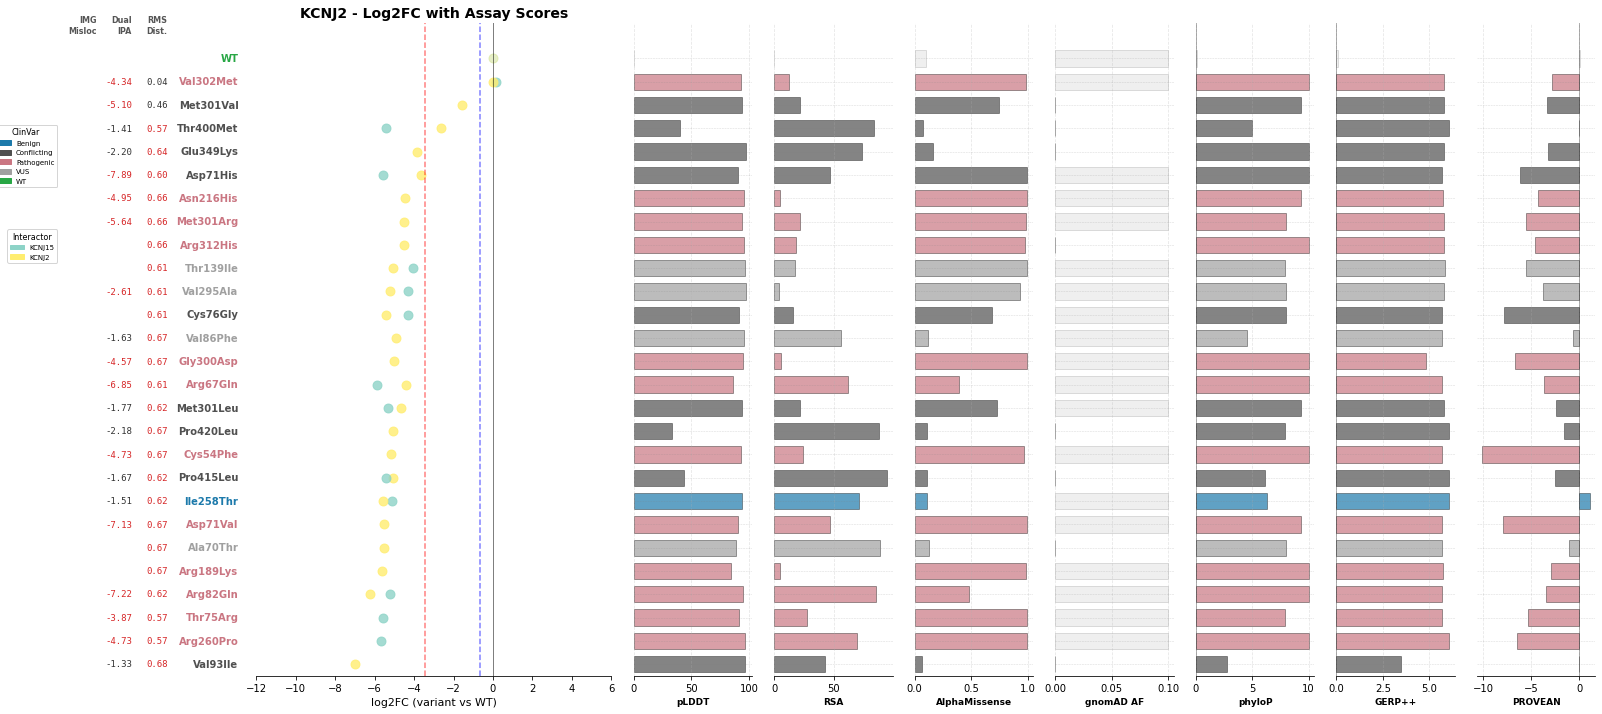

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/IER3IP1_log2fc_panel.pdf


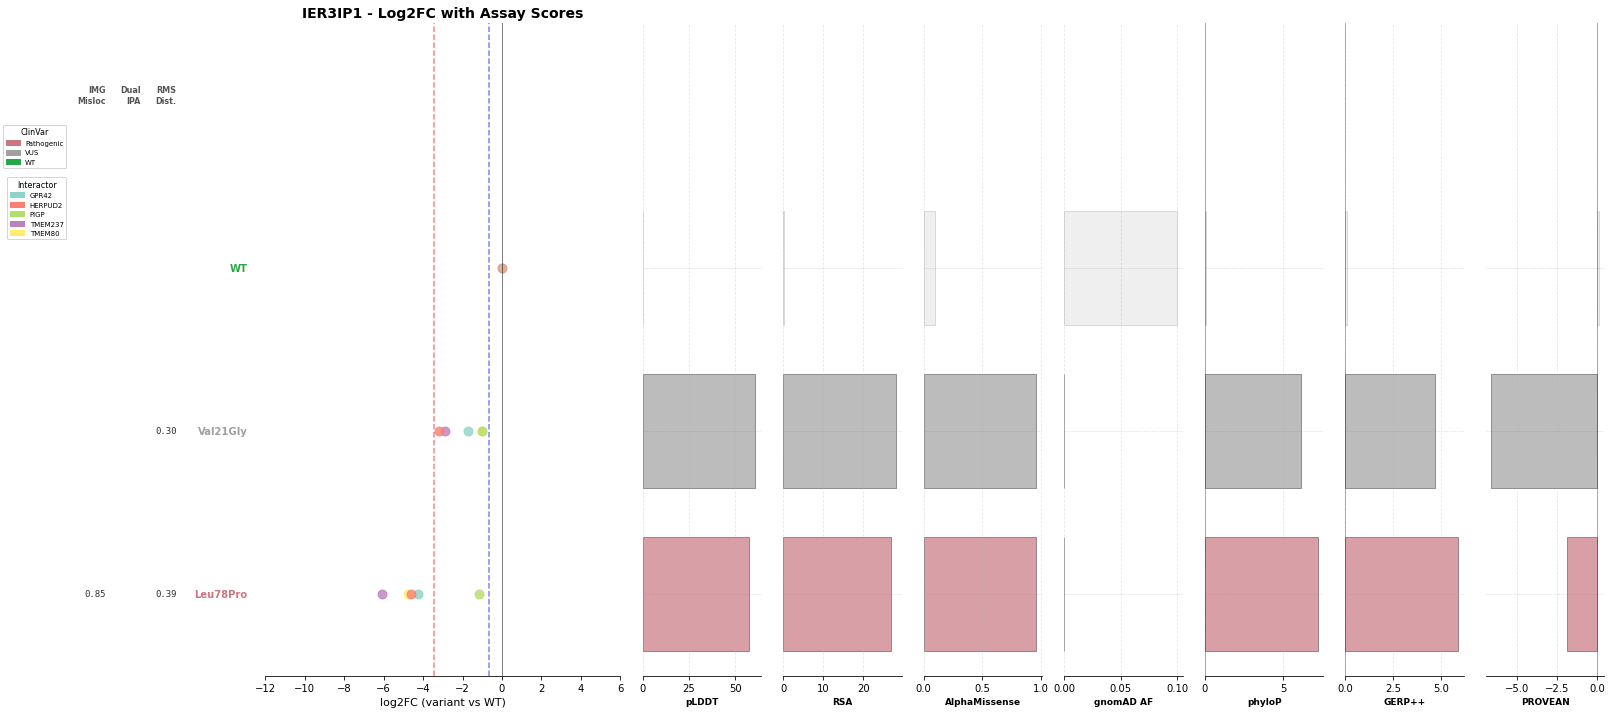

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/EMD_log2fc_panel.pdf


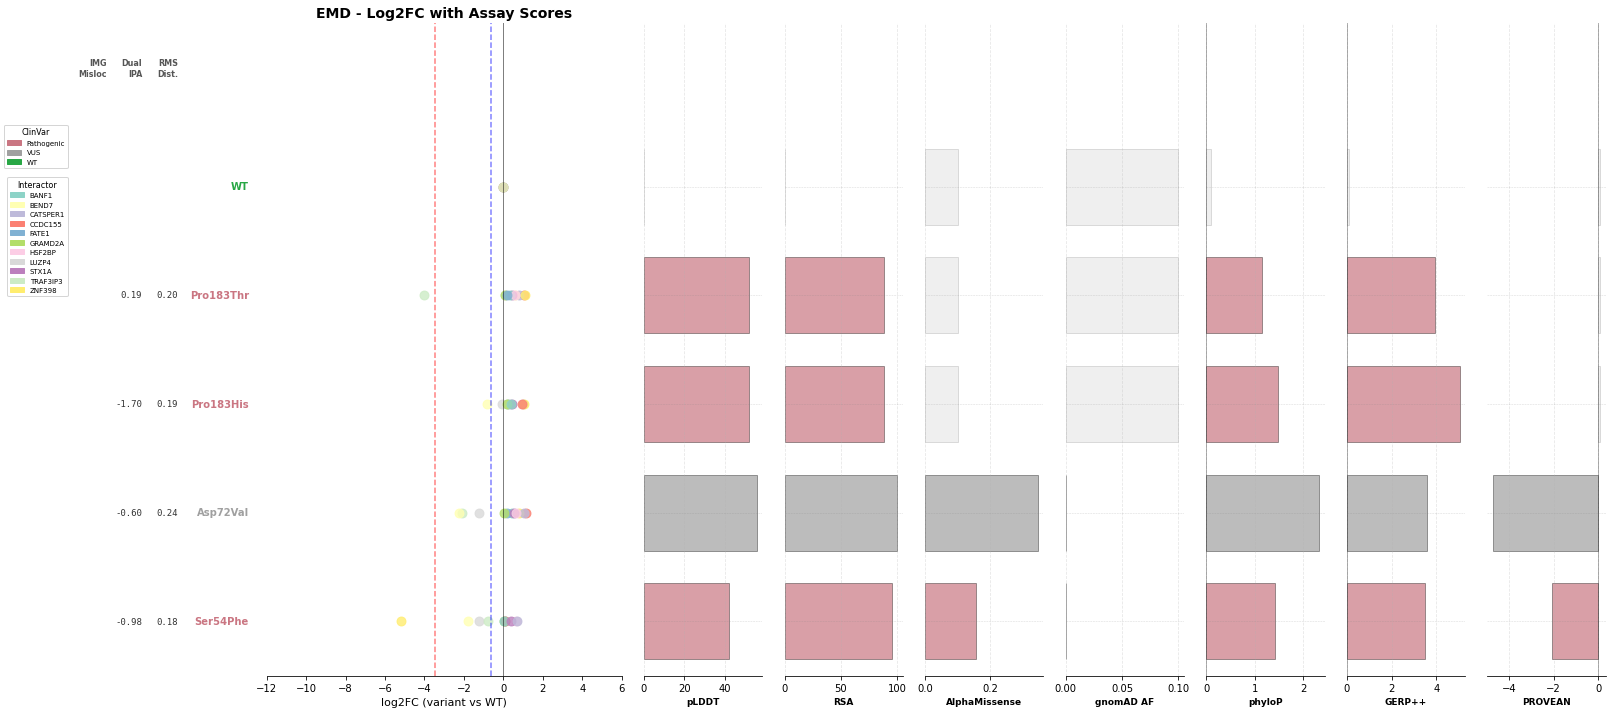

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SUOX_log2fc_panel.pdf


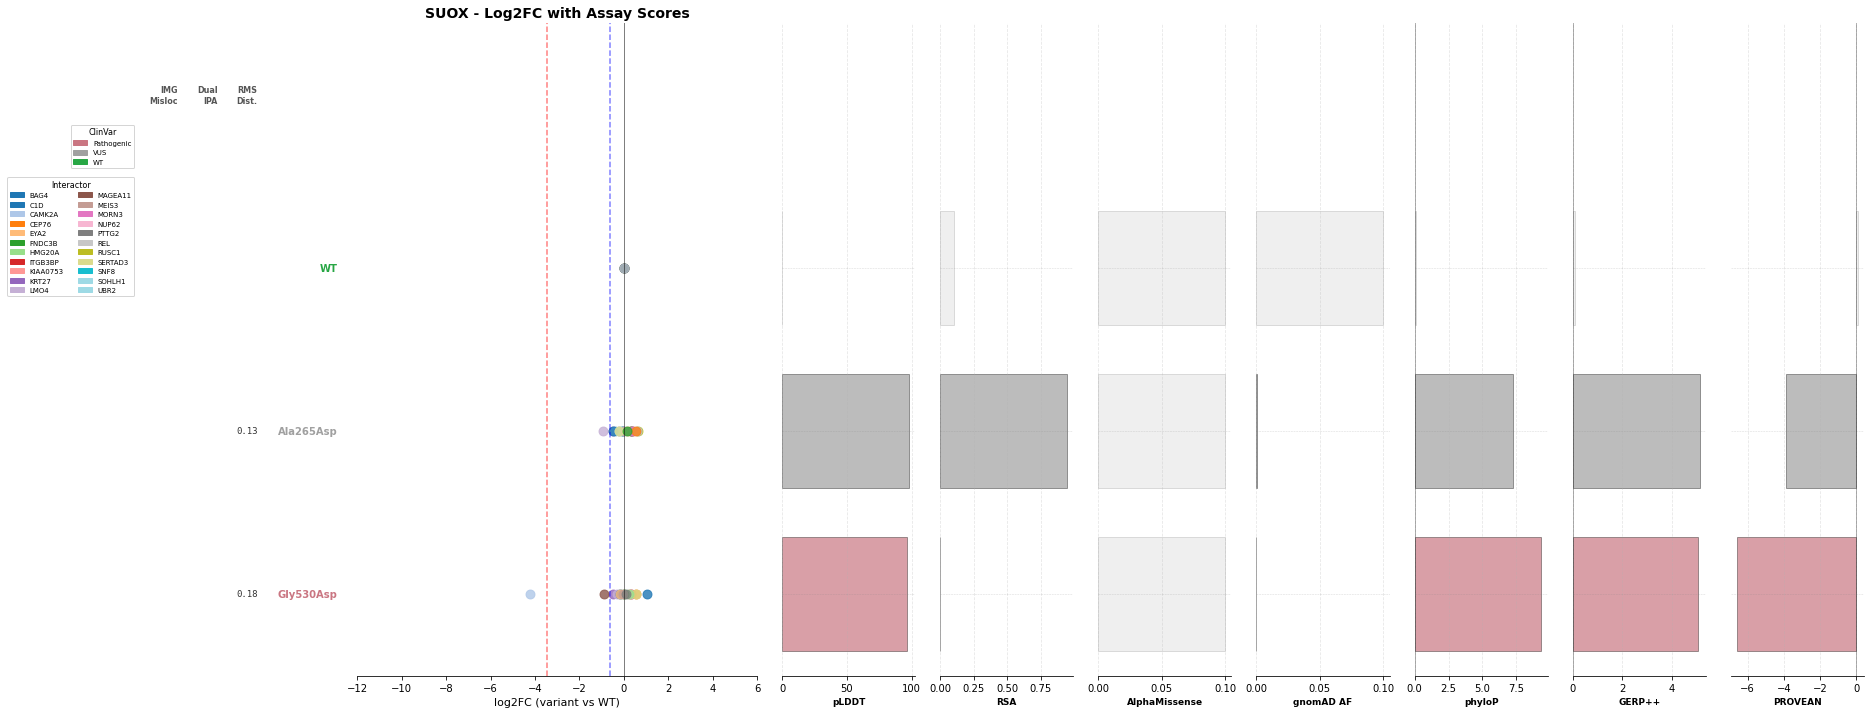

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PCCA_log2fc_panel.pdf


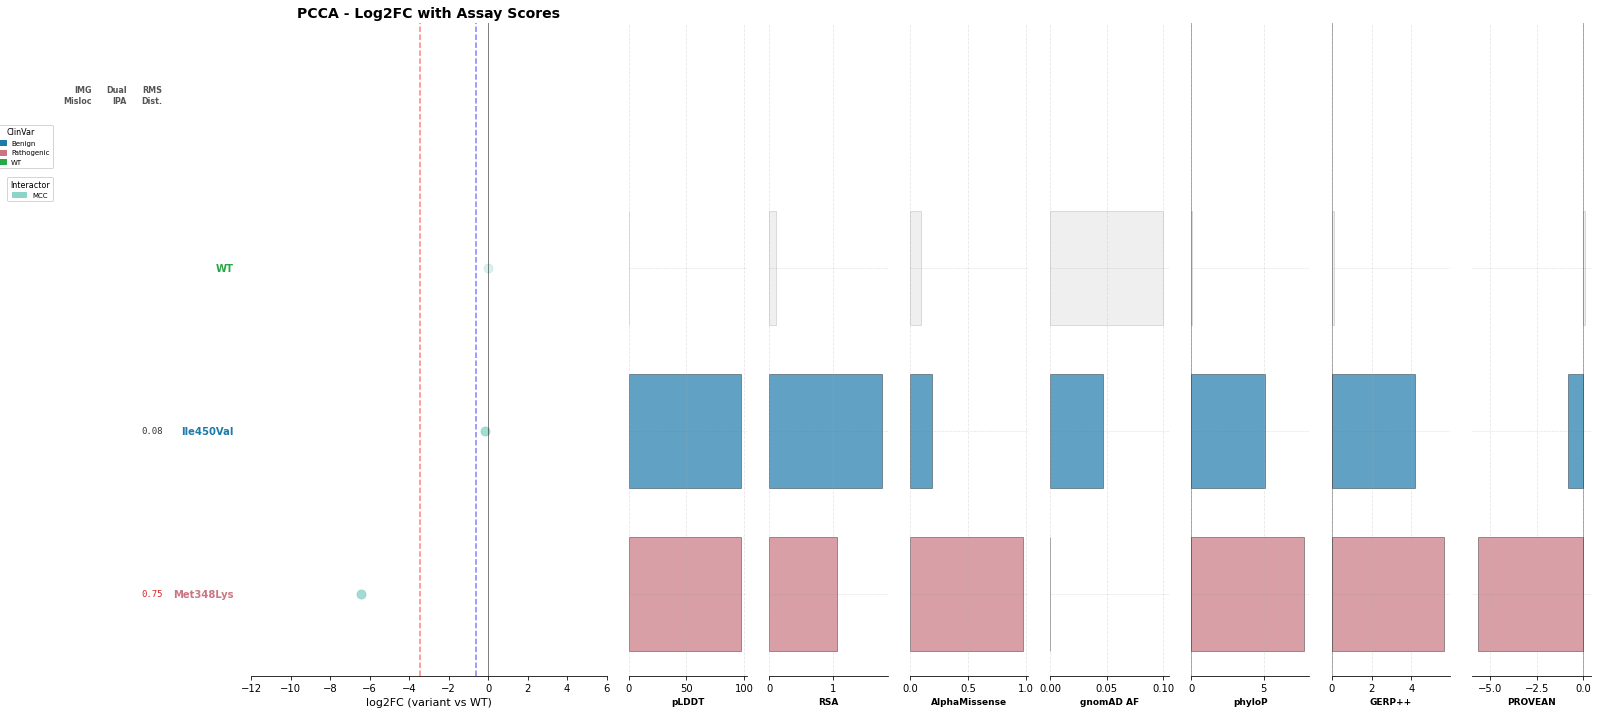

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PRKAR1A_log2fc_panel.pdf


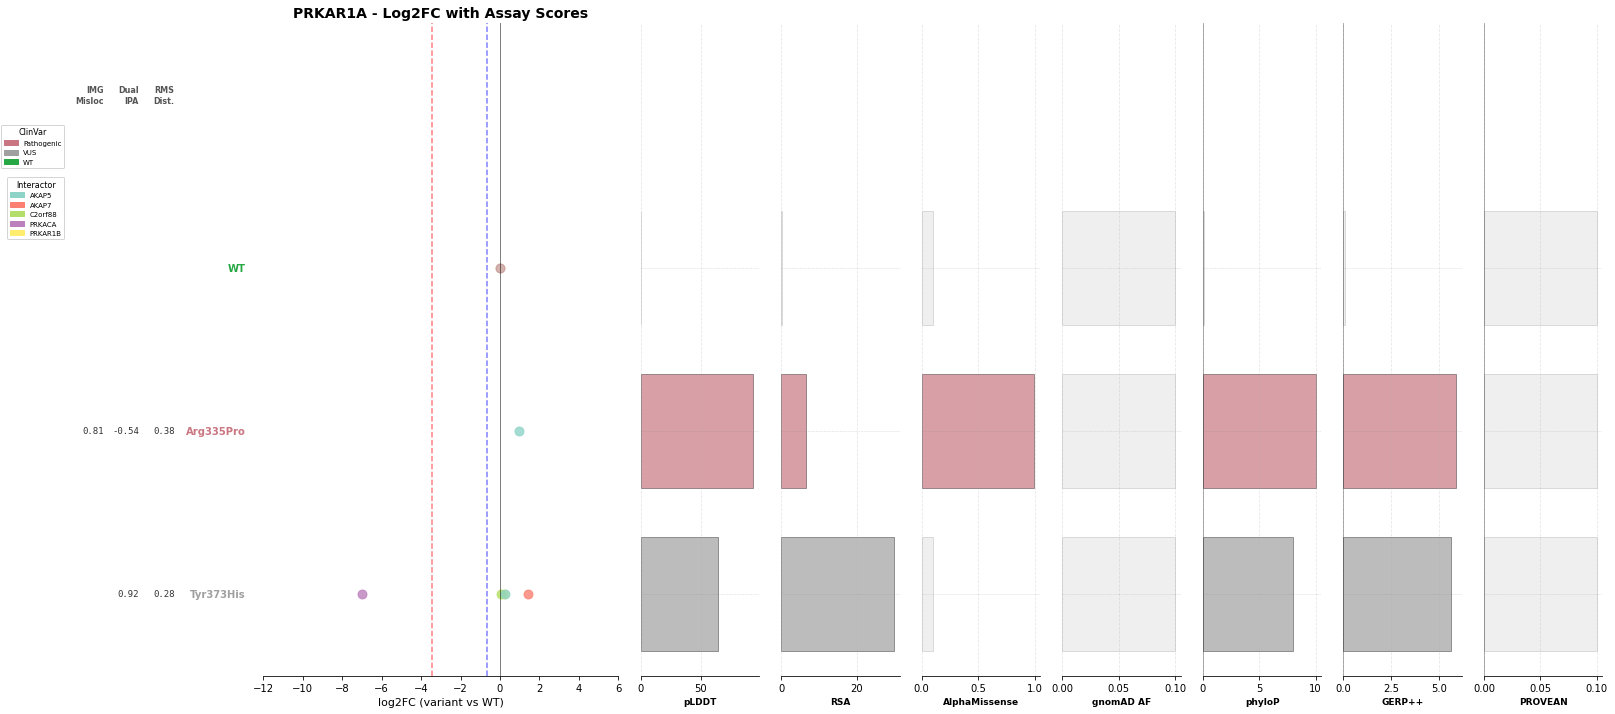

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/VHL_log2fc_panel.pdf


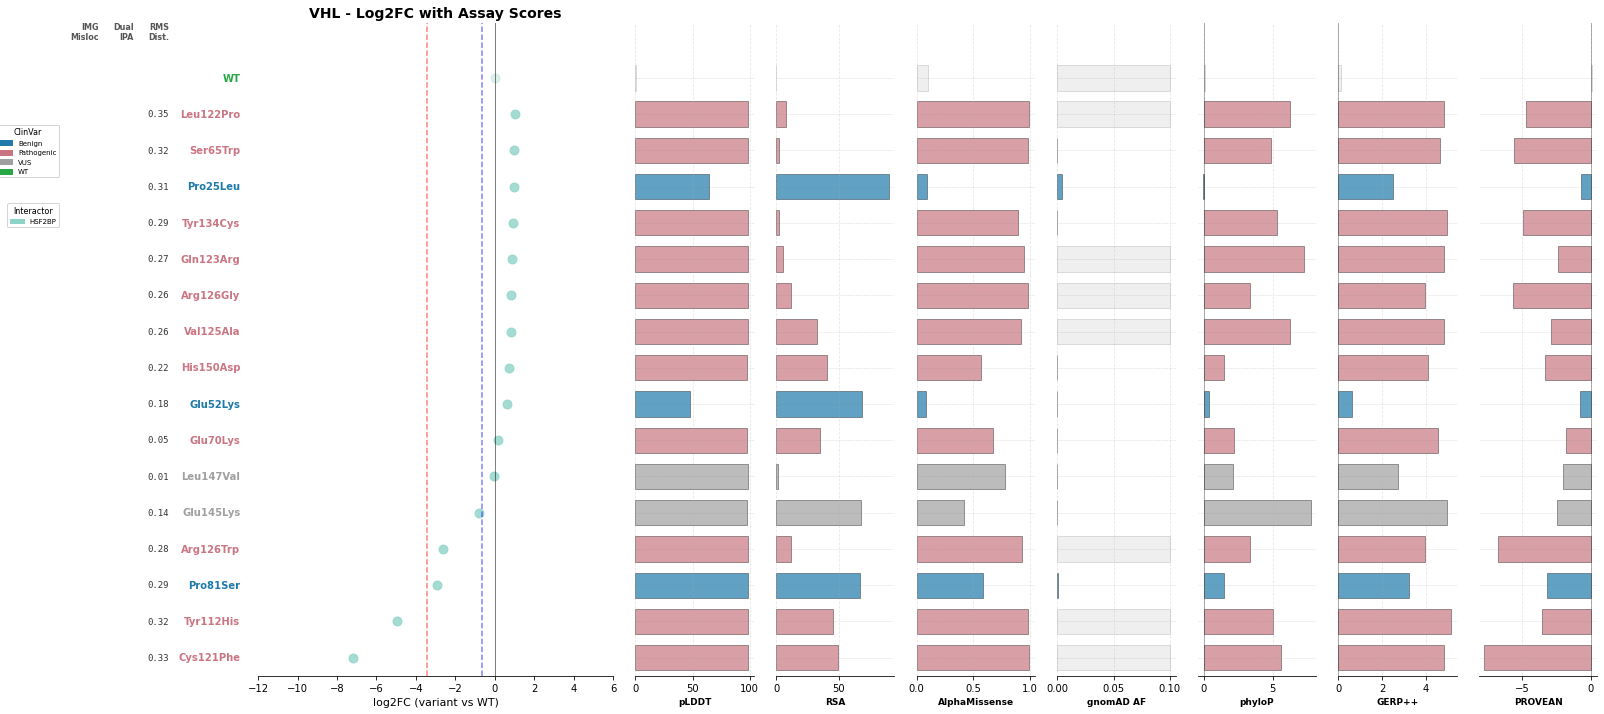

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/IMPDH1_log2fc_panel.pdf


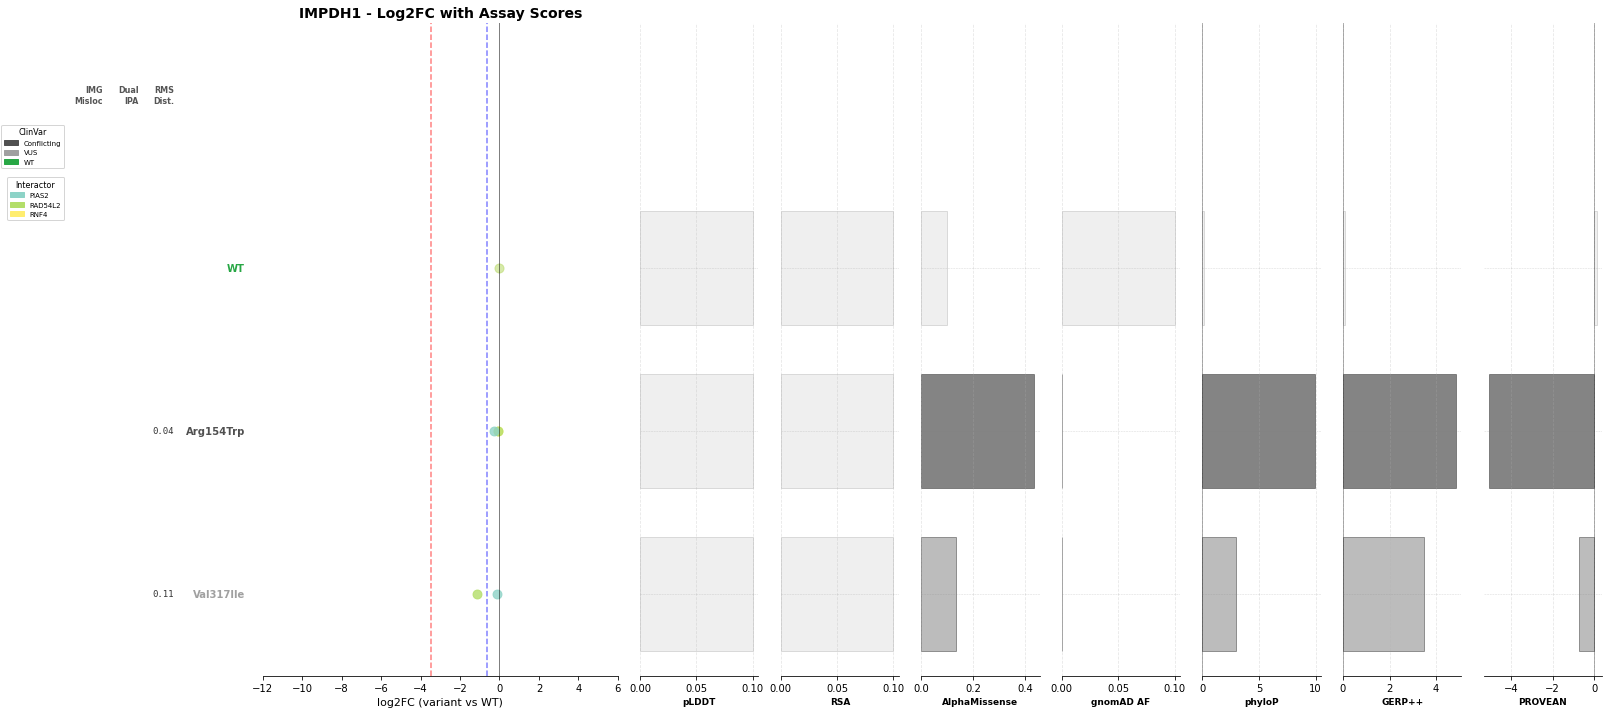

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/BAG3_log2fc_panel.pdf


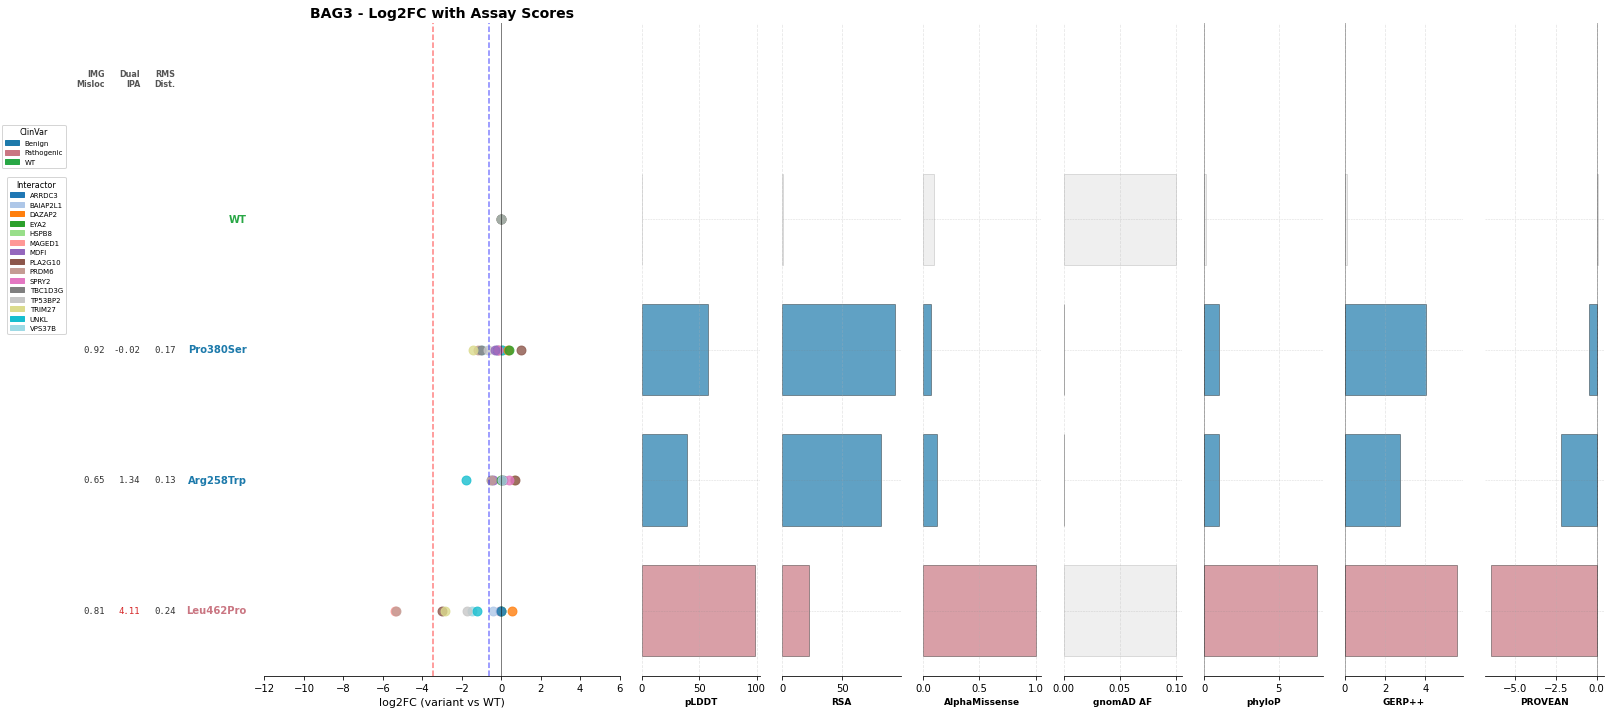

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/LITAF_log2fc_panel.pdf


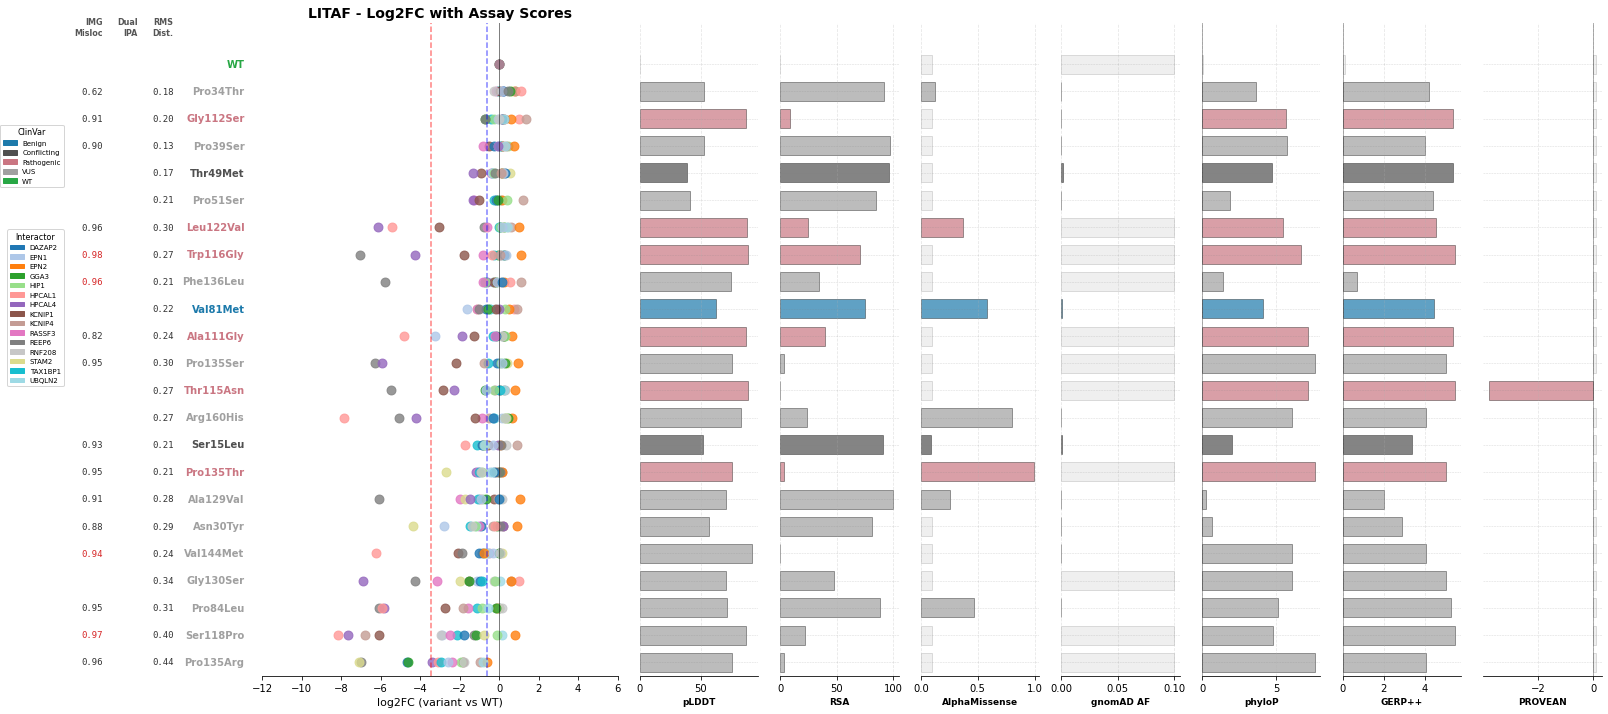

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/IL36RN_log2fc_panel.pdf


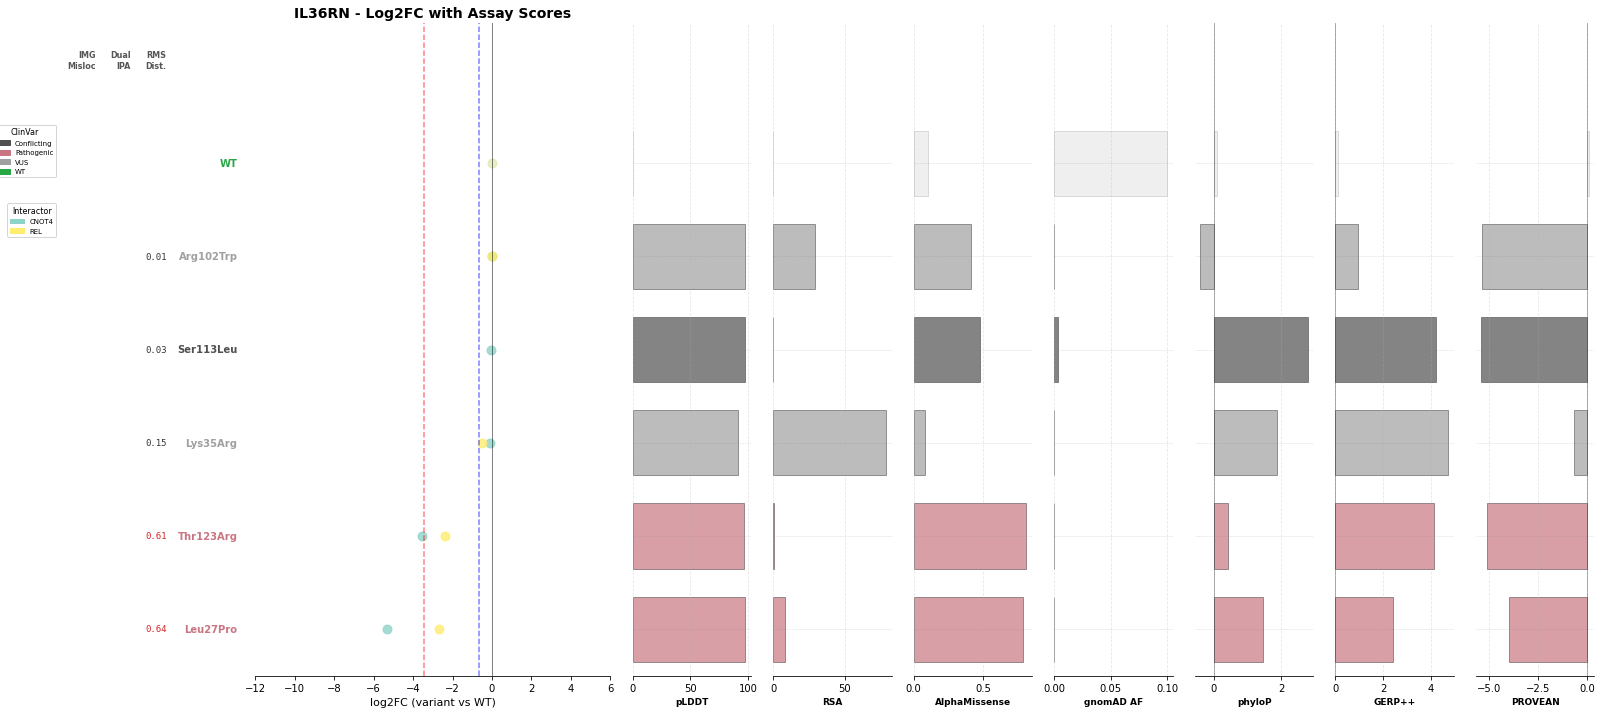

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/ACSF3_log2fc_panel.pdf


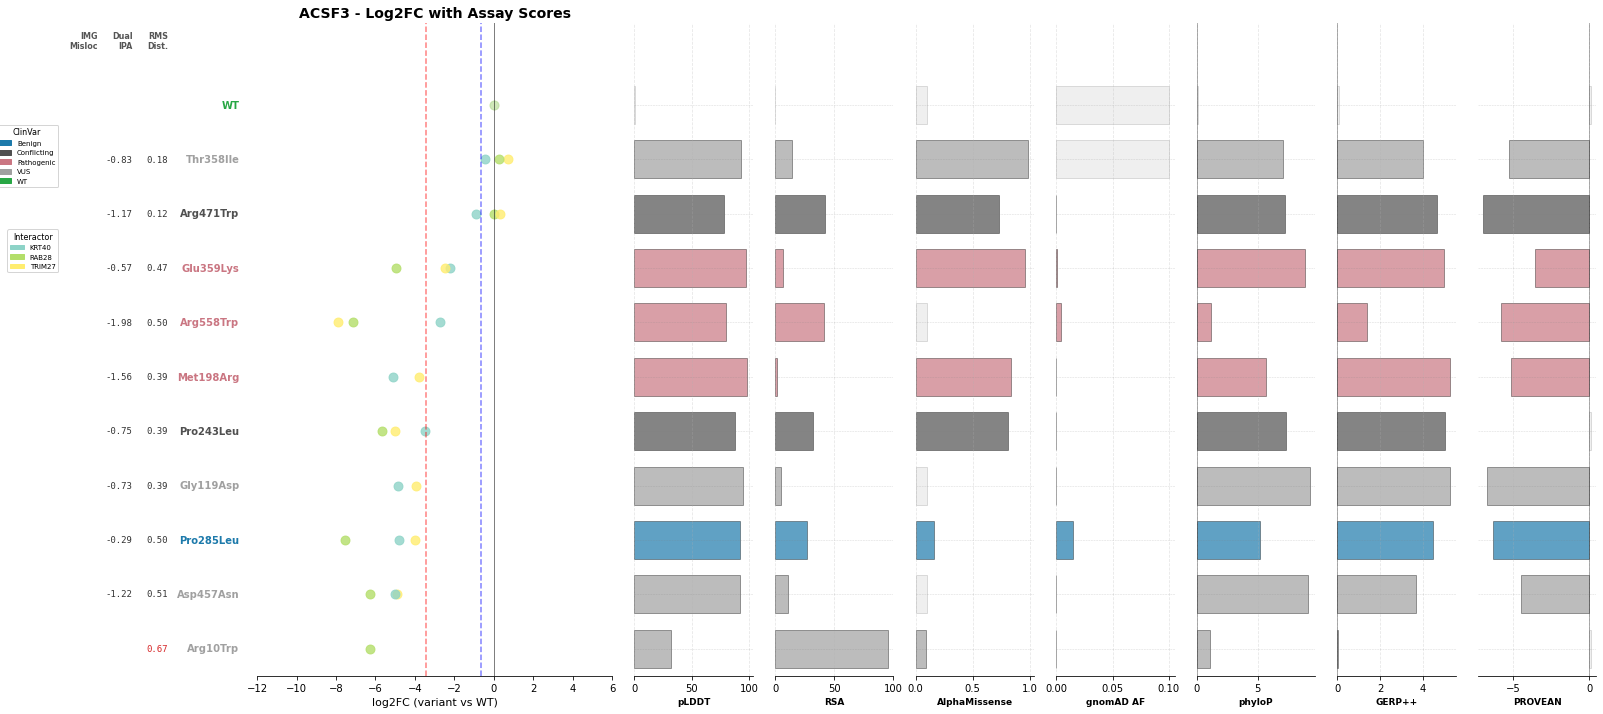

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SIX1_log2fc_panel.pdf


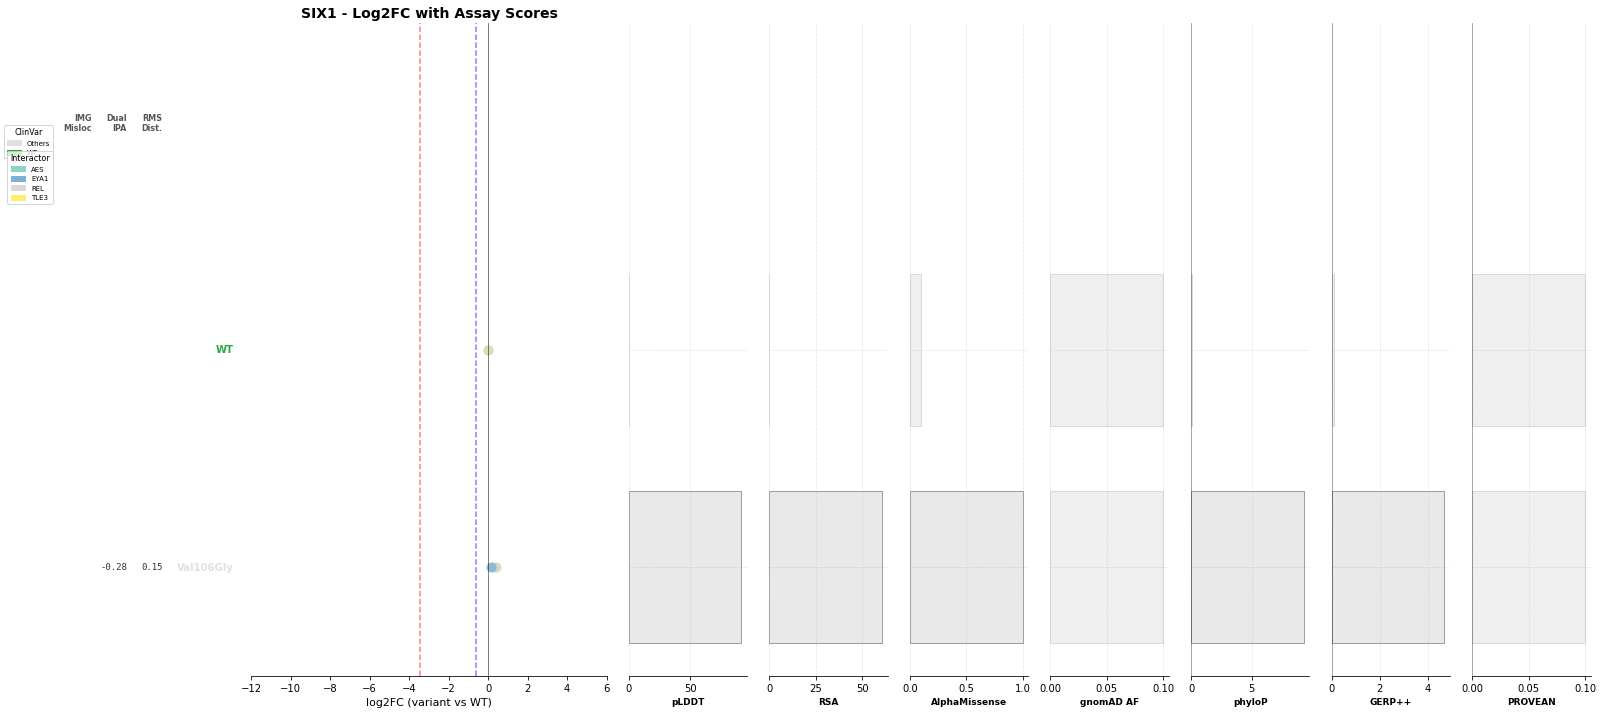

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/MLH1_log2fc_panel.pdf


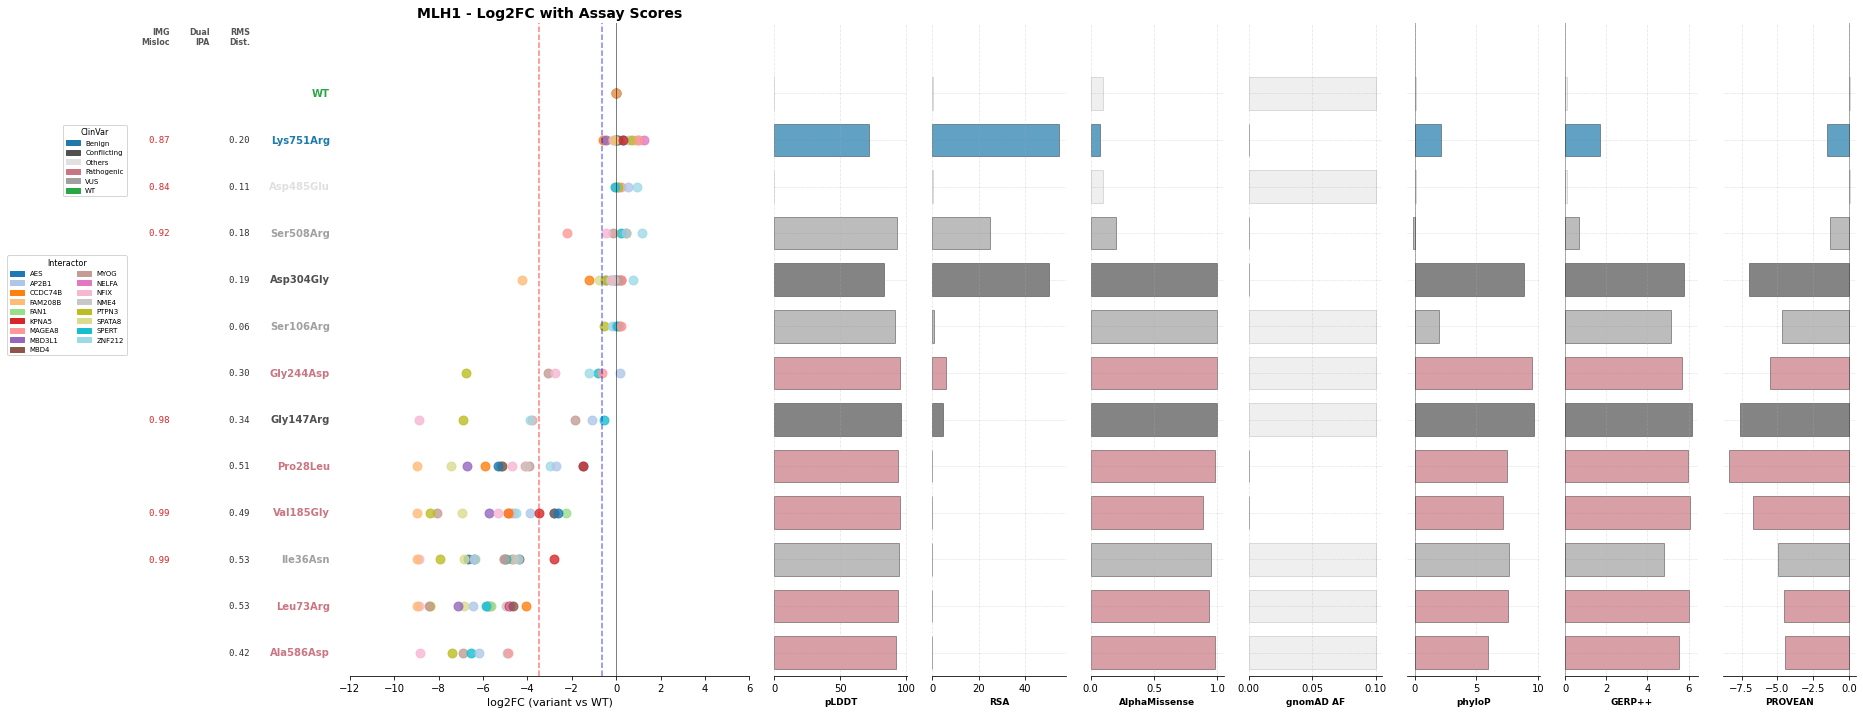

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NR0B1_log2fc_panel.pdf


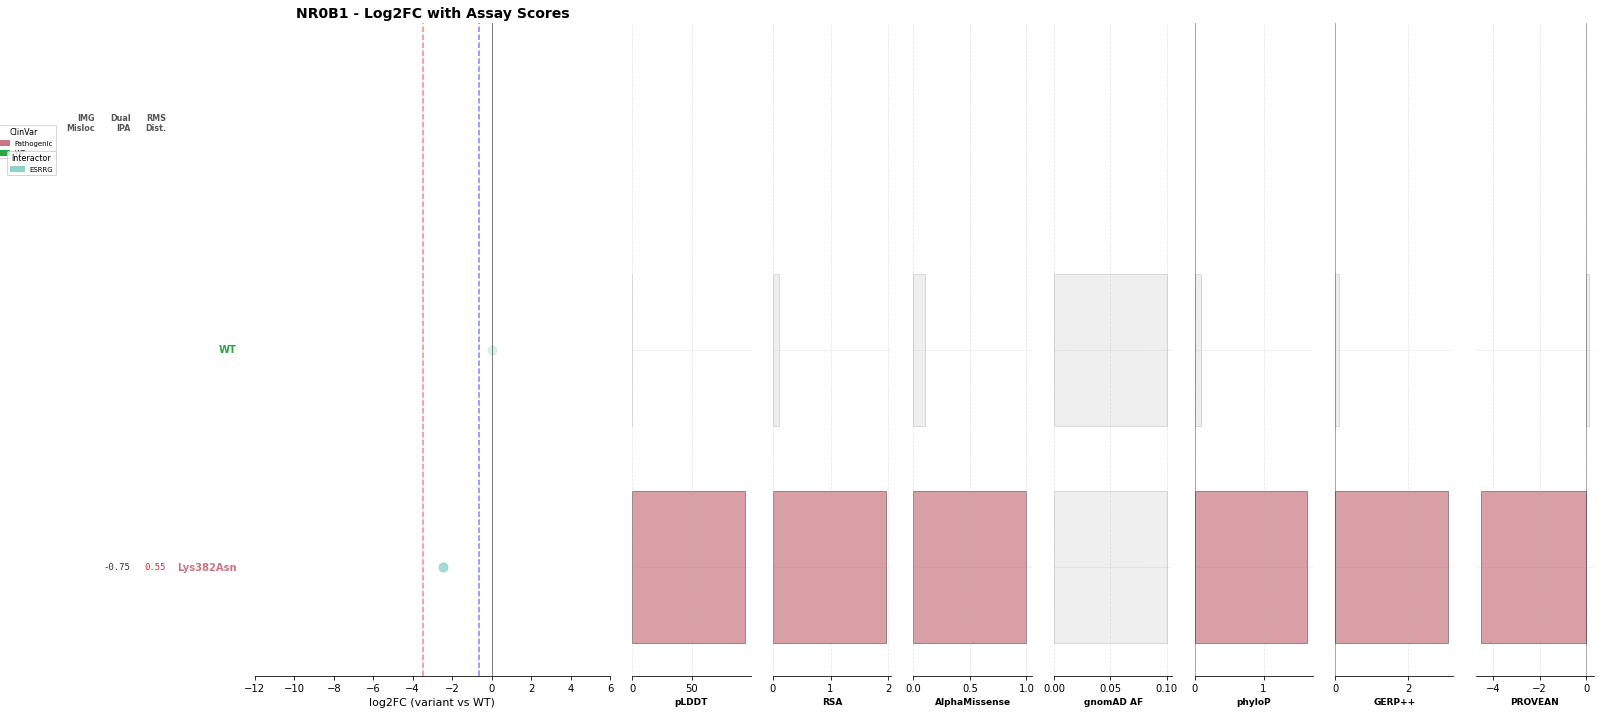

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NAA10_log2fc_panel.pdf


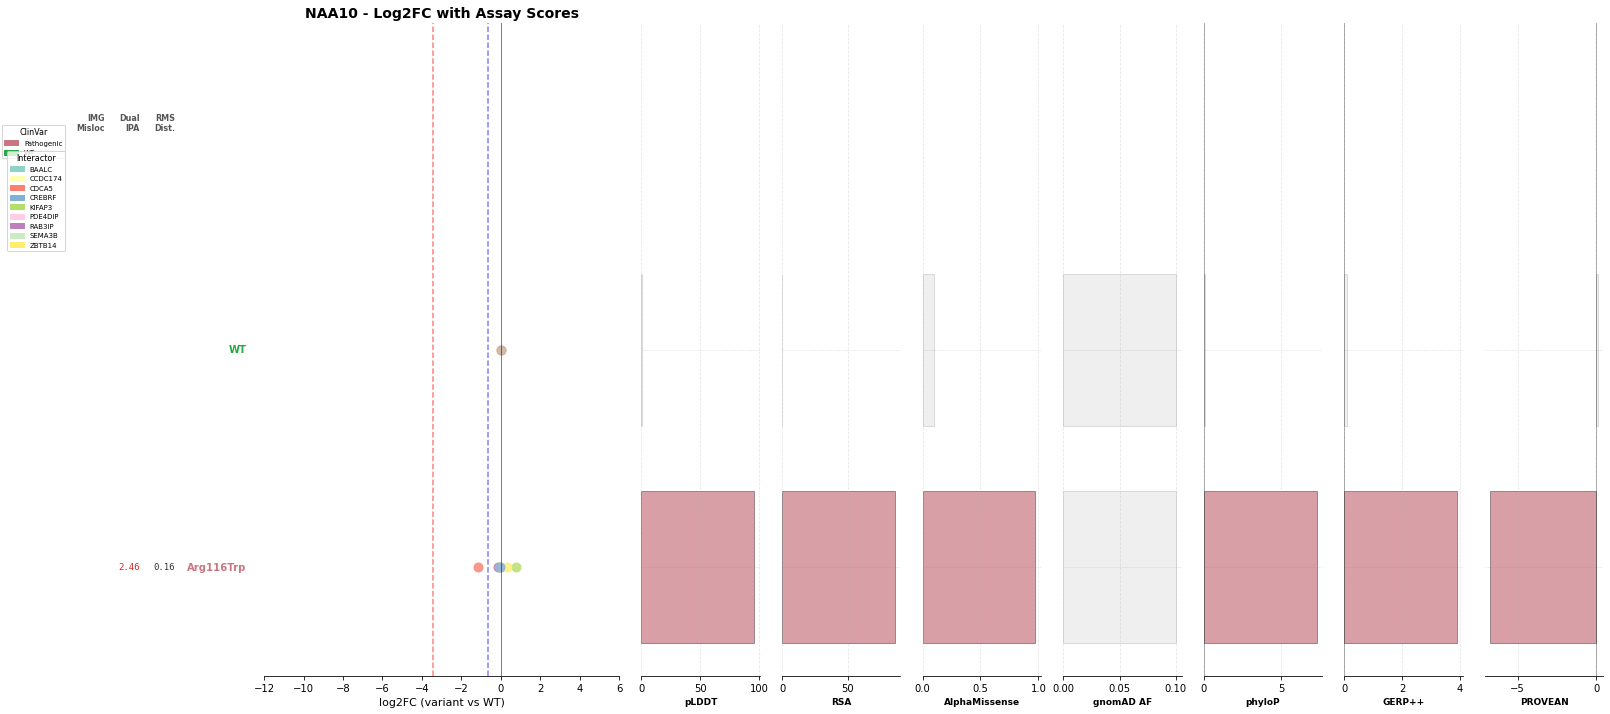

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PLP1_log2fc_panel.pdf


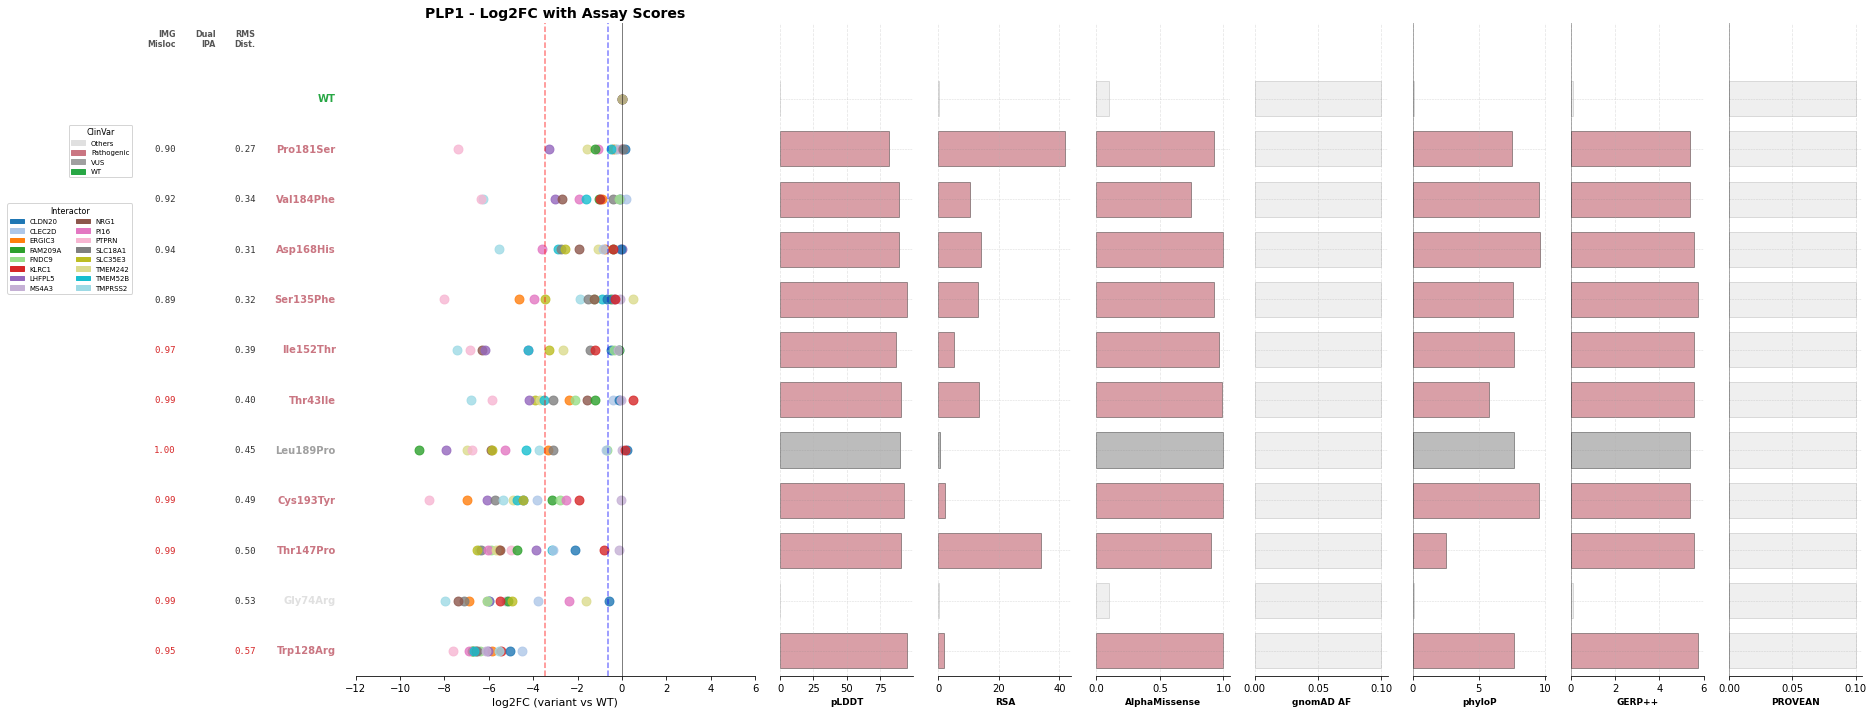

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NEUROG3_log2fc_panel.pdf


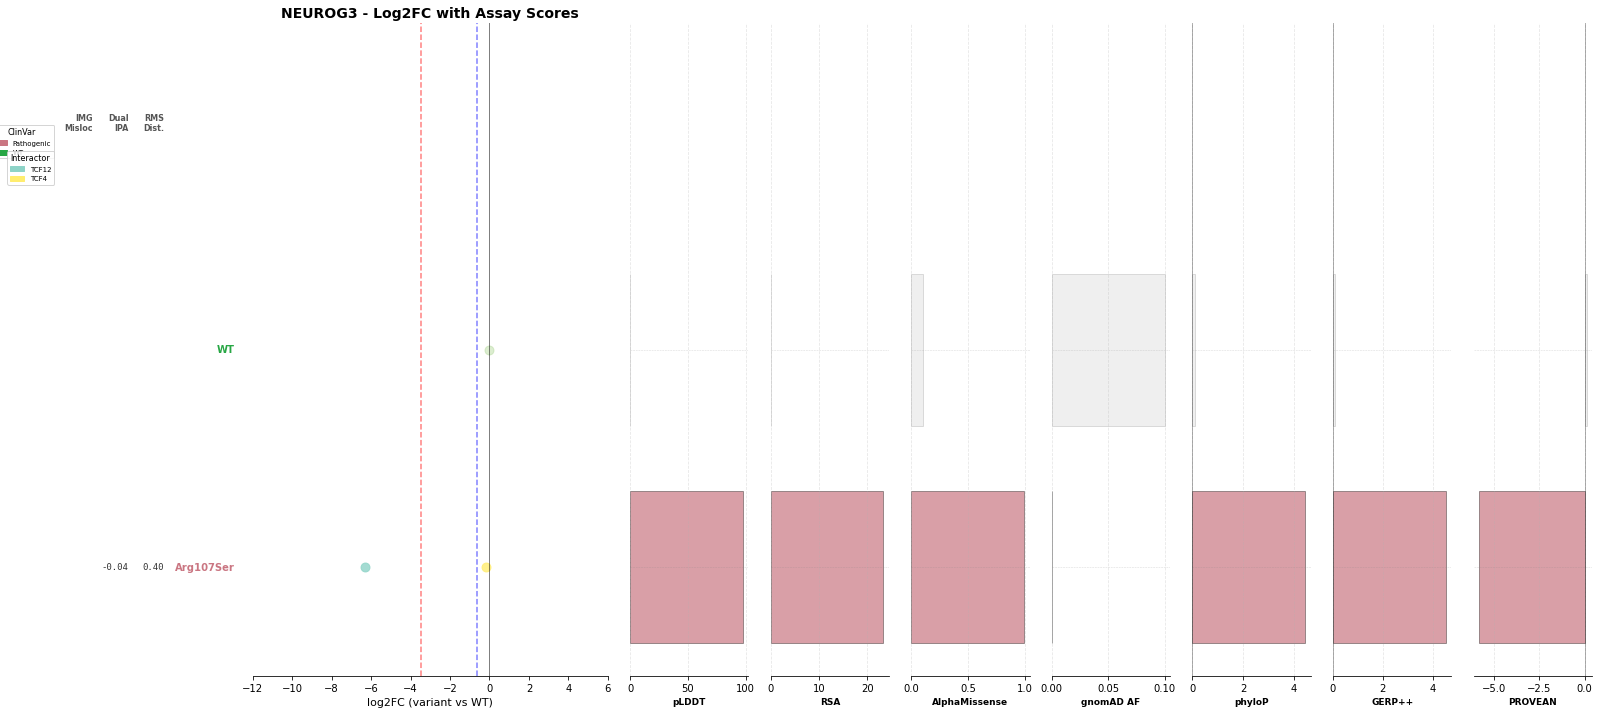

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SFTPC_log2fc_panel.pdf


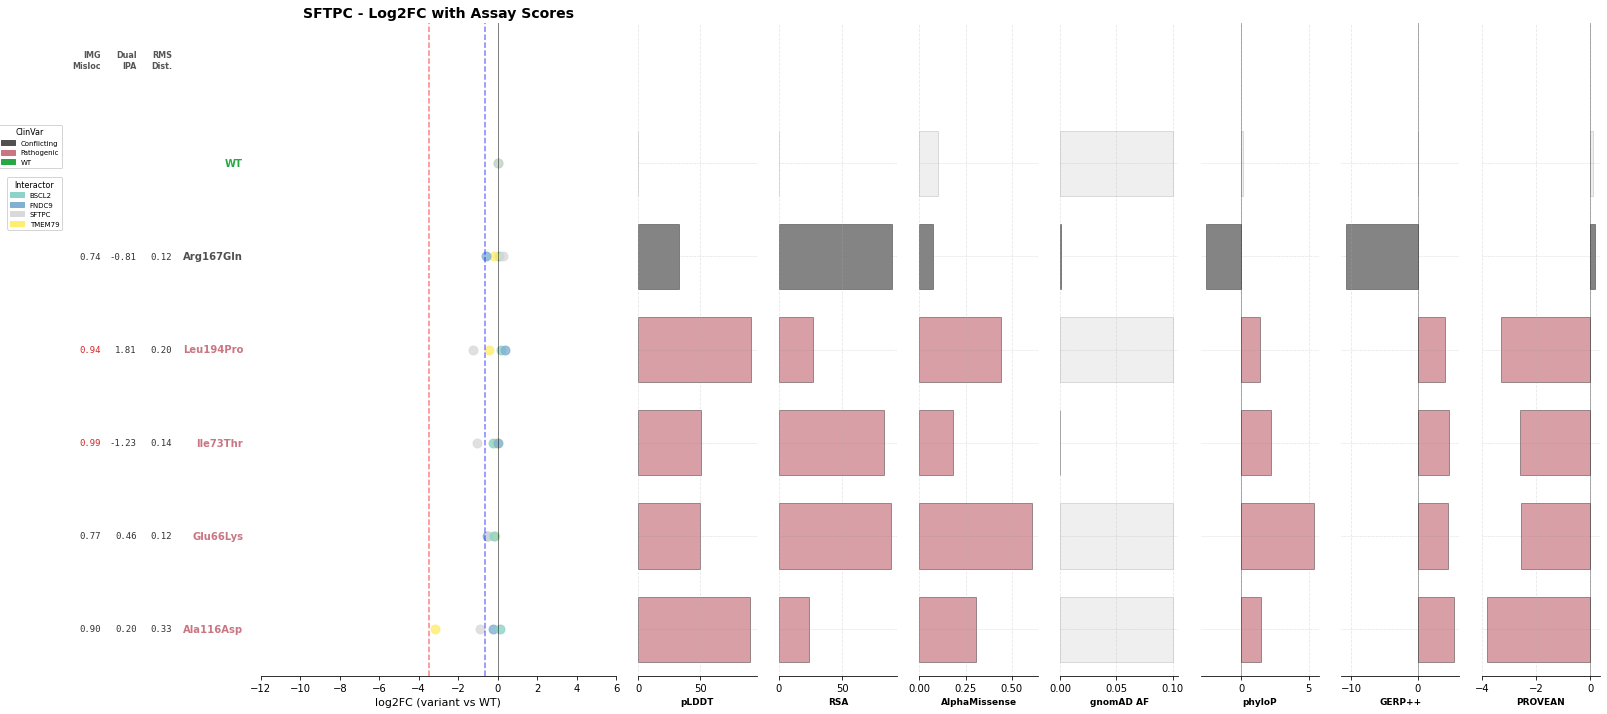

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/AP2S1_log2fc_panel.pdf


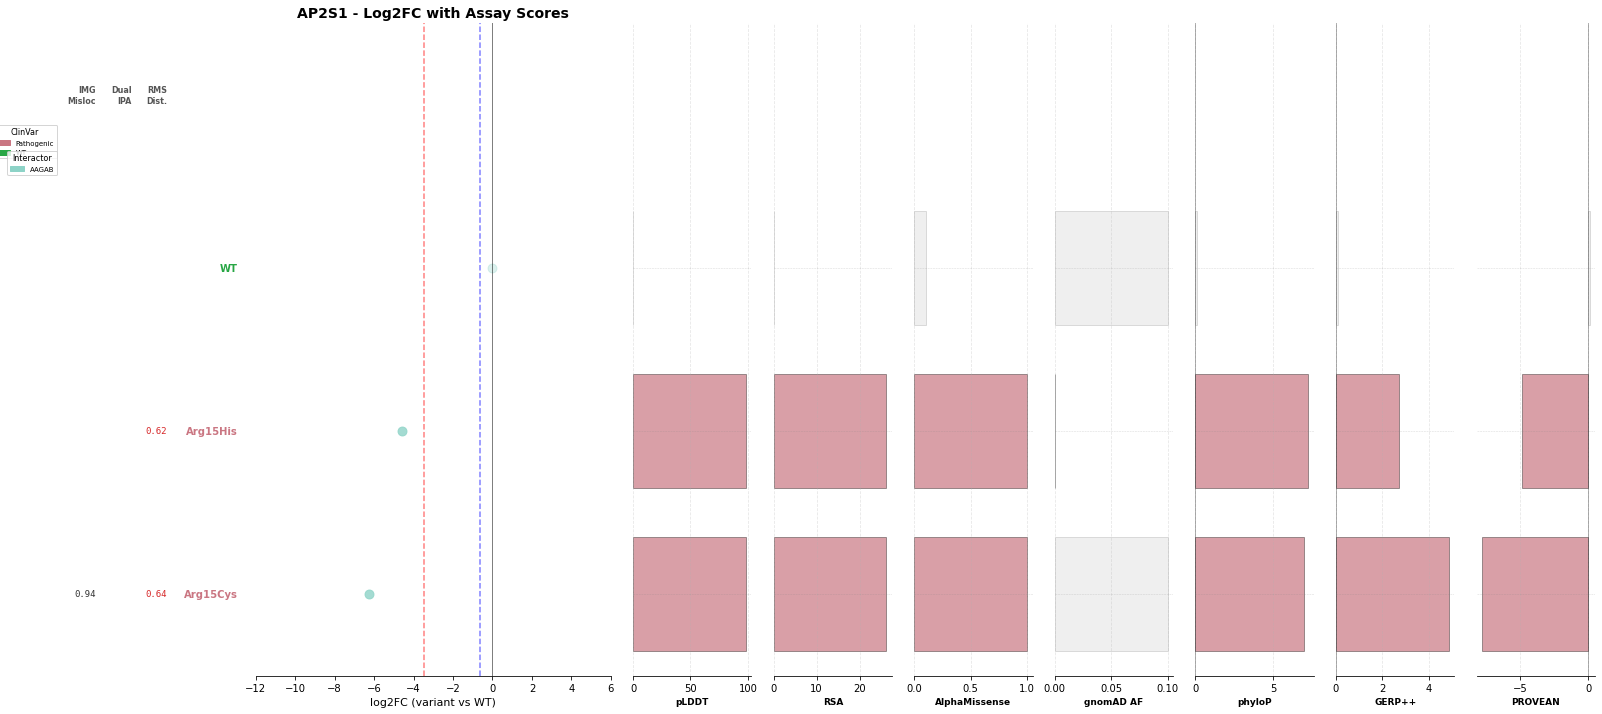

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/CLN6_log2fc_panel.pdf


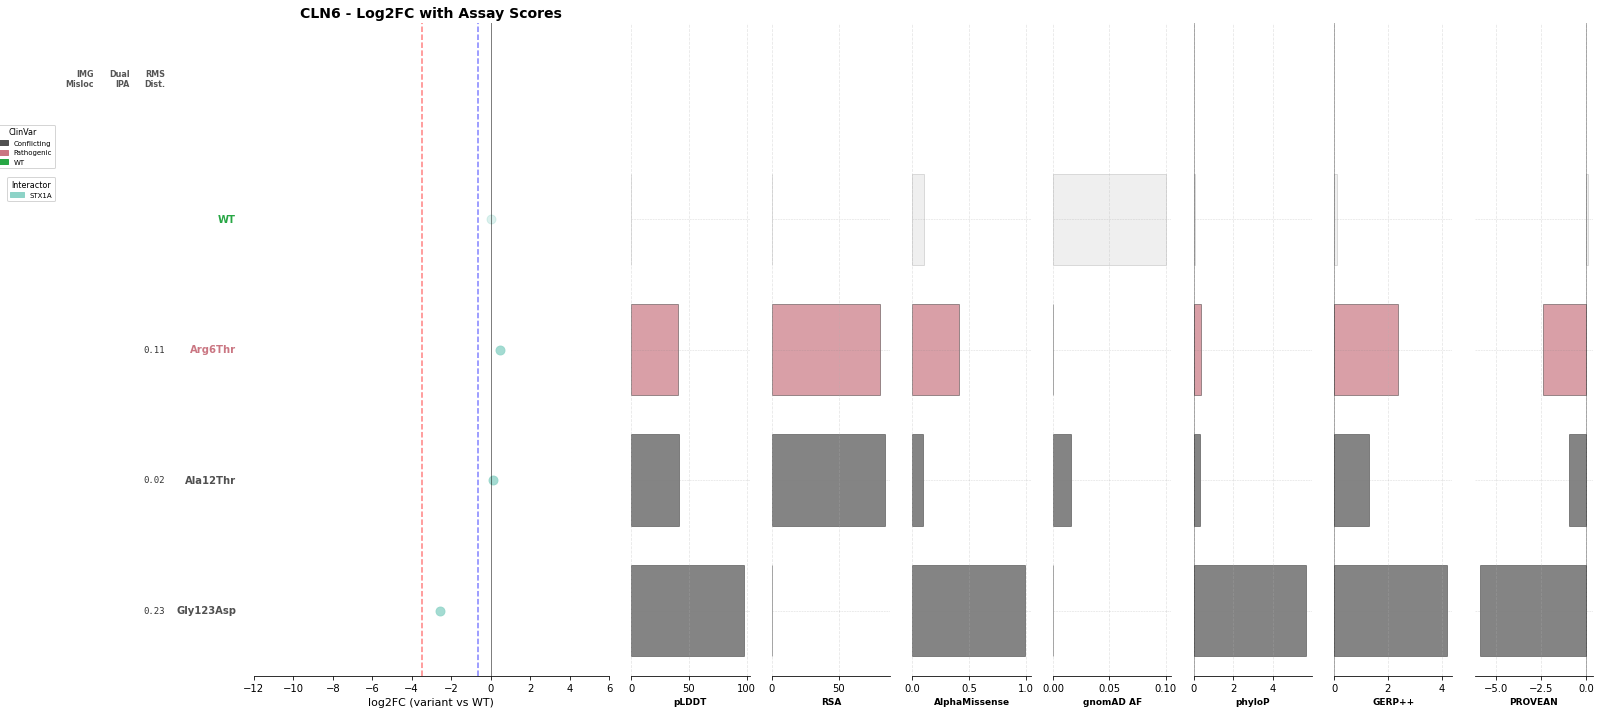

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/LDHB_log2fc_panel.pdf


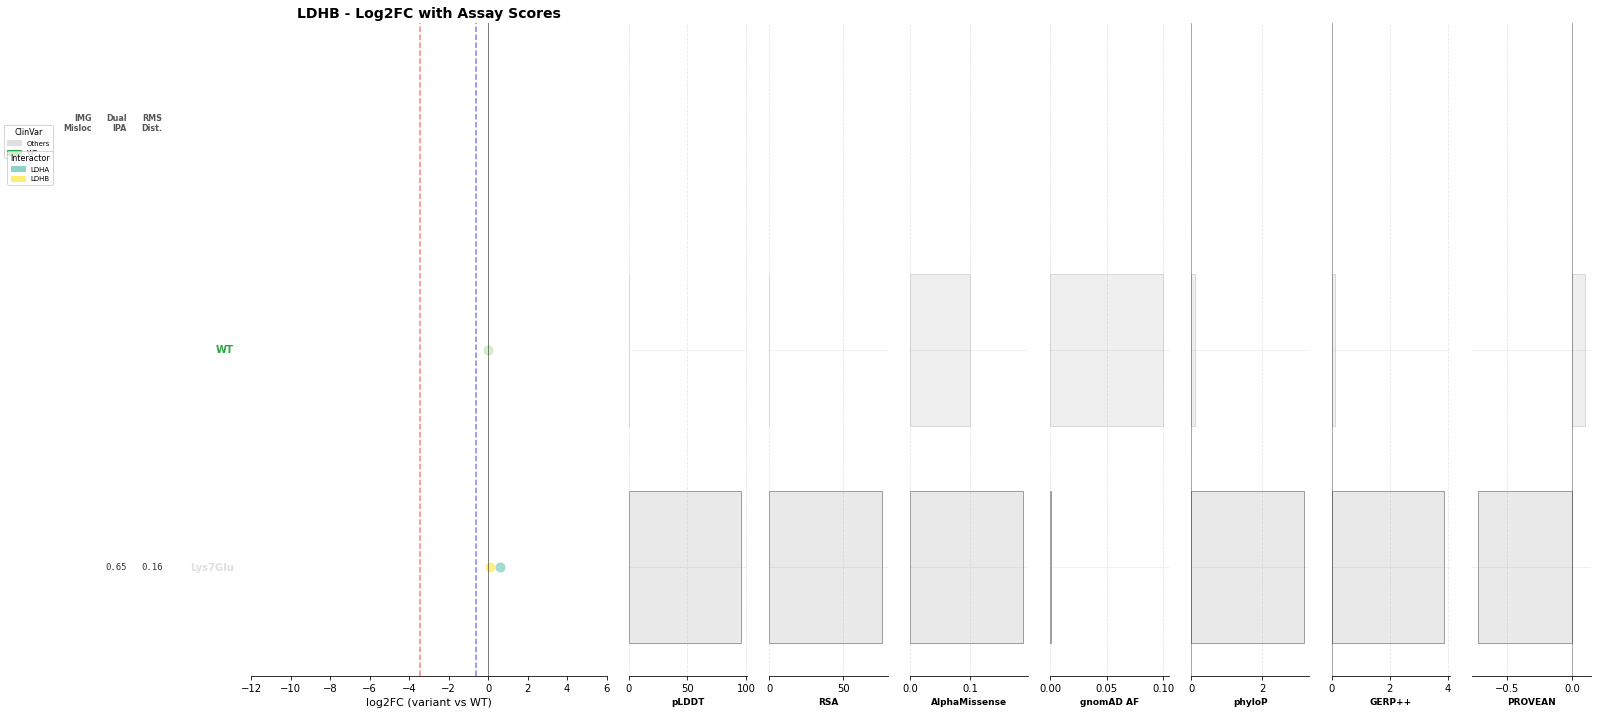

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/AGXT_log2fc_panel.pdf


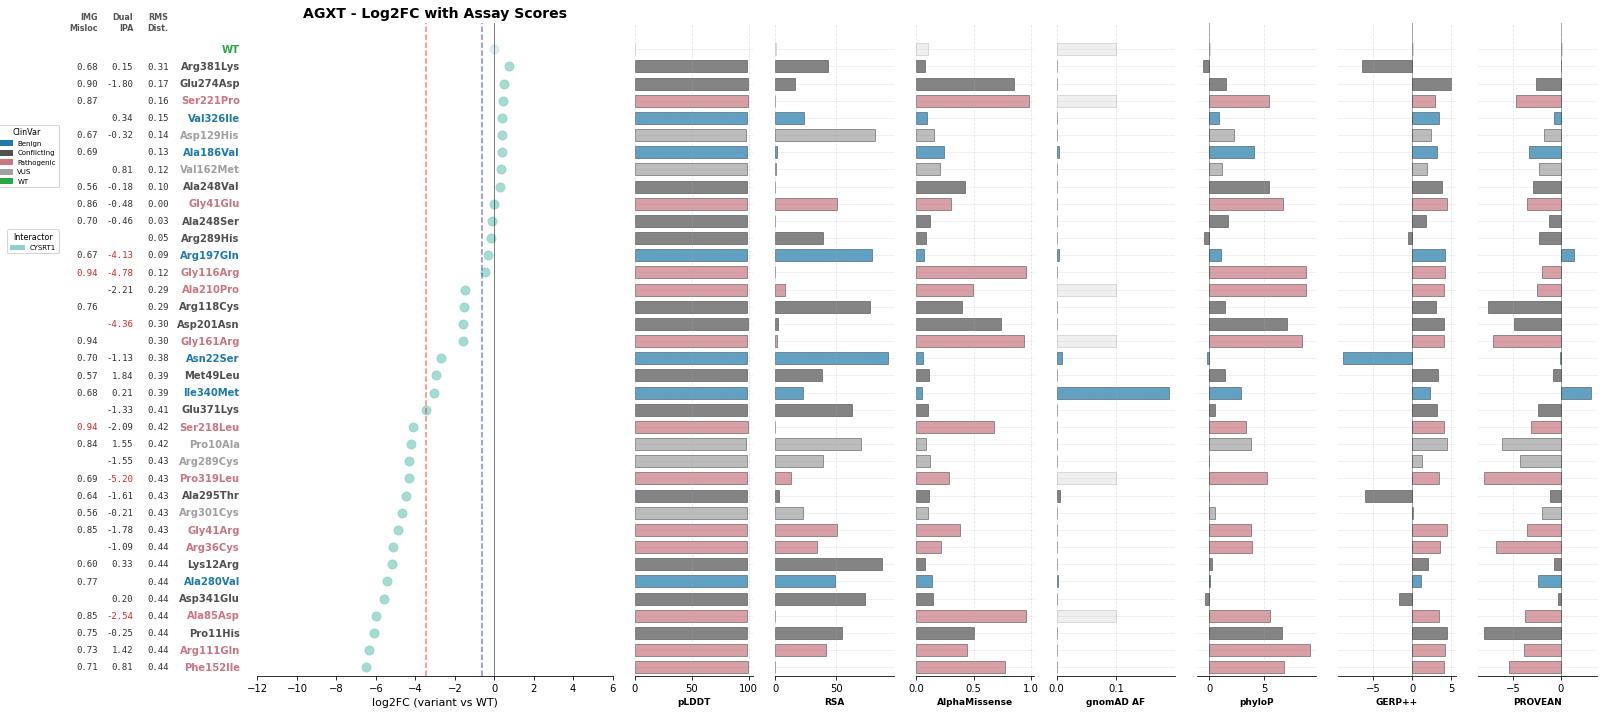

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/CRYAB_log2fc_panel.pdf


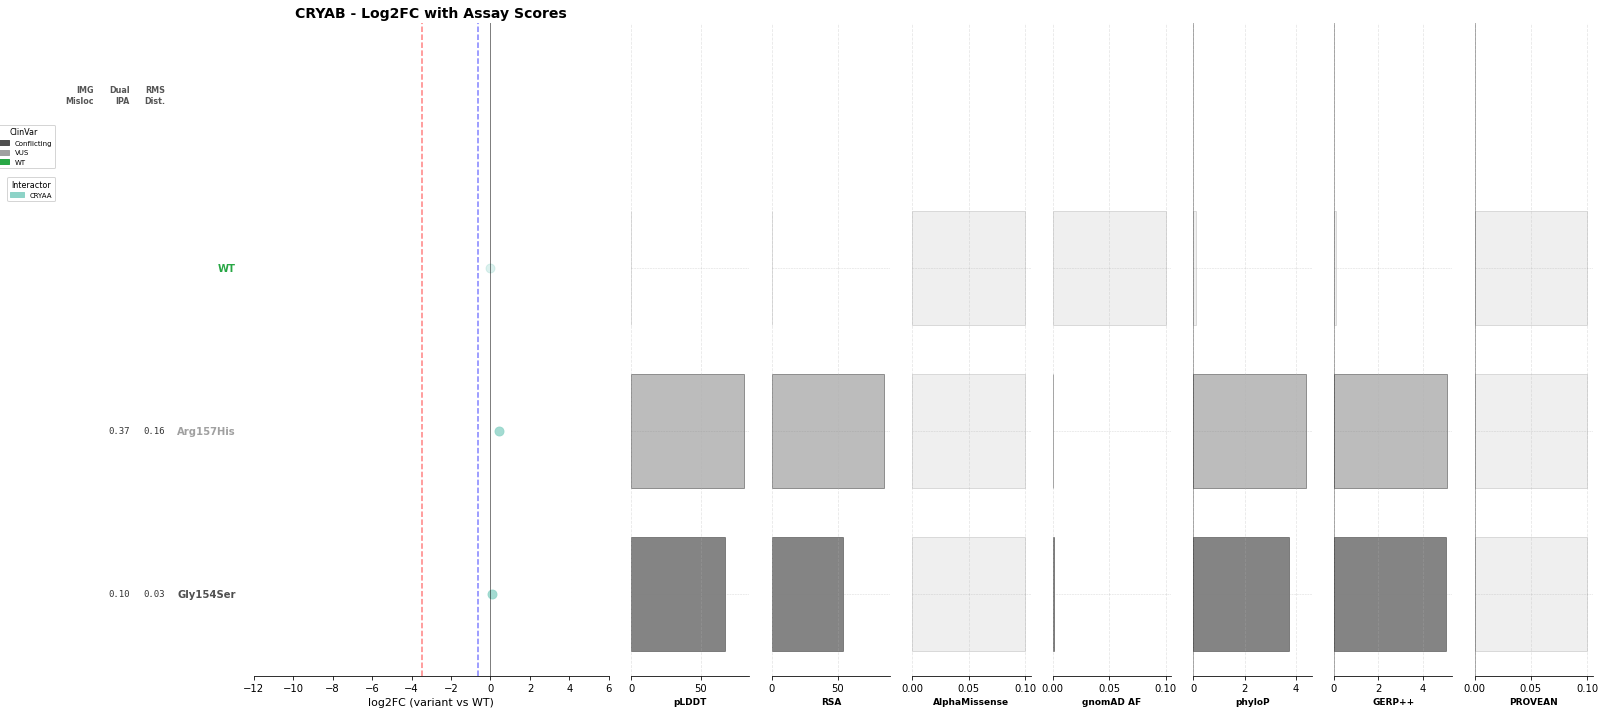

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KCTD1_log2fc_panel.pdf


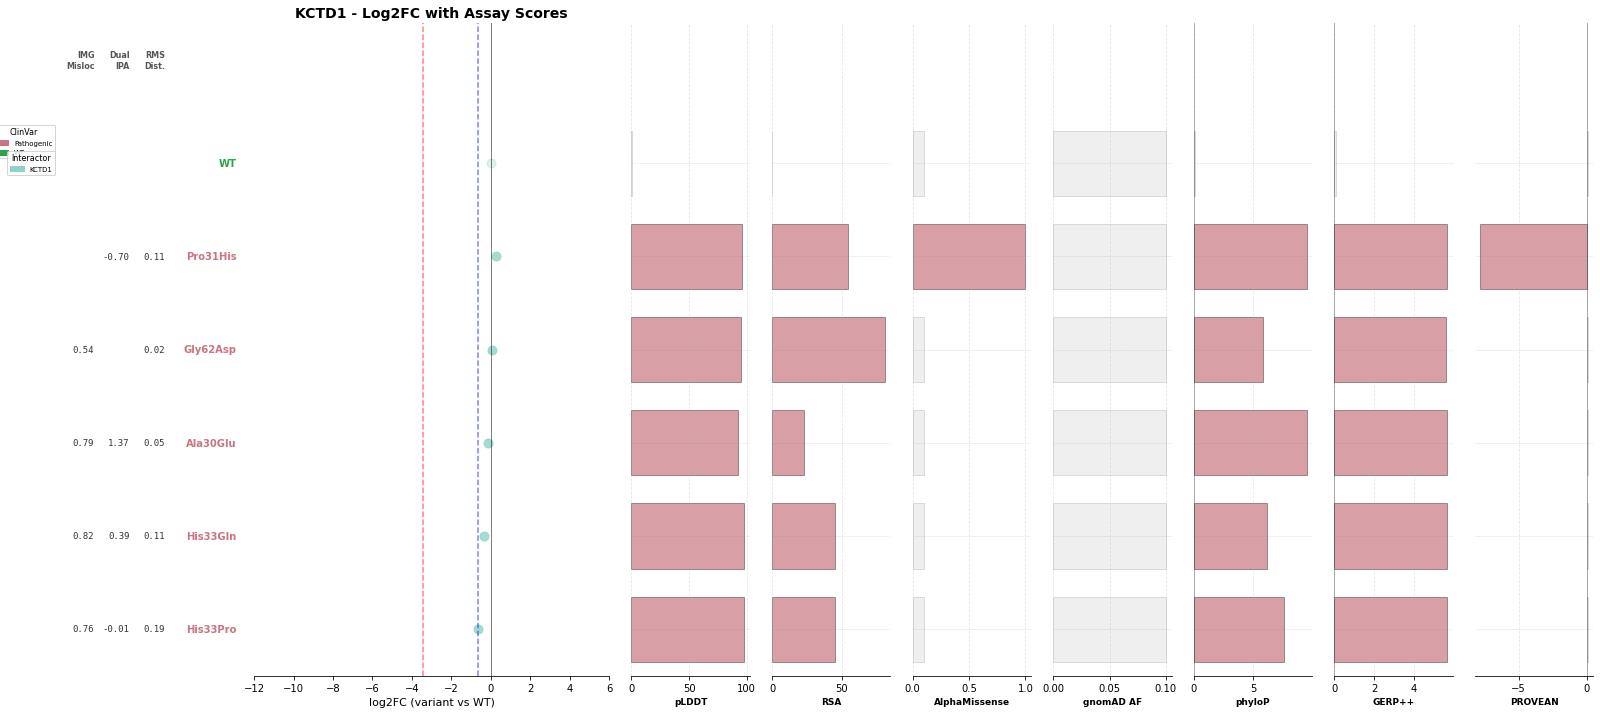

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GFAP_log2fc_panel.pdf


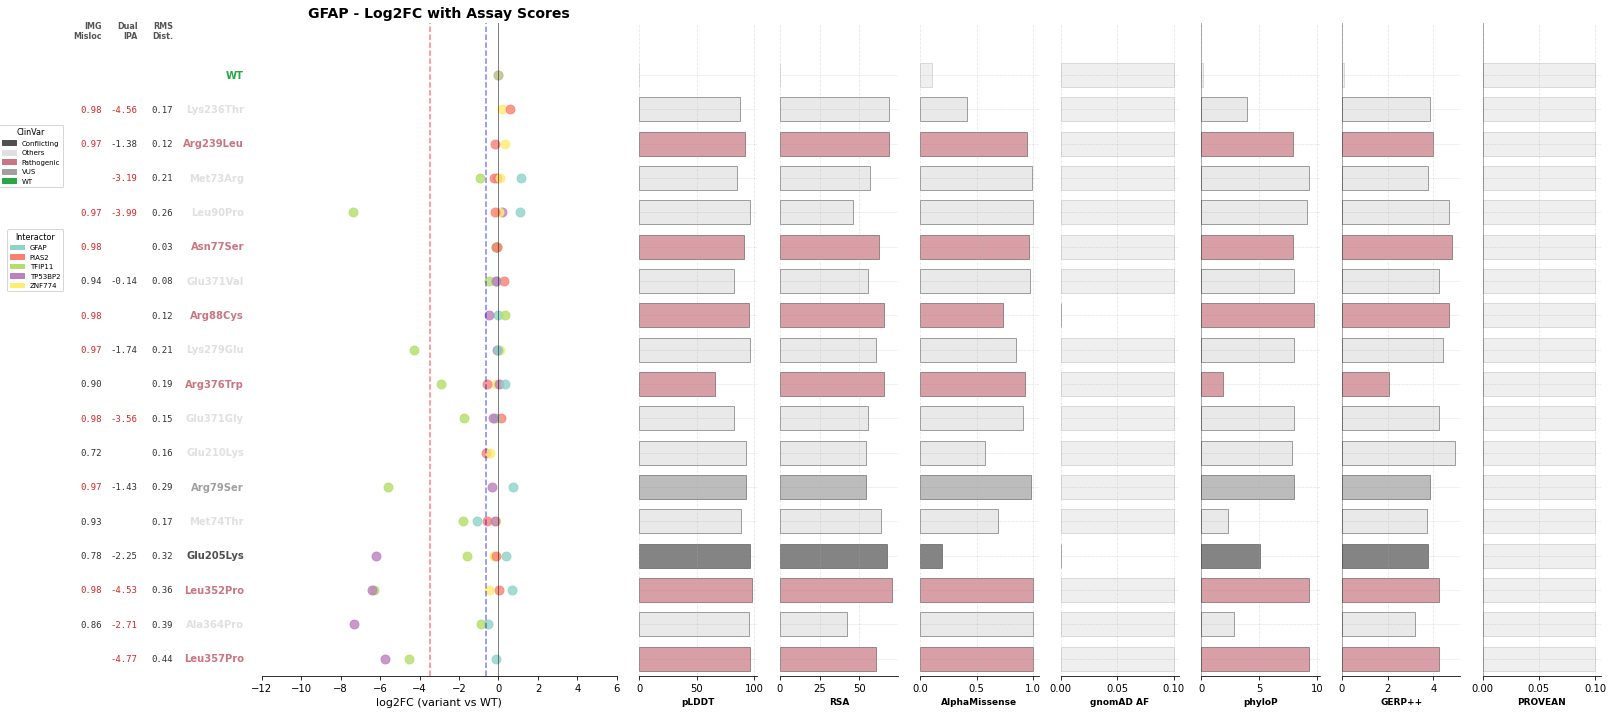

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/FA2H_log2fc_panel.pdf


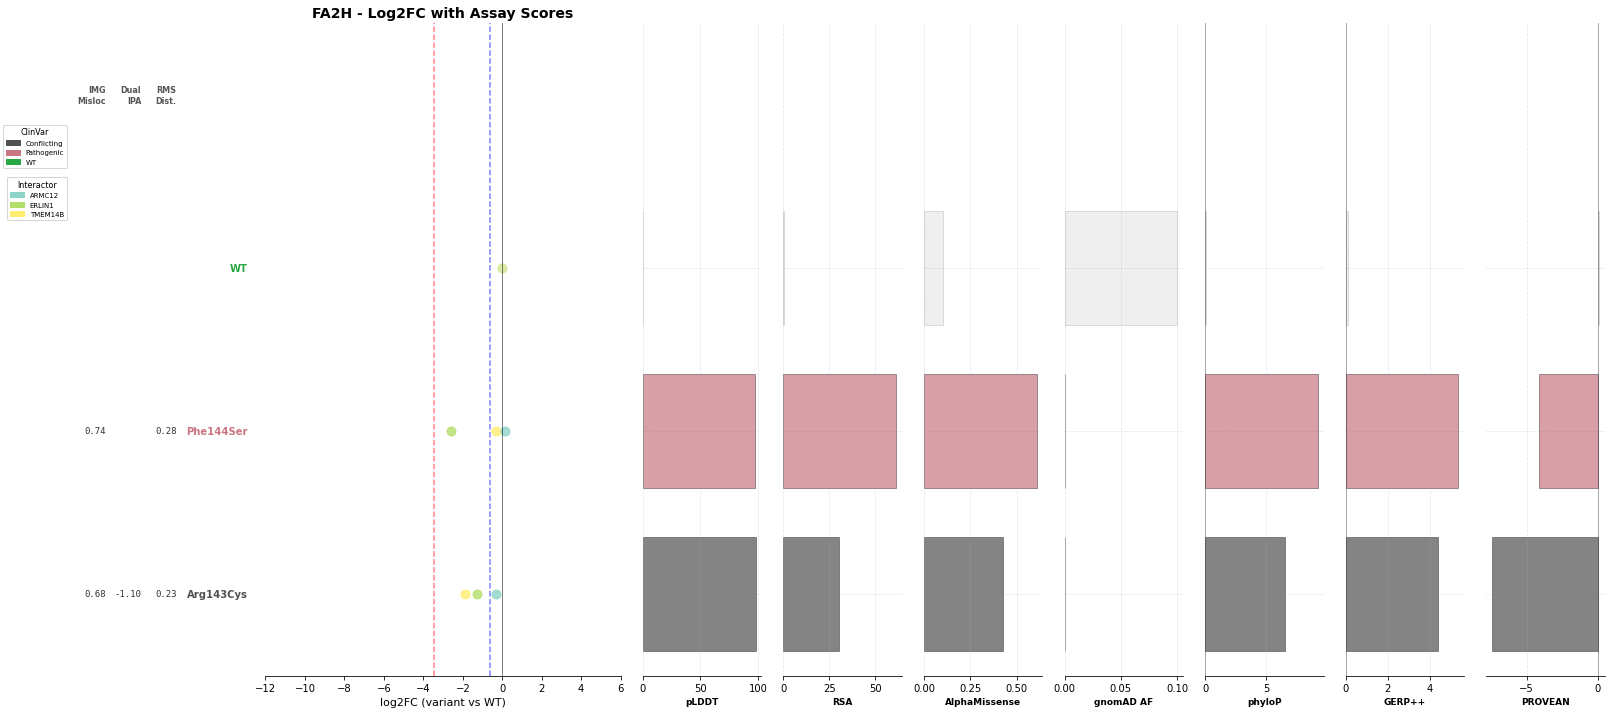

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/STXBP1_log2fc_panel.pdf


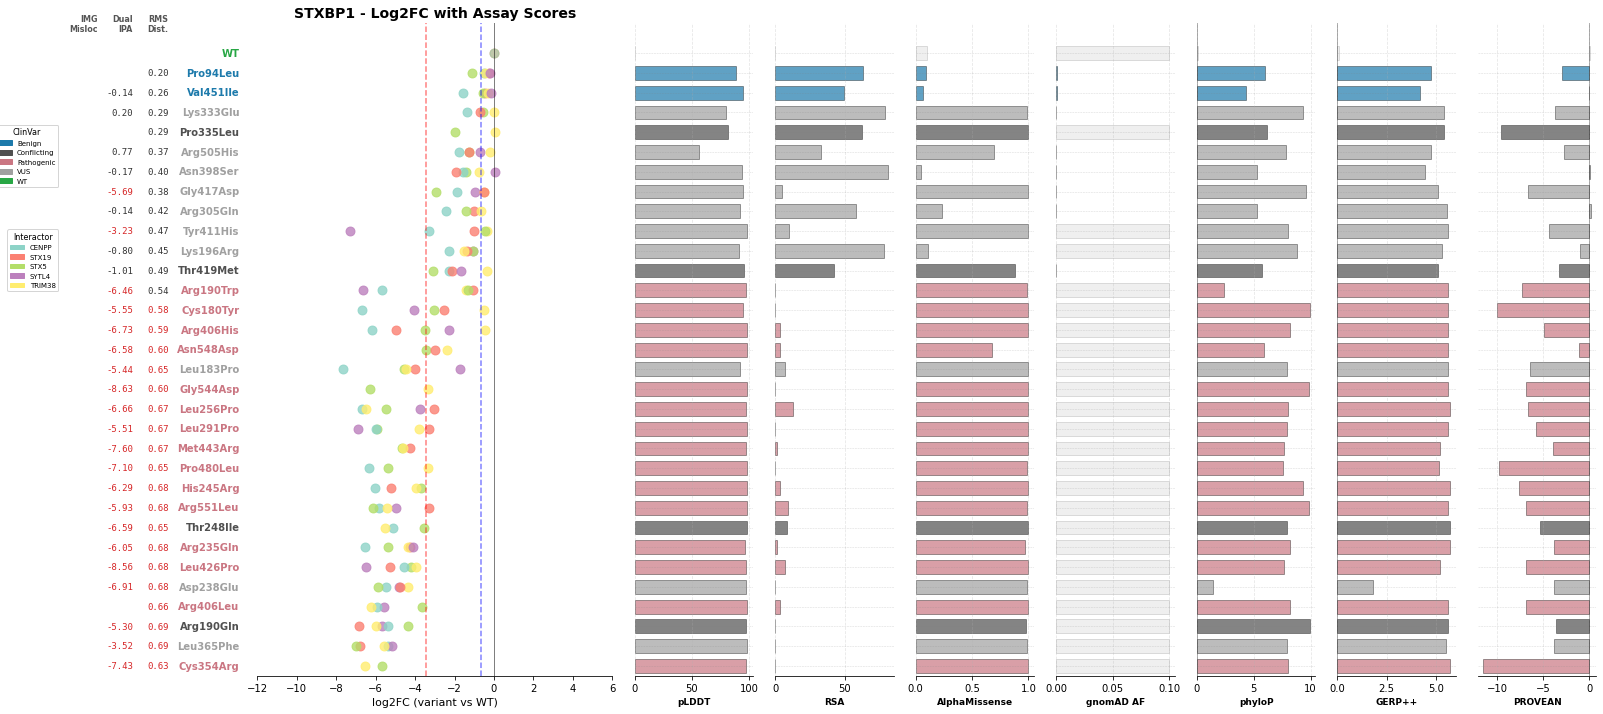

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TPK1_log2fc_panel.pdf


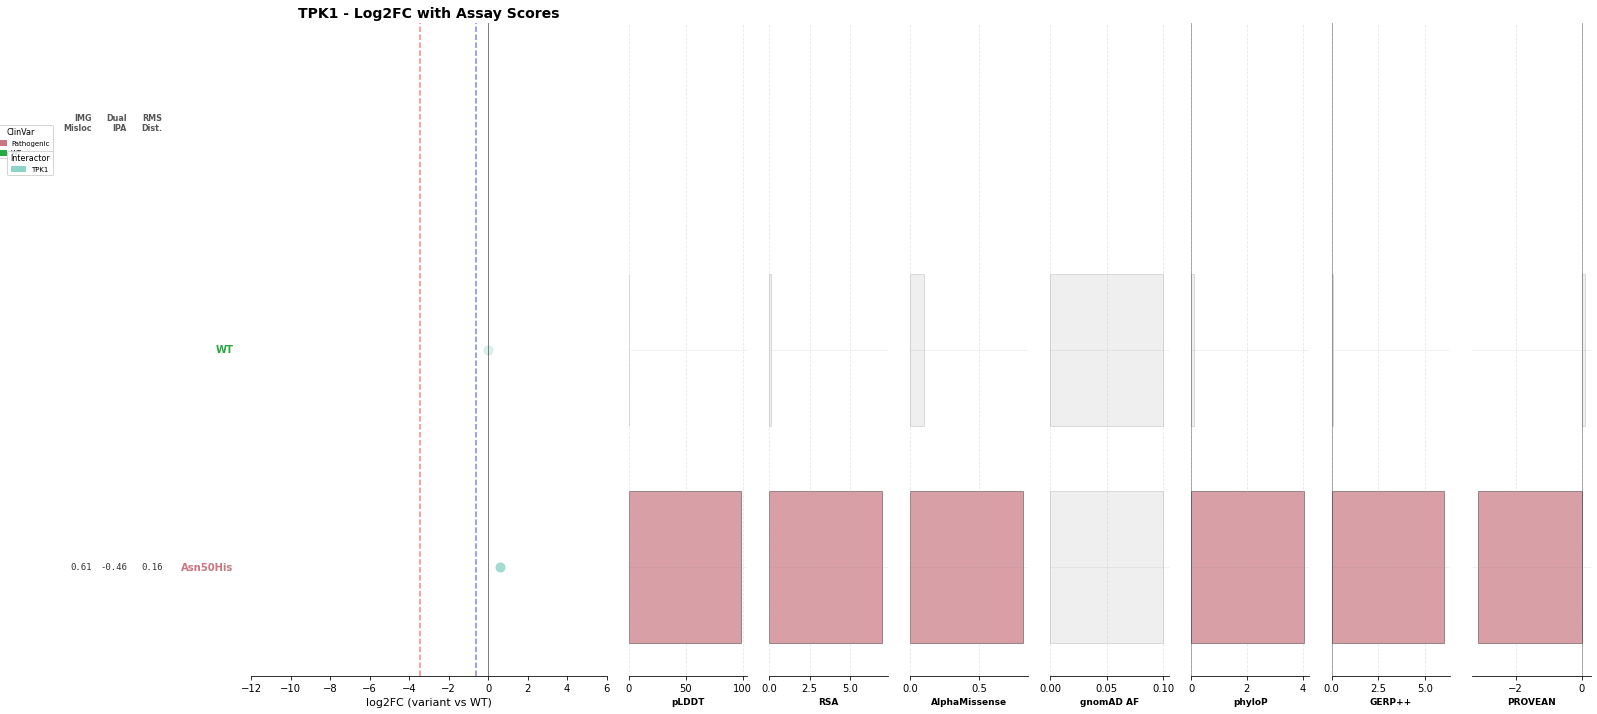

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PTS_log2fc_panel.pdf


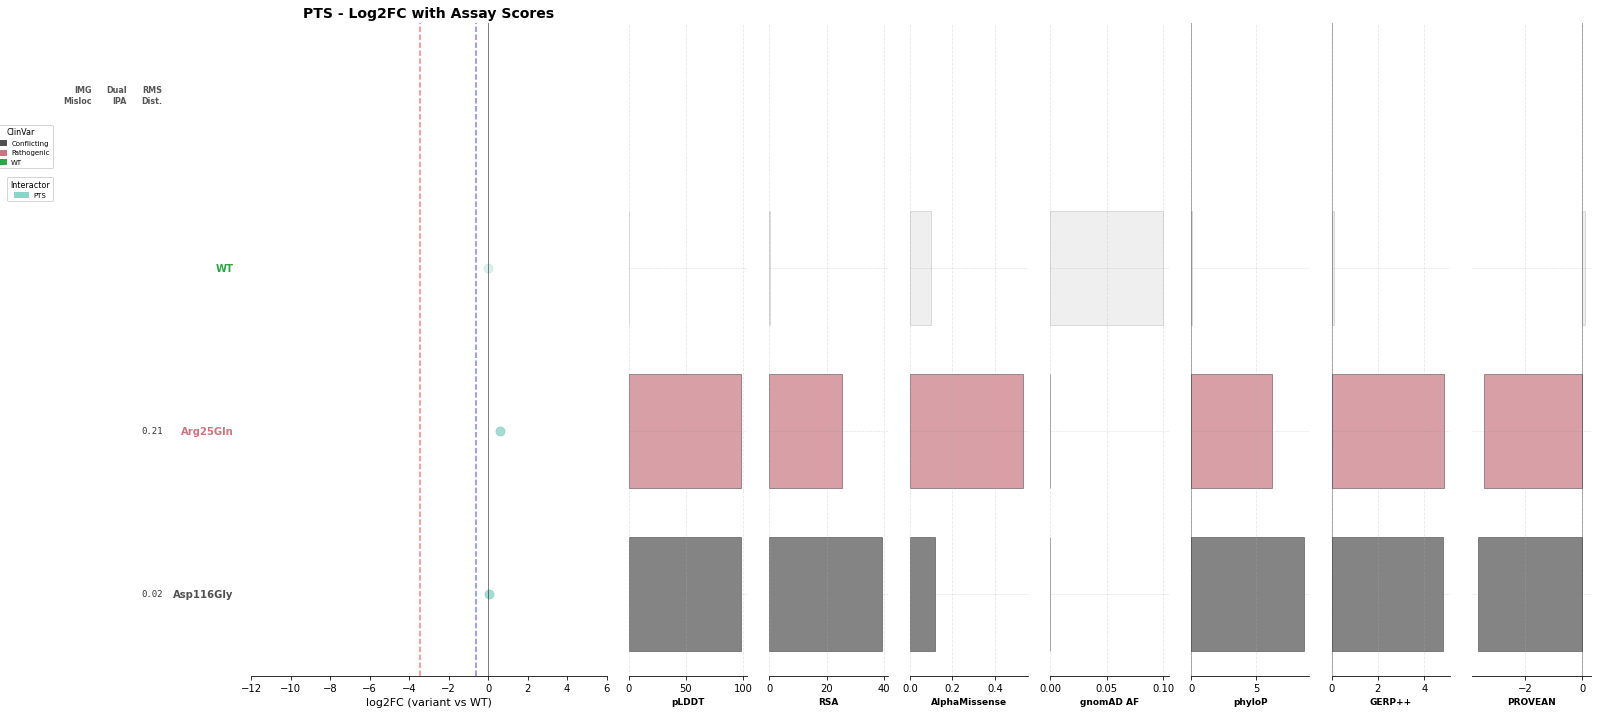

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/EZH2_log2fc_panel.pdf


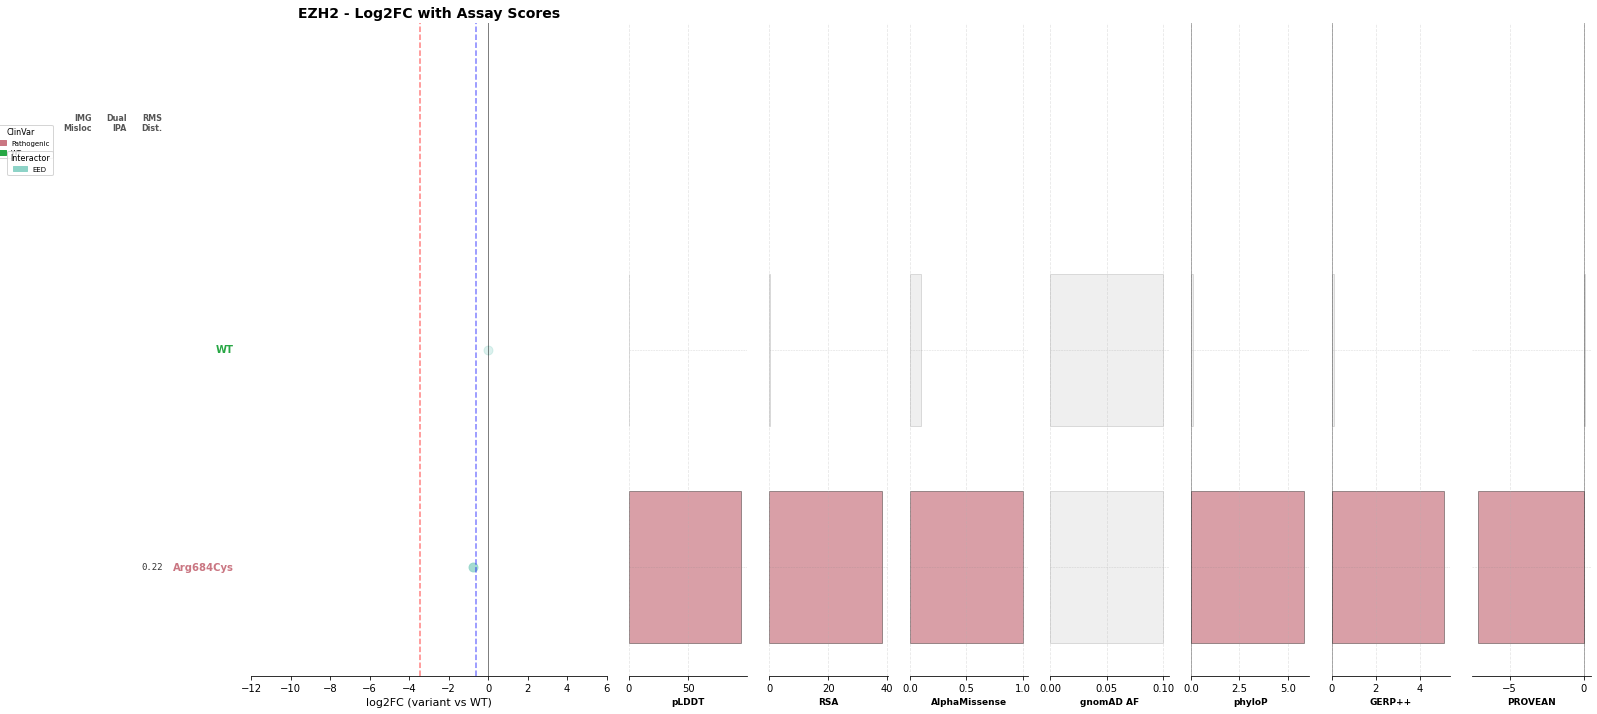

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/HGD_log2fc_panel.pdf


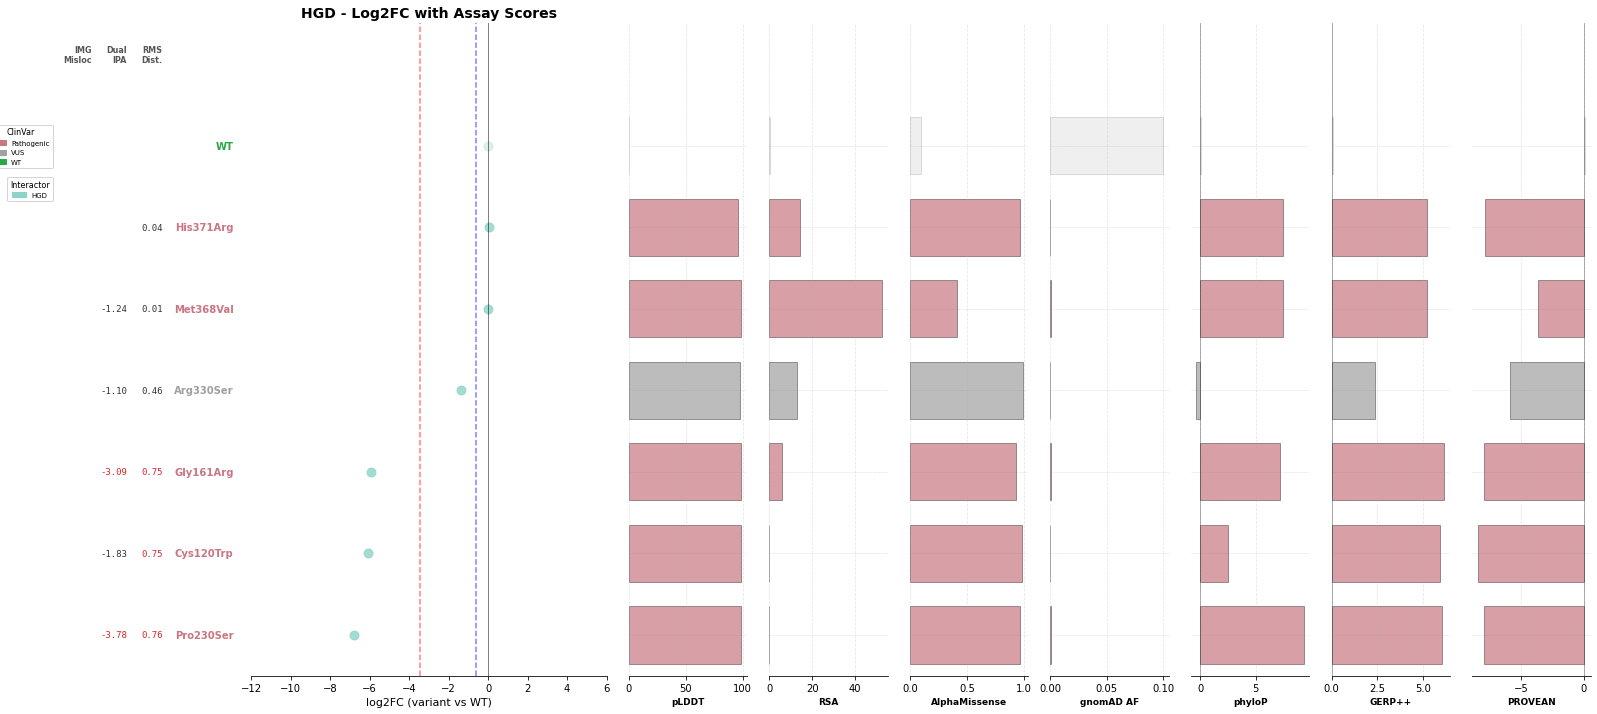

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NCF2_log2fc_panel.pdf


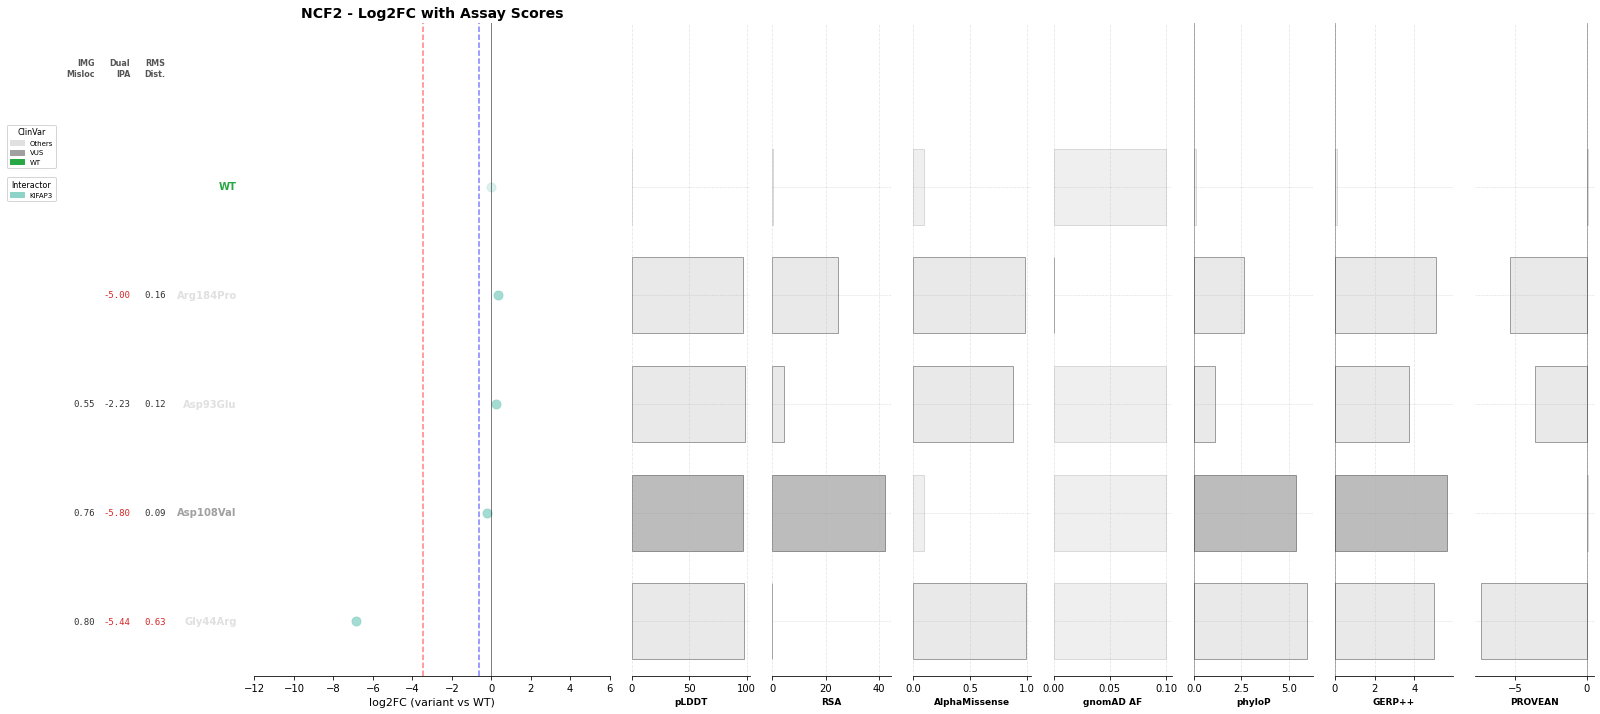

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/THAP1_log2fc_panel.pdf


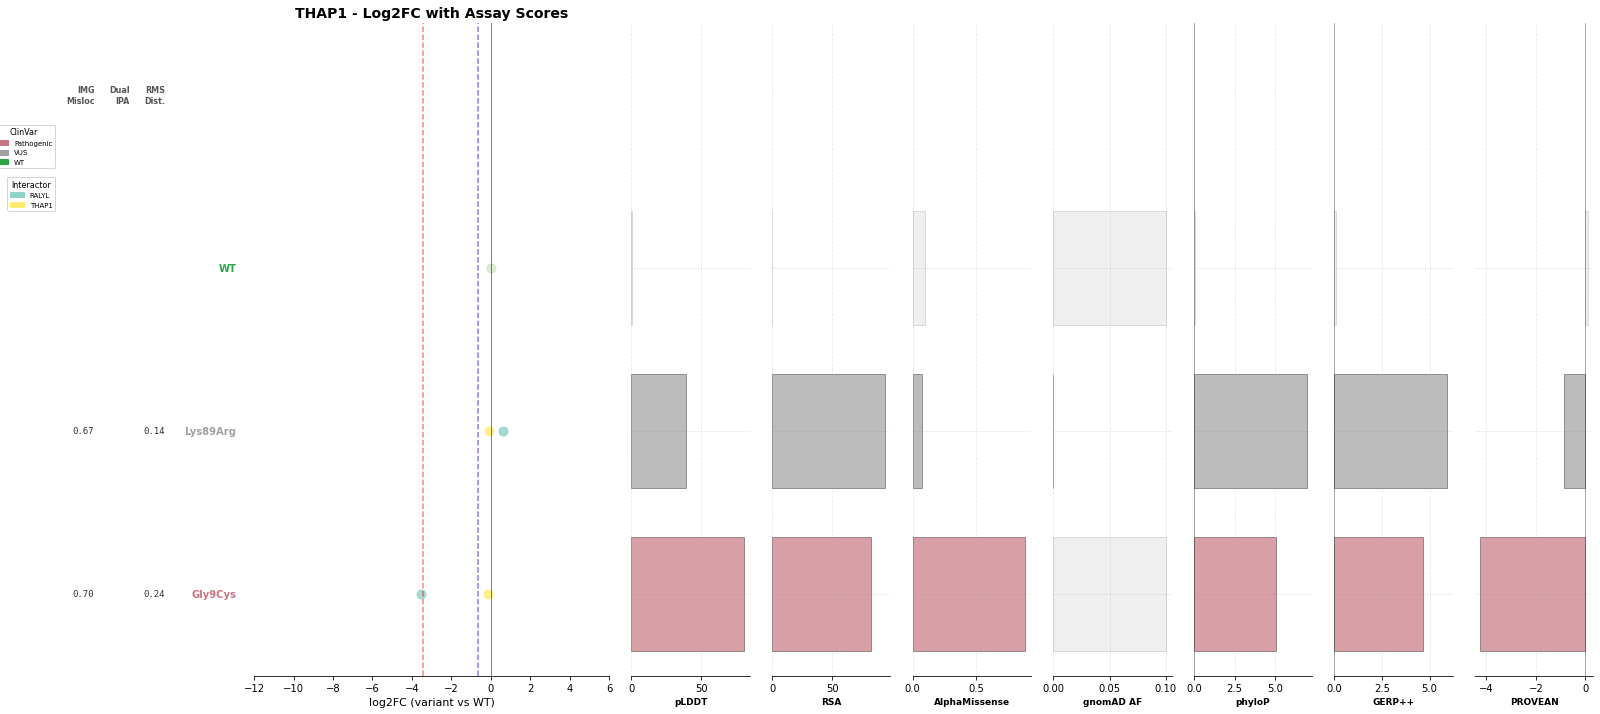

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/NMNAT1_log2fc_panel.pdf


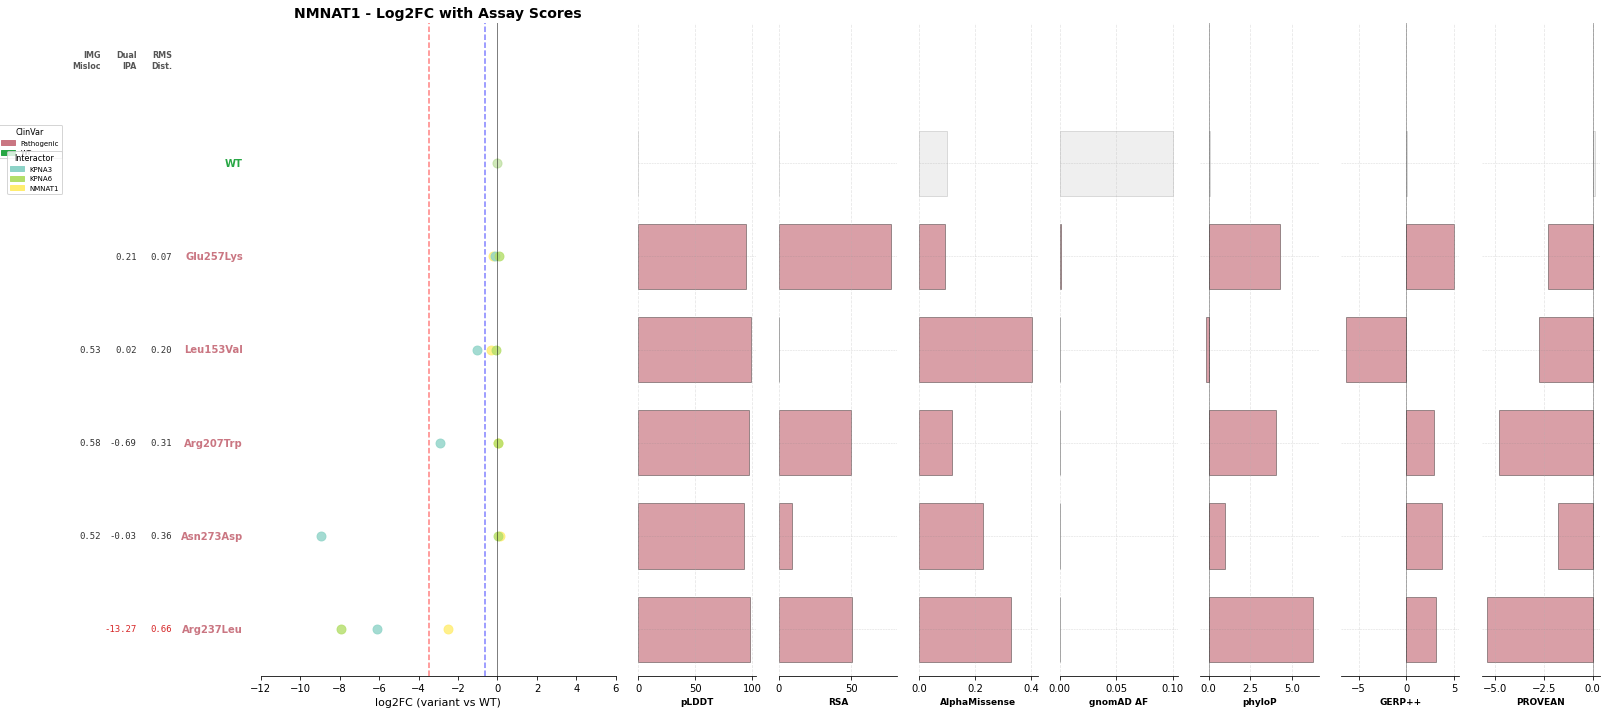

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/KLHL3_log2fc_panel.pdf


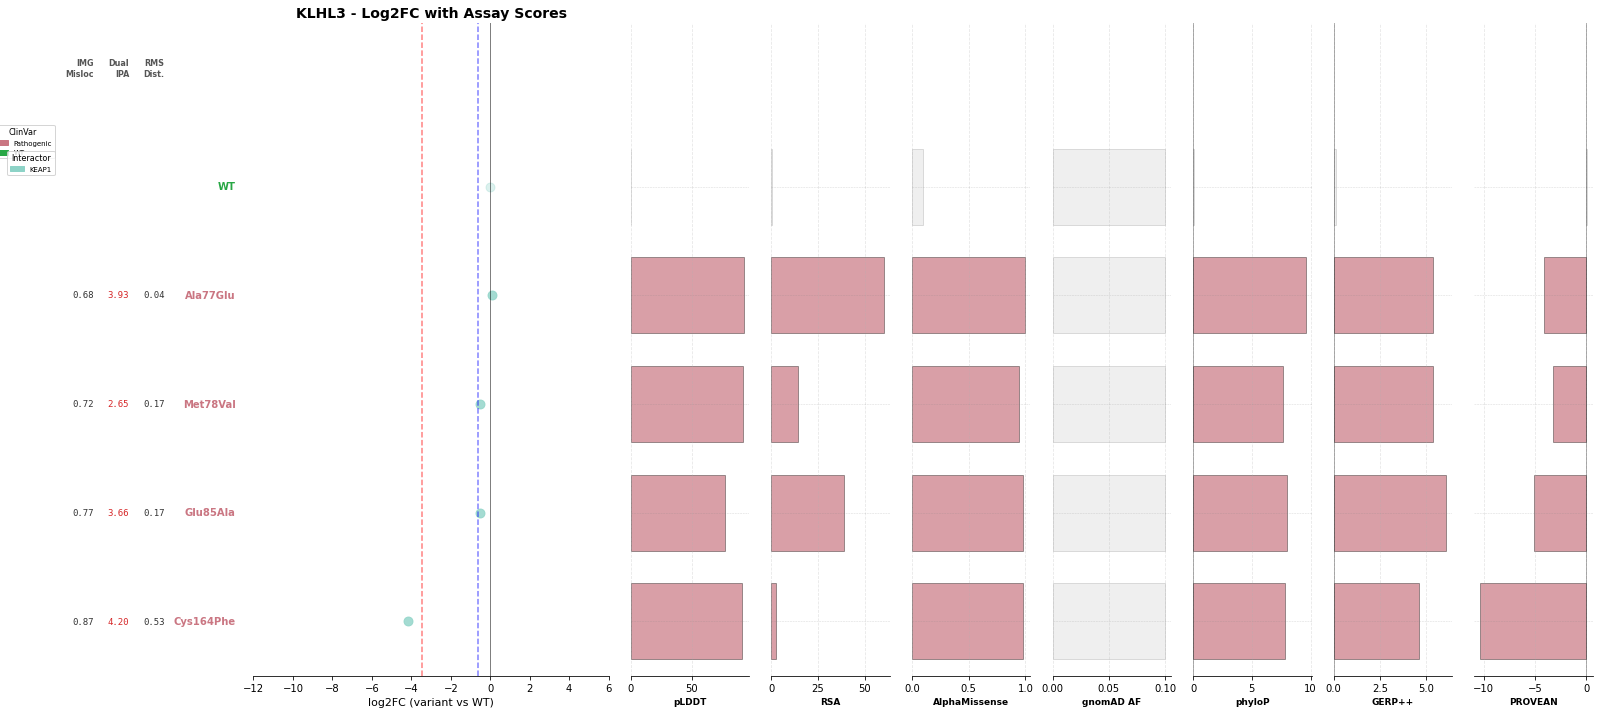

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/COL2A1_log2fc_panel.pdf


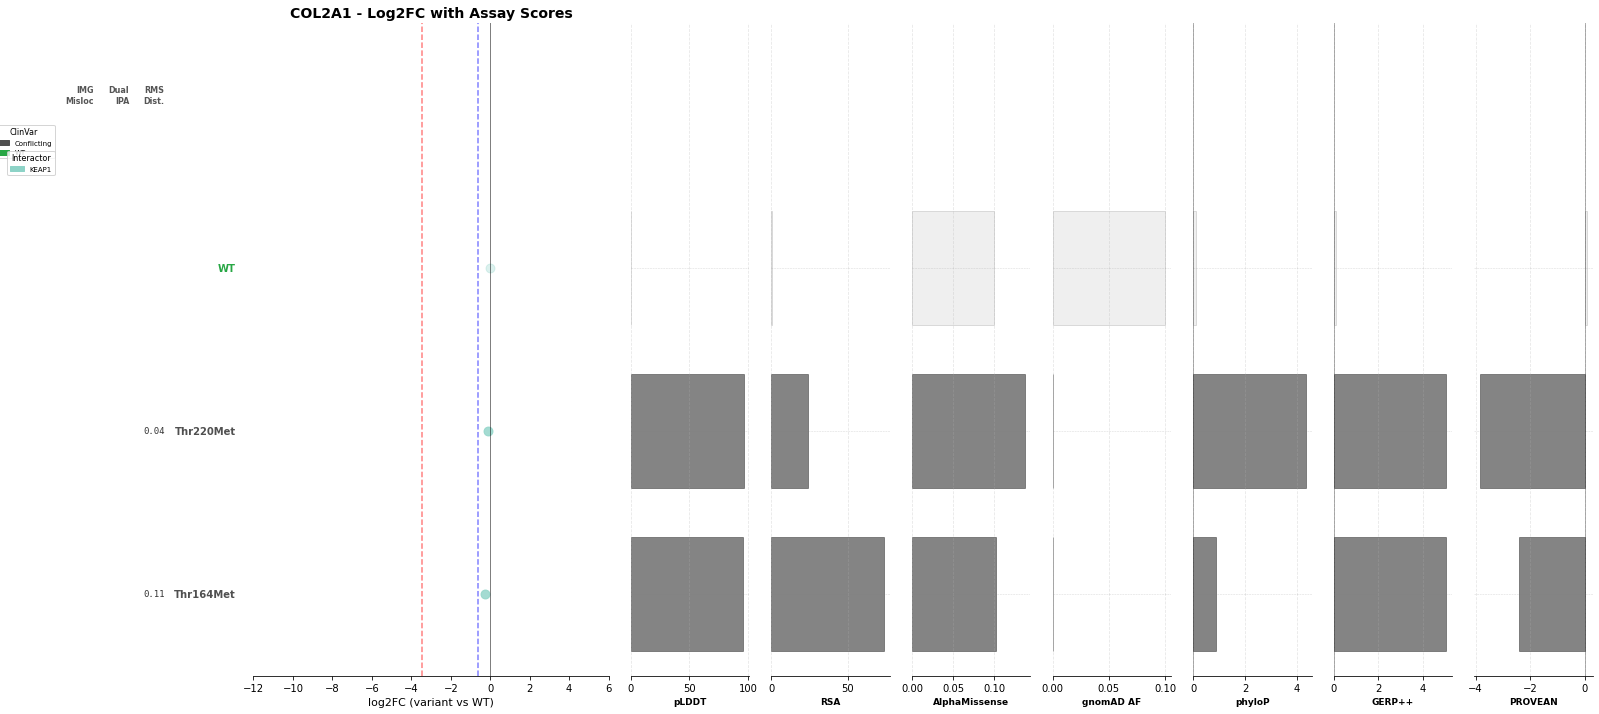

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PYGL_log2fc_panel.pdf


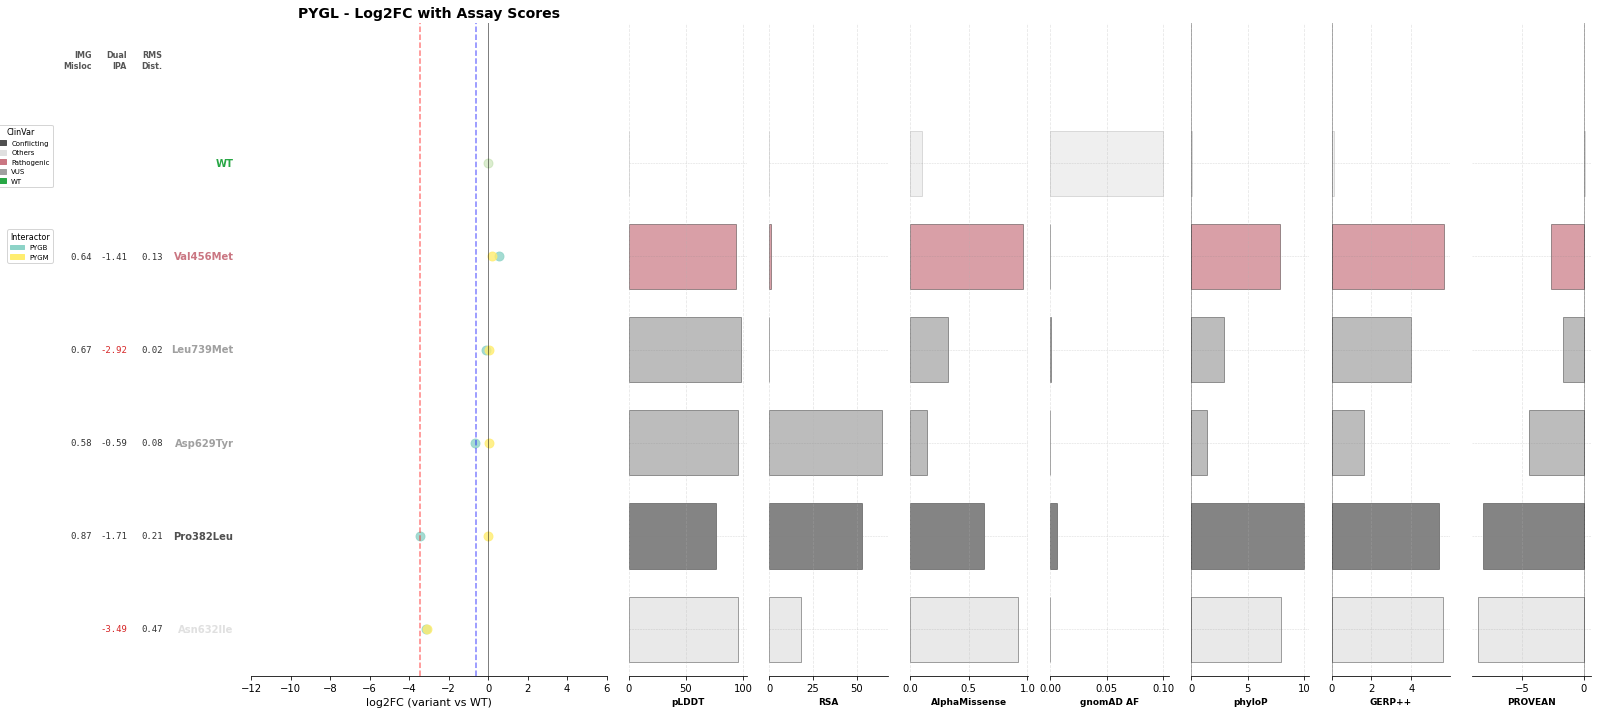

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/FBP1_log2fc_panel.pdf


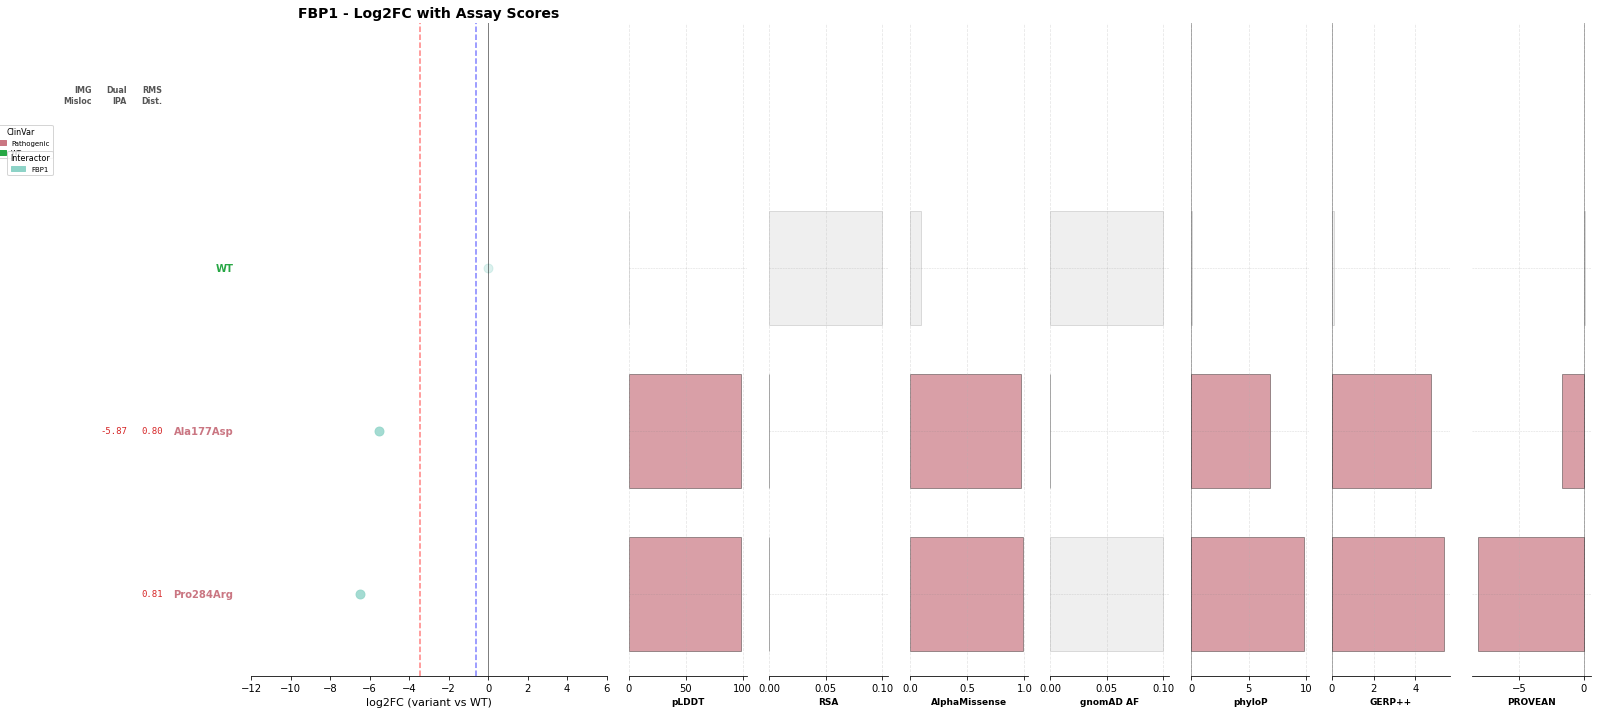

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GALE_log2fc_panel.pdf


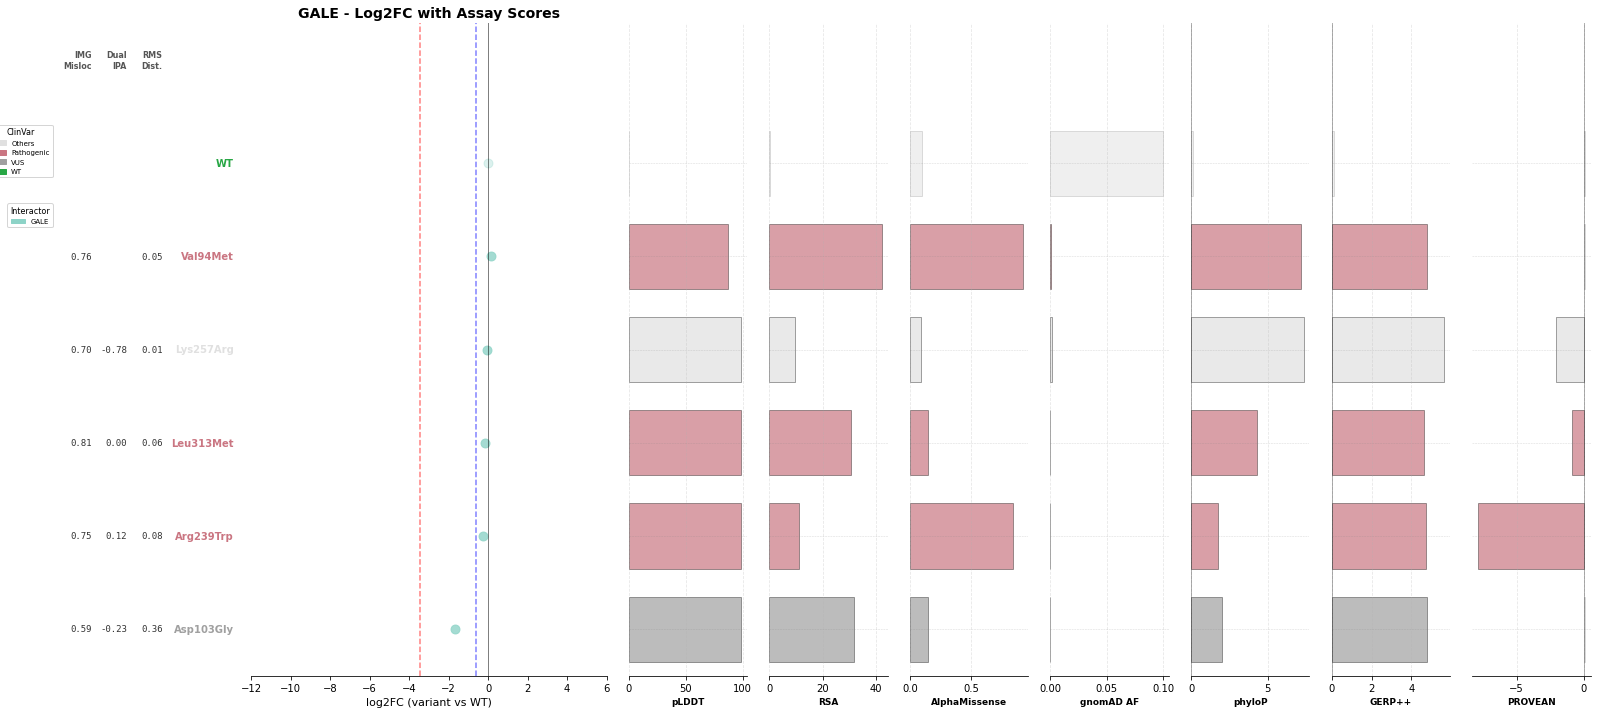

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/HBD_log2fc_panel.pdf


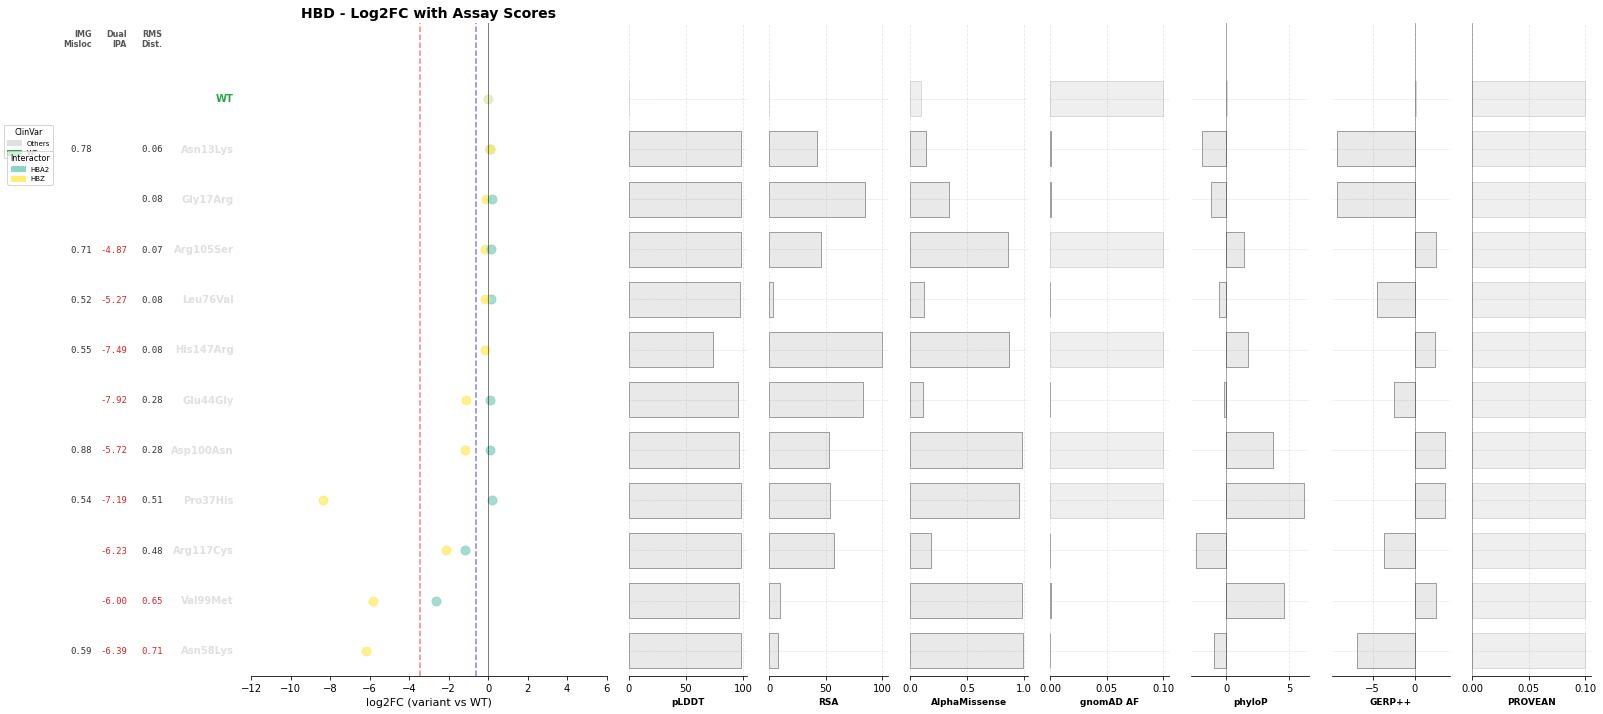

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/MVK_log2fc_panel.pdf


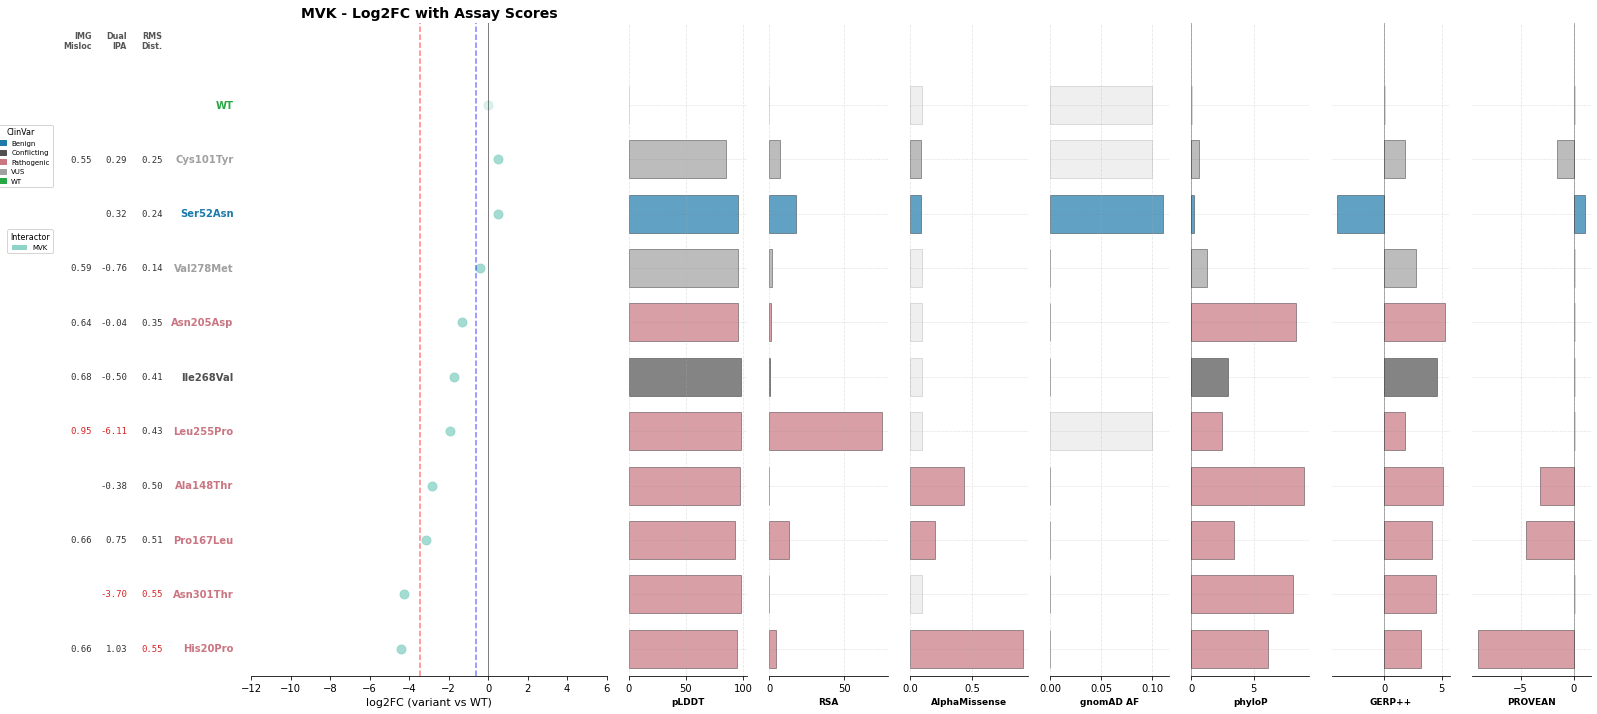

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/COQ8A_log2fc_panel.pdf


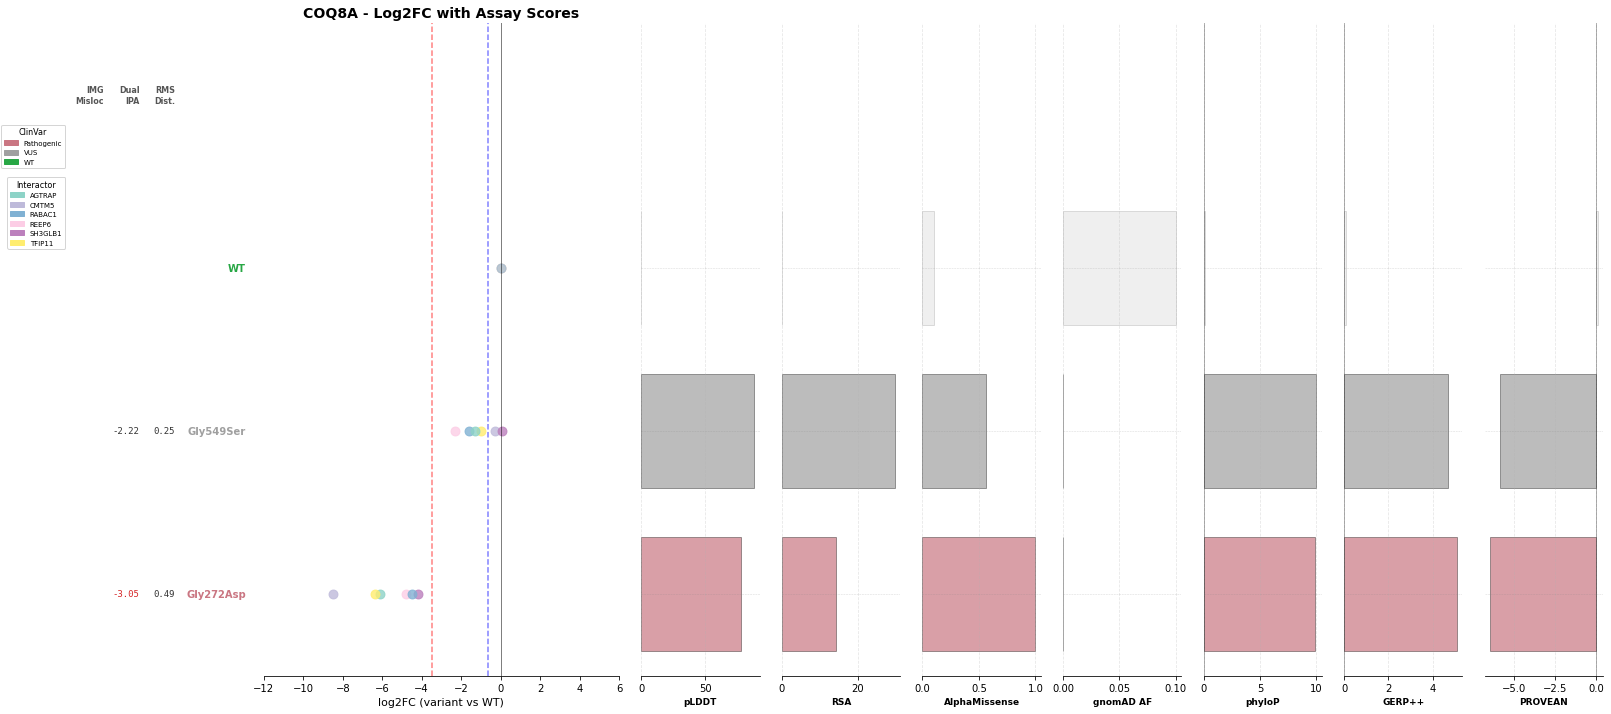

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/HPRT1_log2fc_panel.pdf


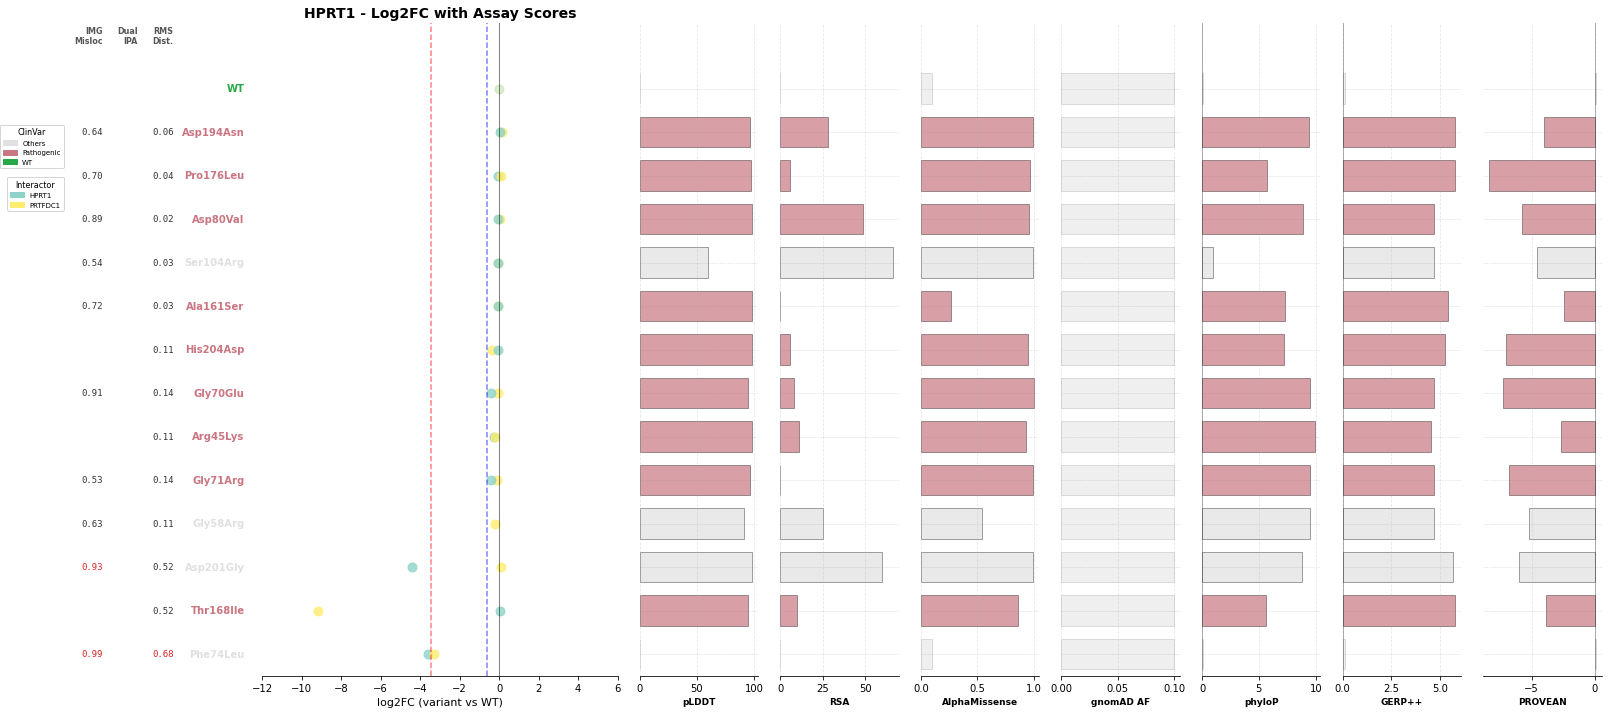

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TTR_log2fc_panel.pdf


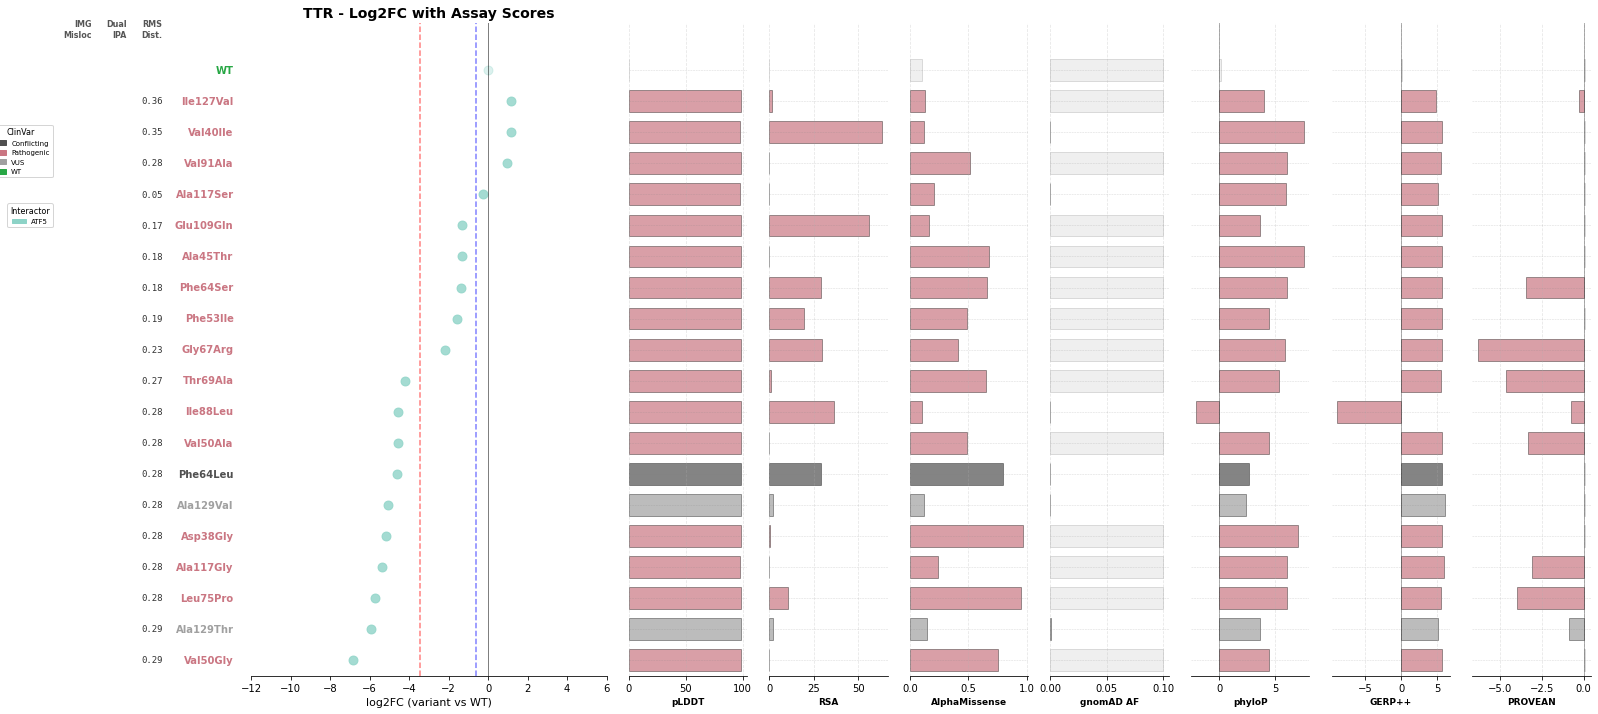

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/CHN1_log2fc_panel.pdf


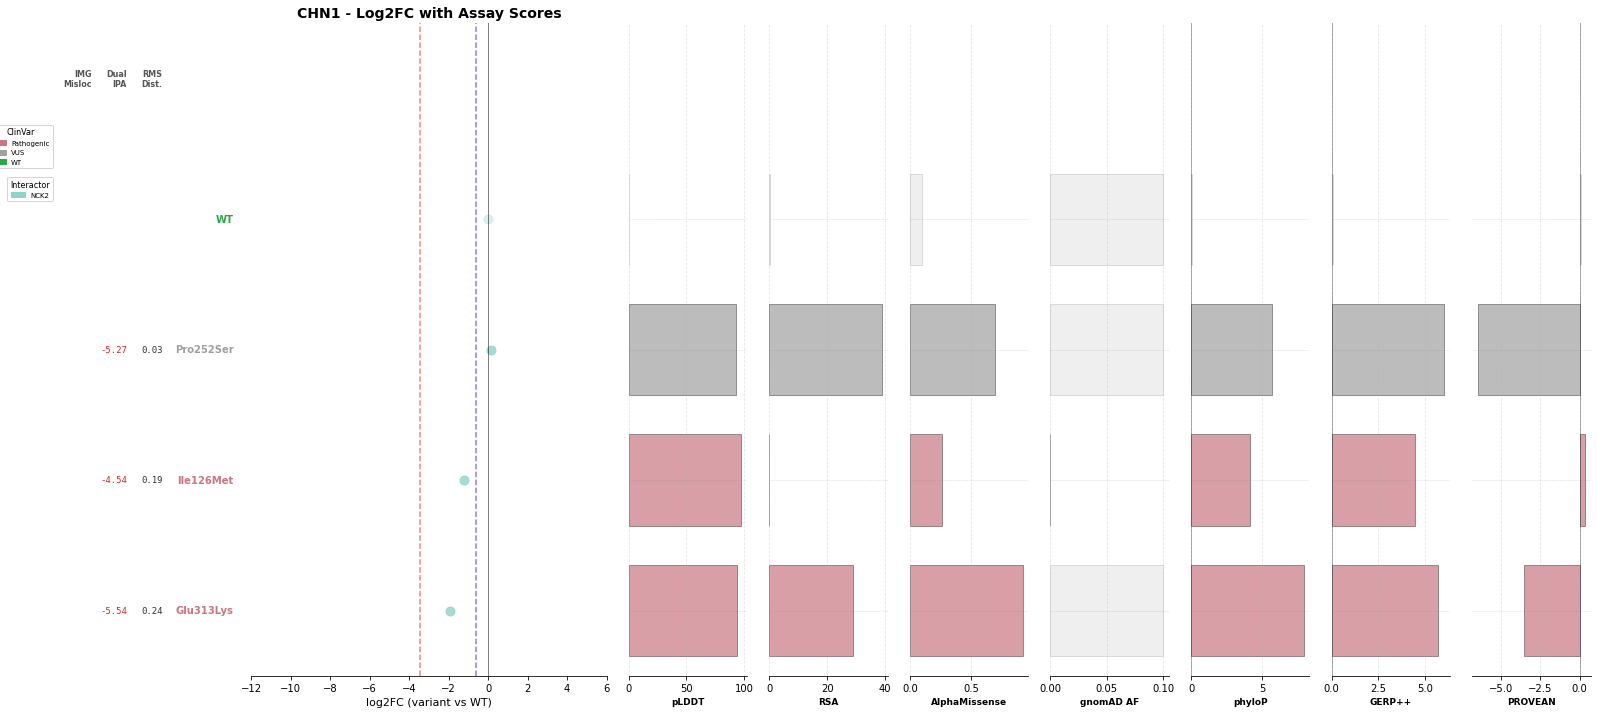

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TMEM43_log2fc_panel.pdf


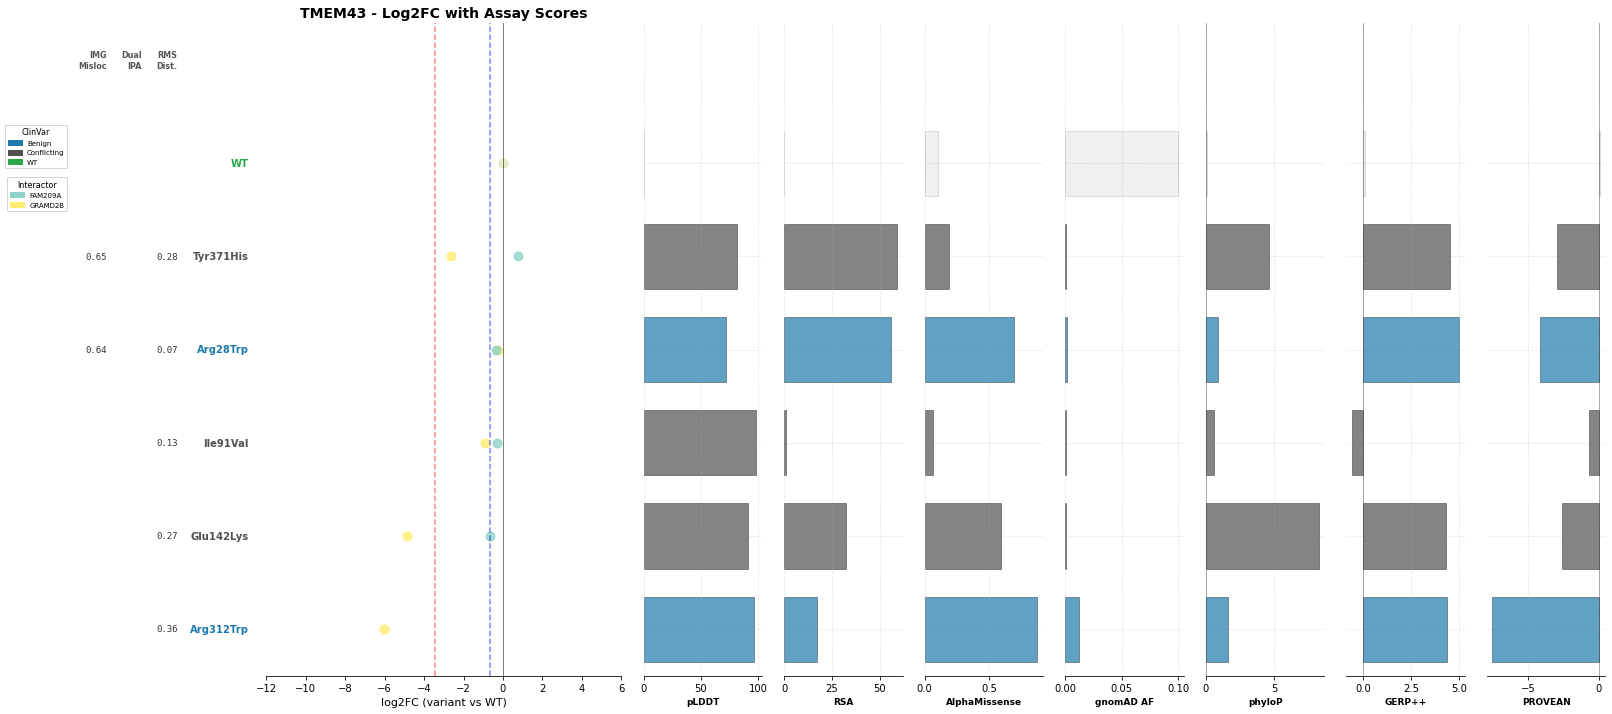

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PRPS1_log2fc_panel.pdf


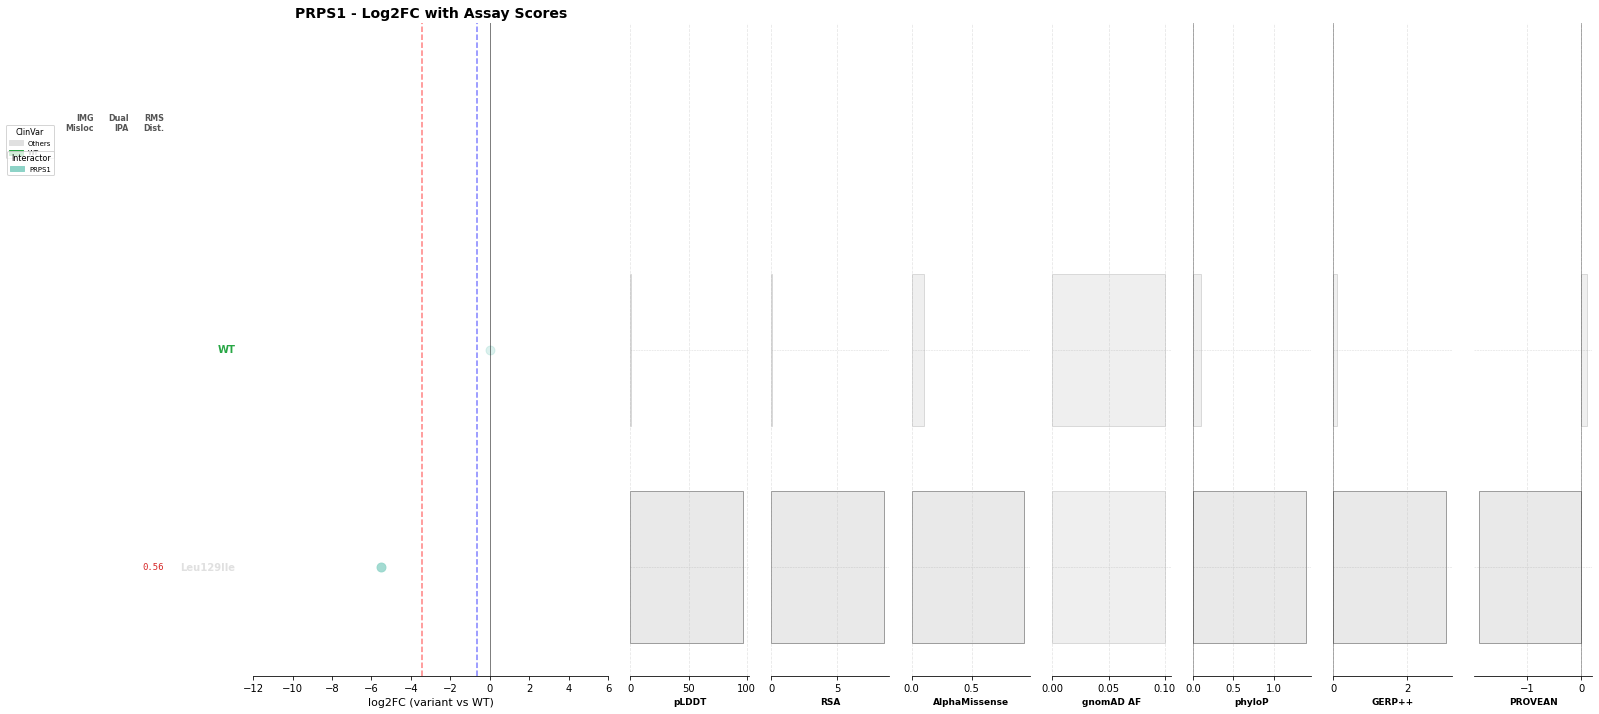

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/STAR_log2fc_panel.pdf


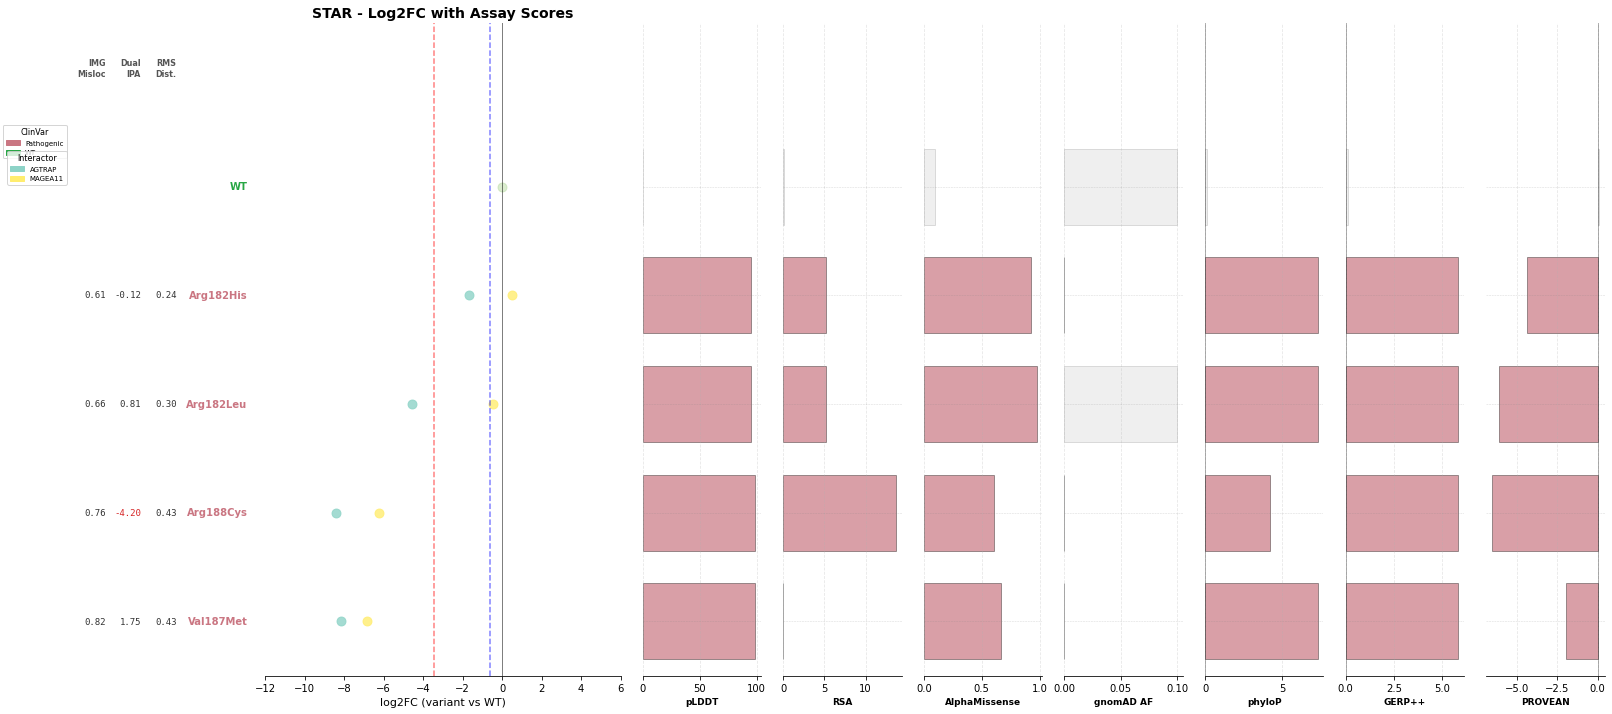

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GMPPB_log2fc_panel.pdf


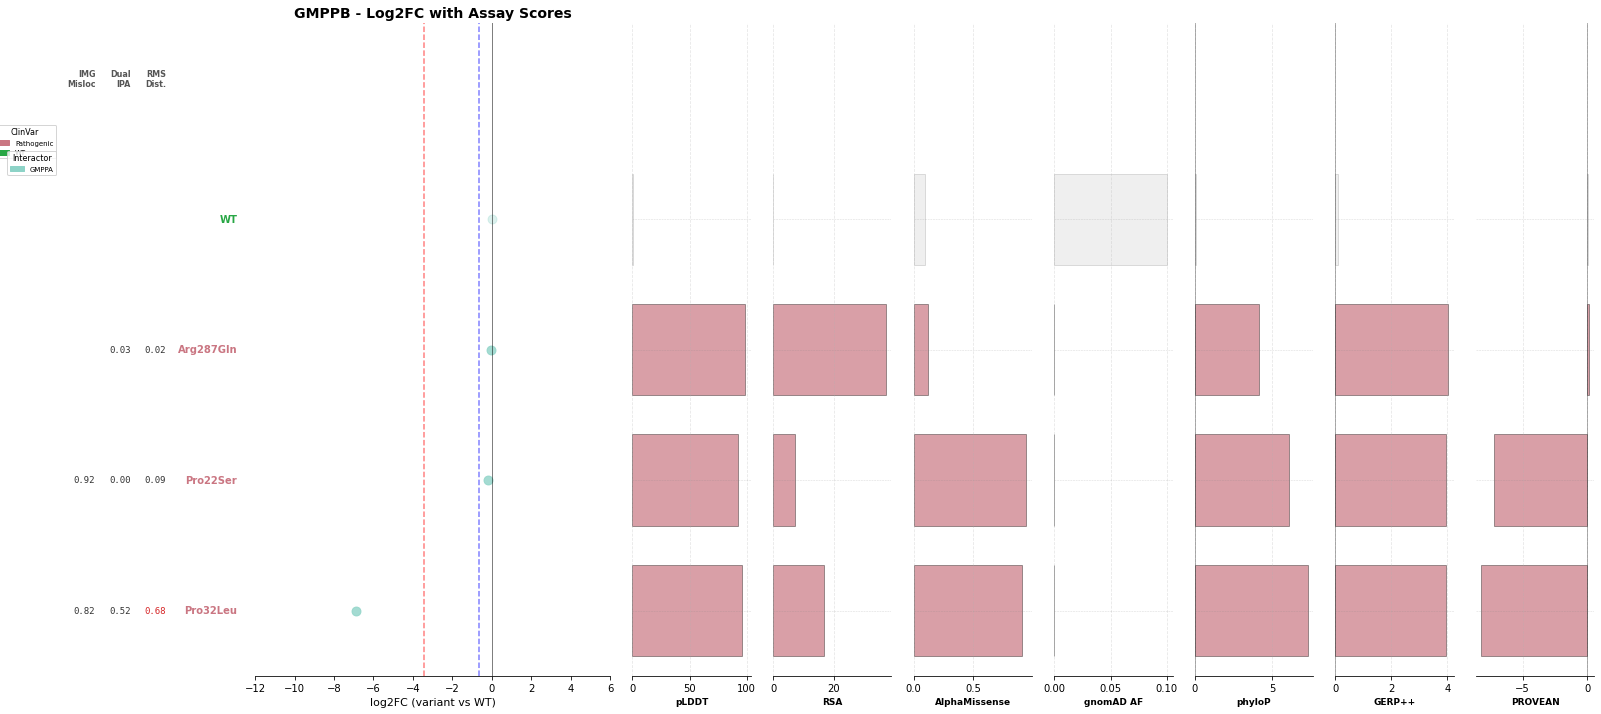

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TPM1_log2fc_panel.pdf


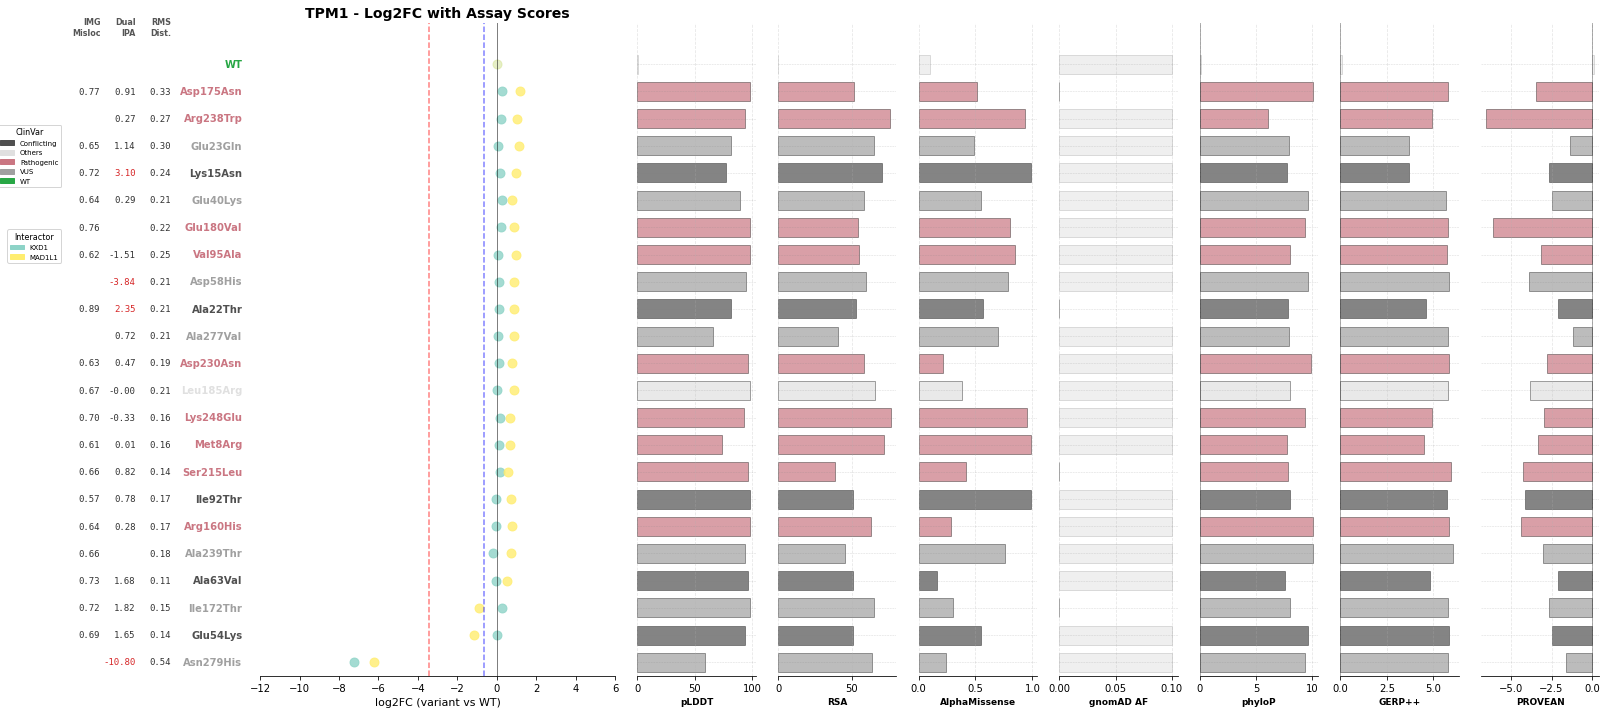

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GSS_log2fc_panel.pdf


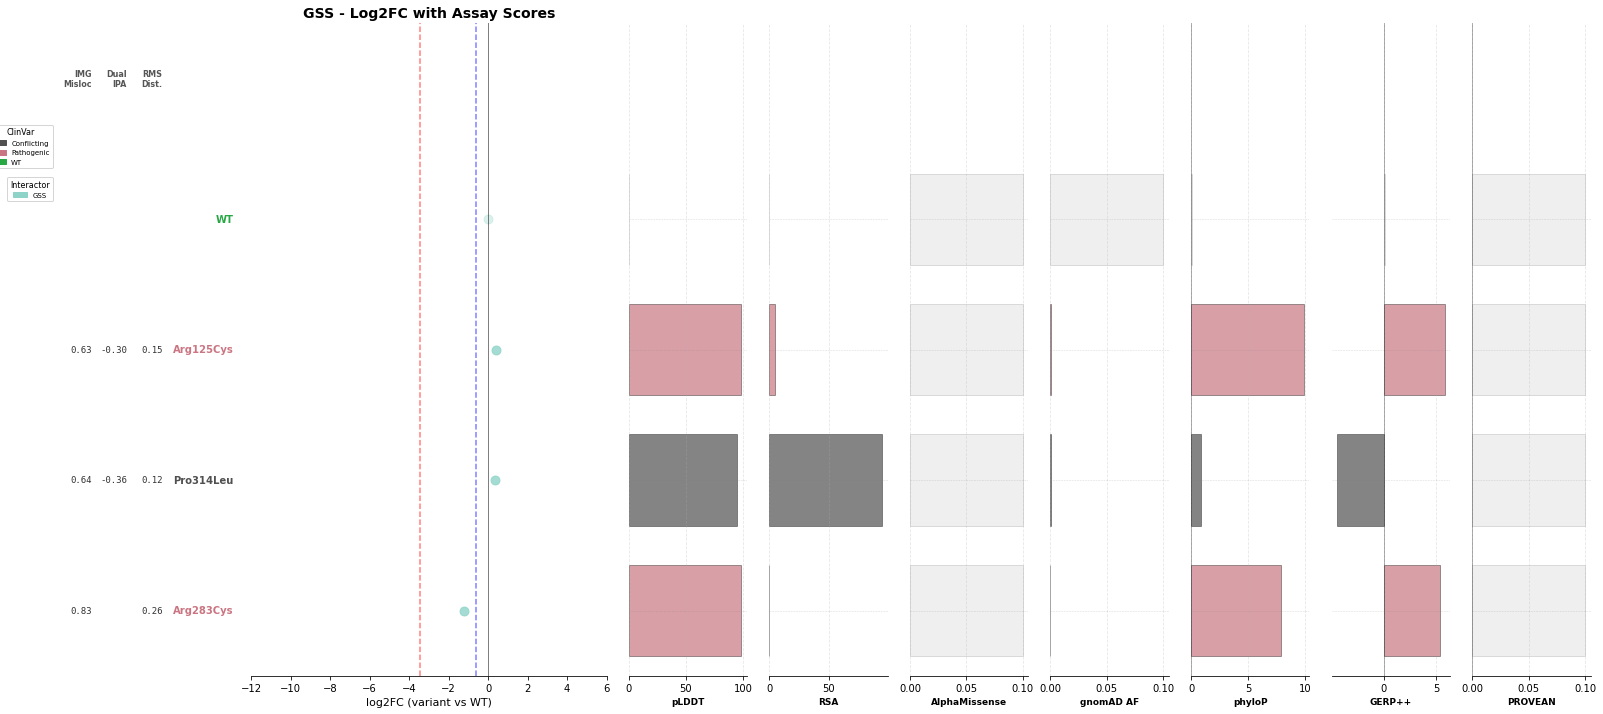

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/ZMYND10_log2fc_panel.pdf


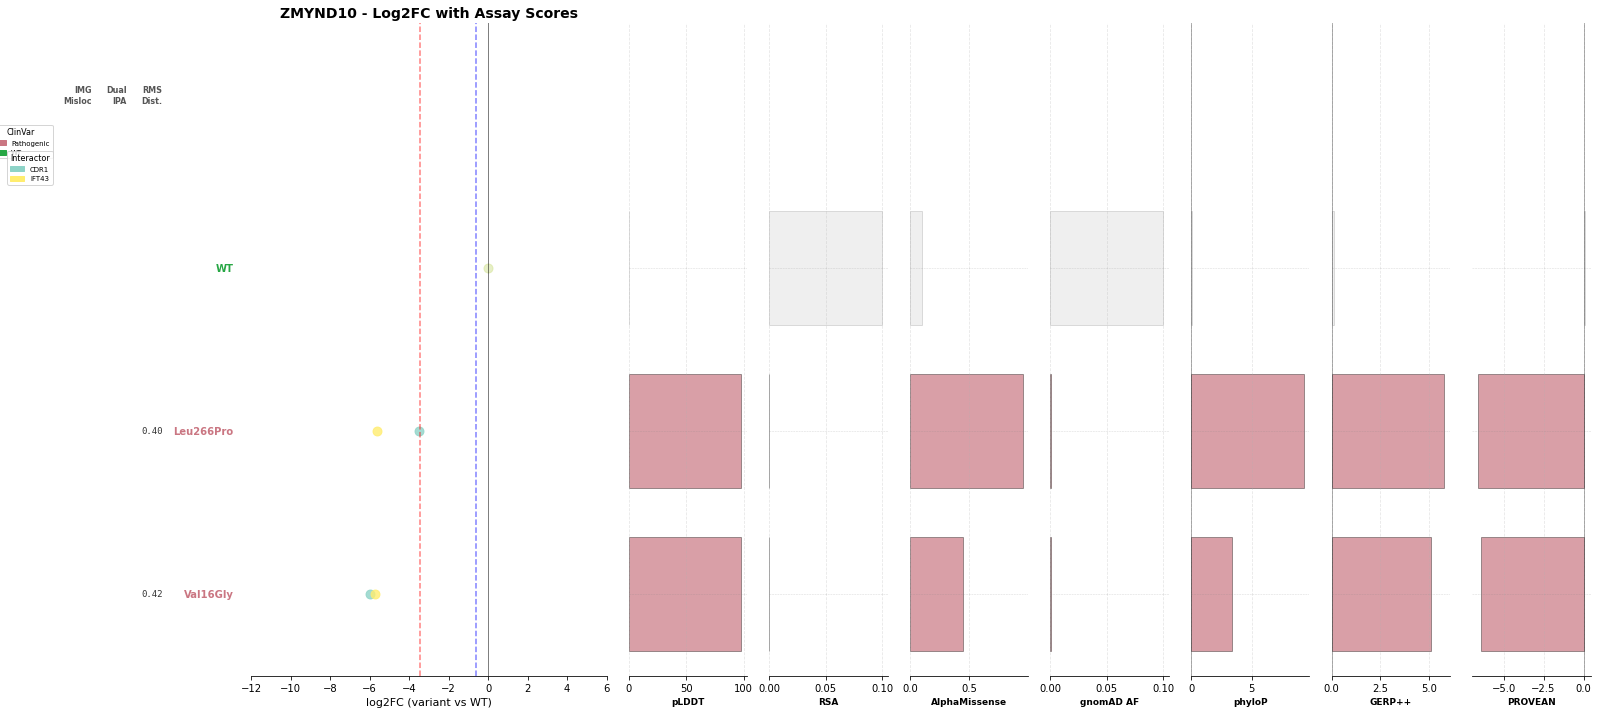

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/TH_log2fc_panel.pdf


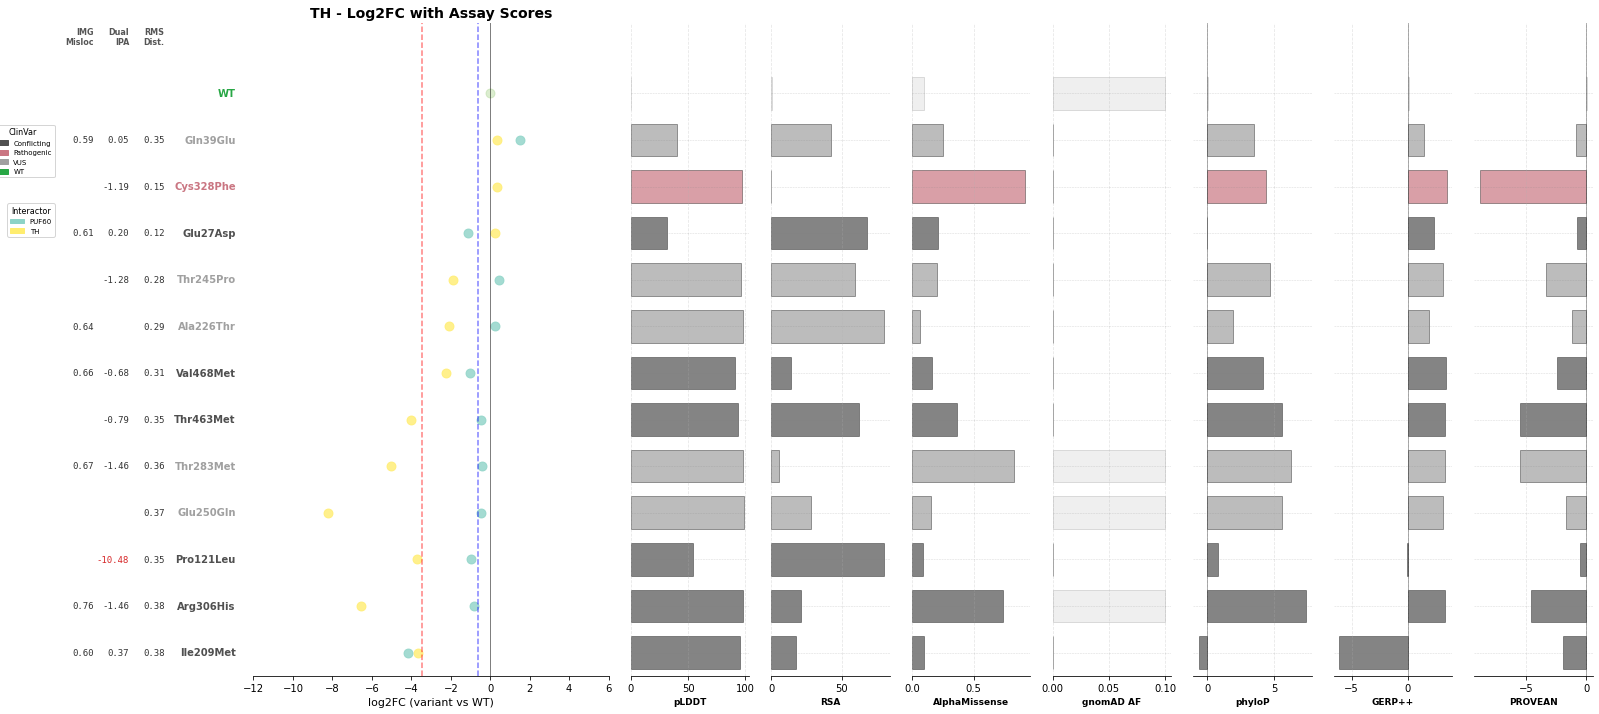

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/GCK_log2fc_panel.pdf


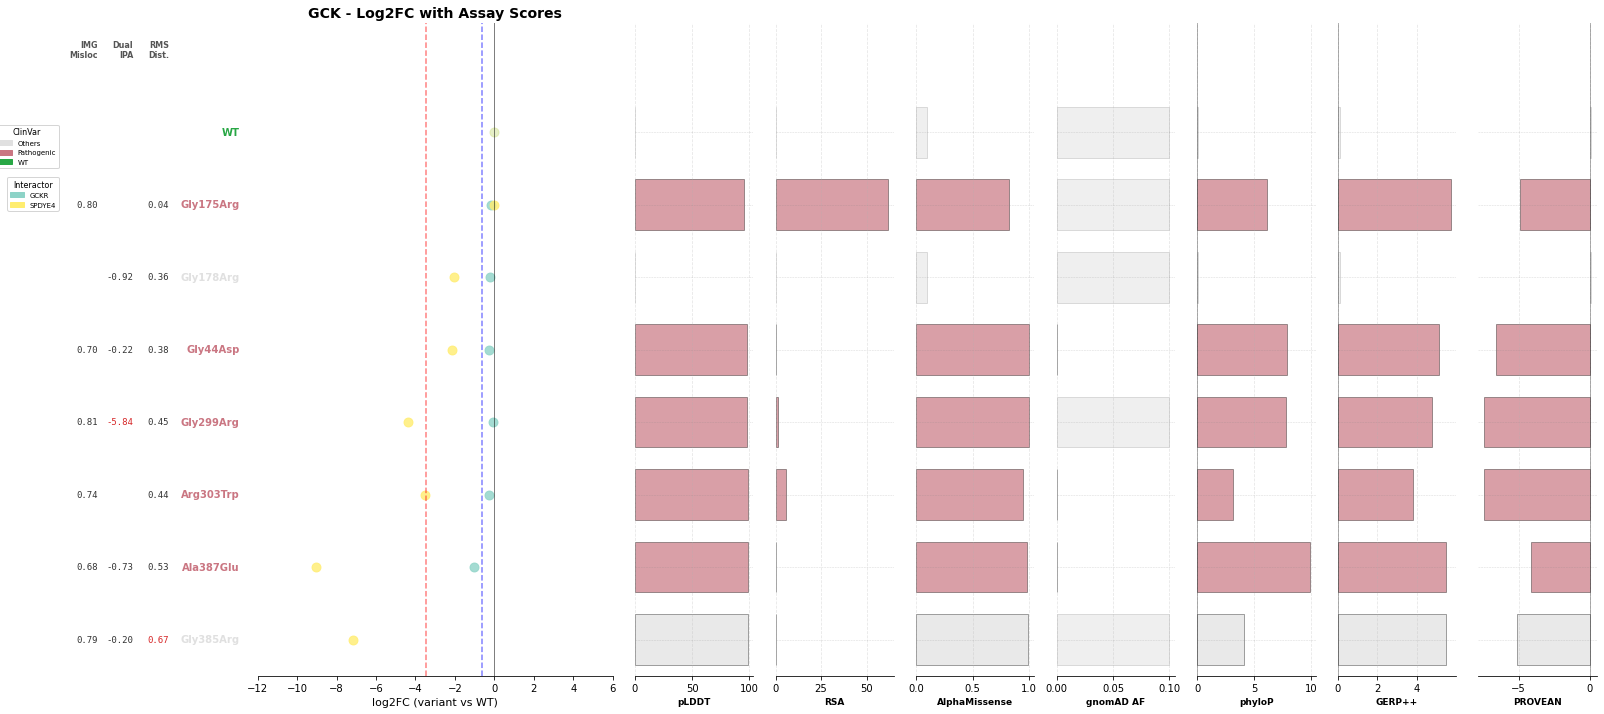

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/ALAS2_log2fc_panel.pdf


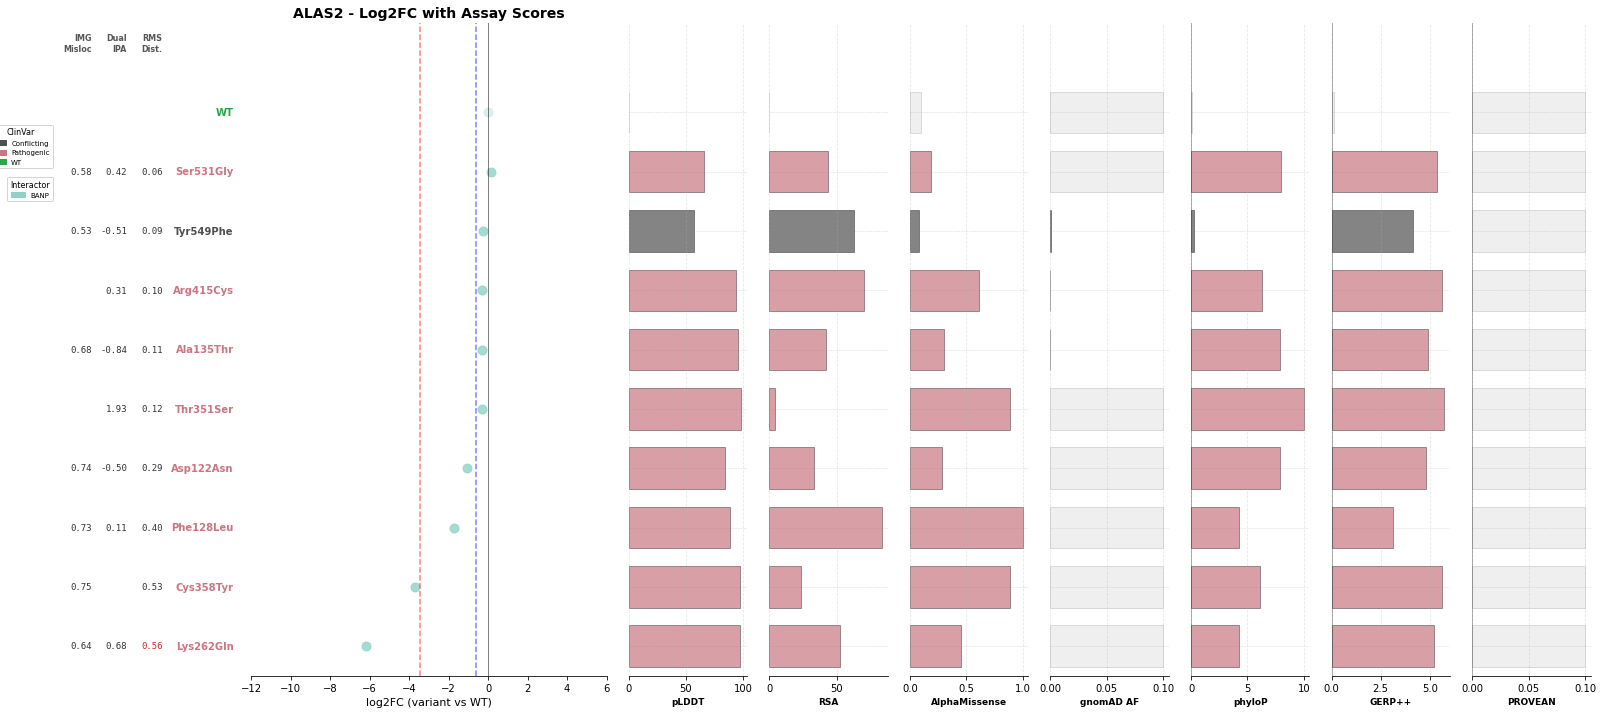

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SH3BP2_log2fc_panel.pdf


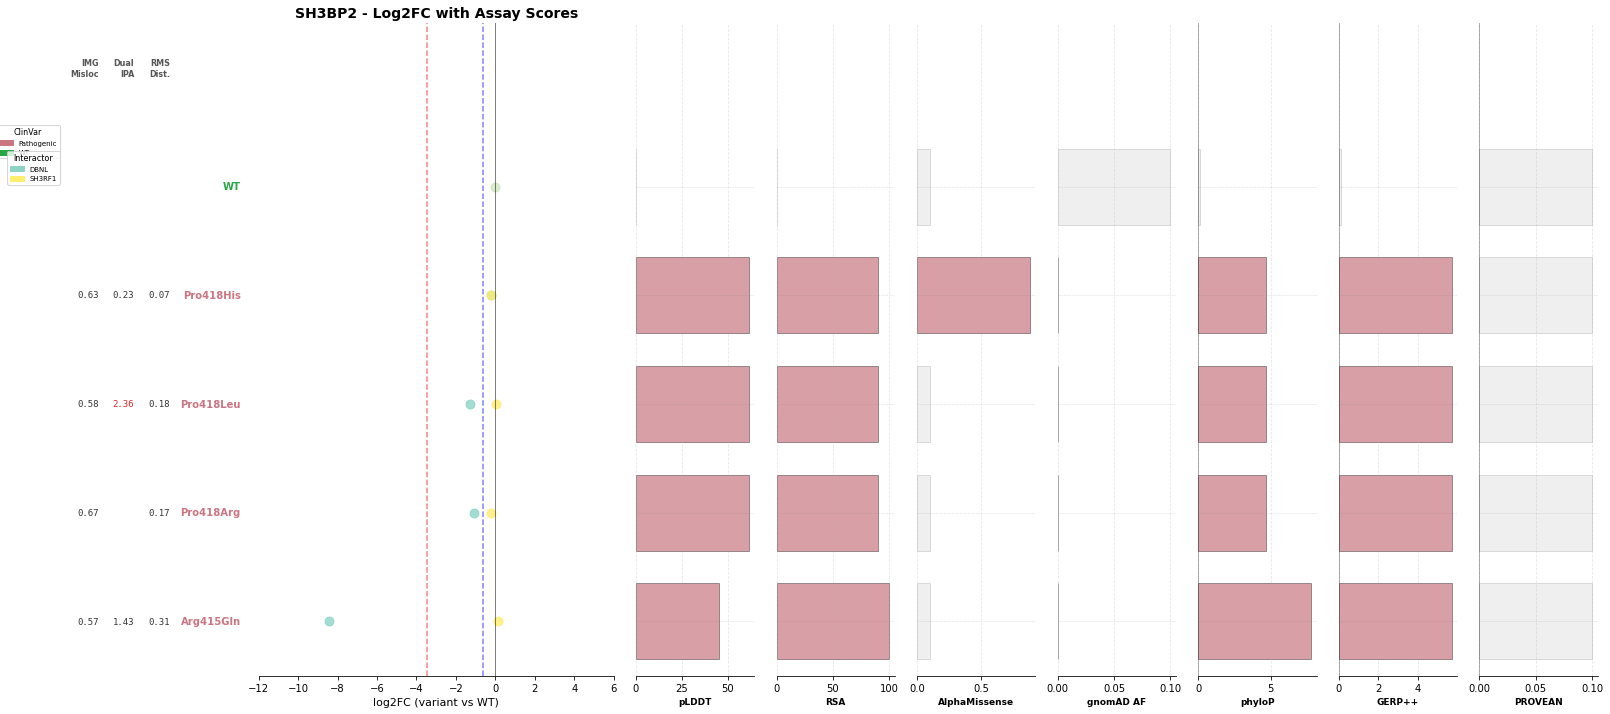

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/AIPL1_log2fc_panel.pdf


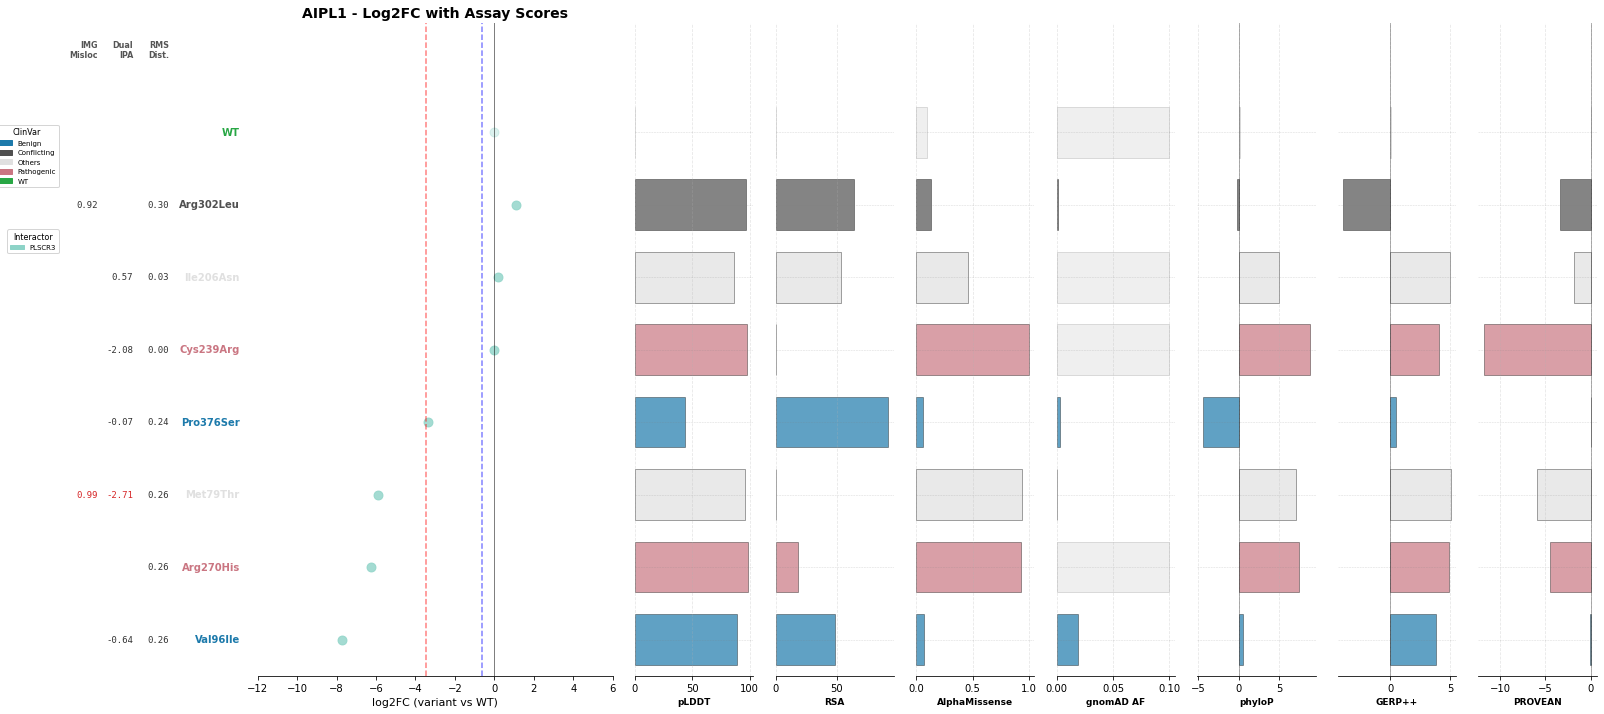

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:106: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/SMAD3_log2fc_panel.pdf


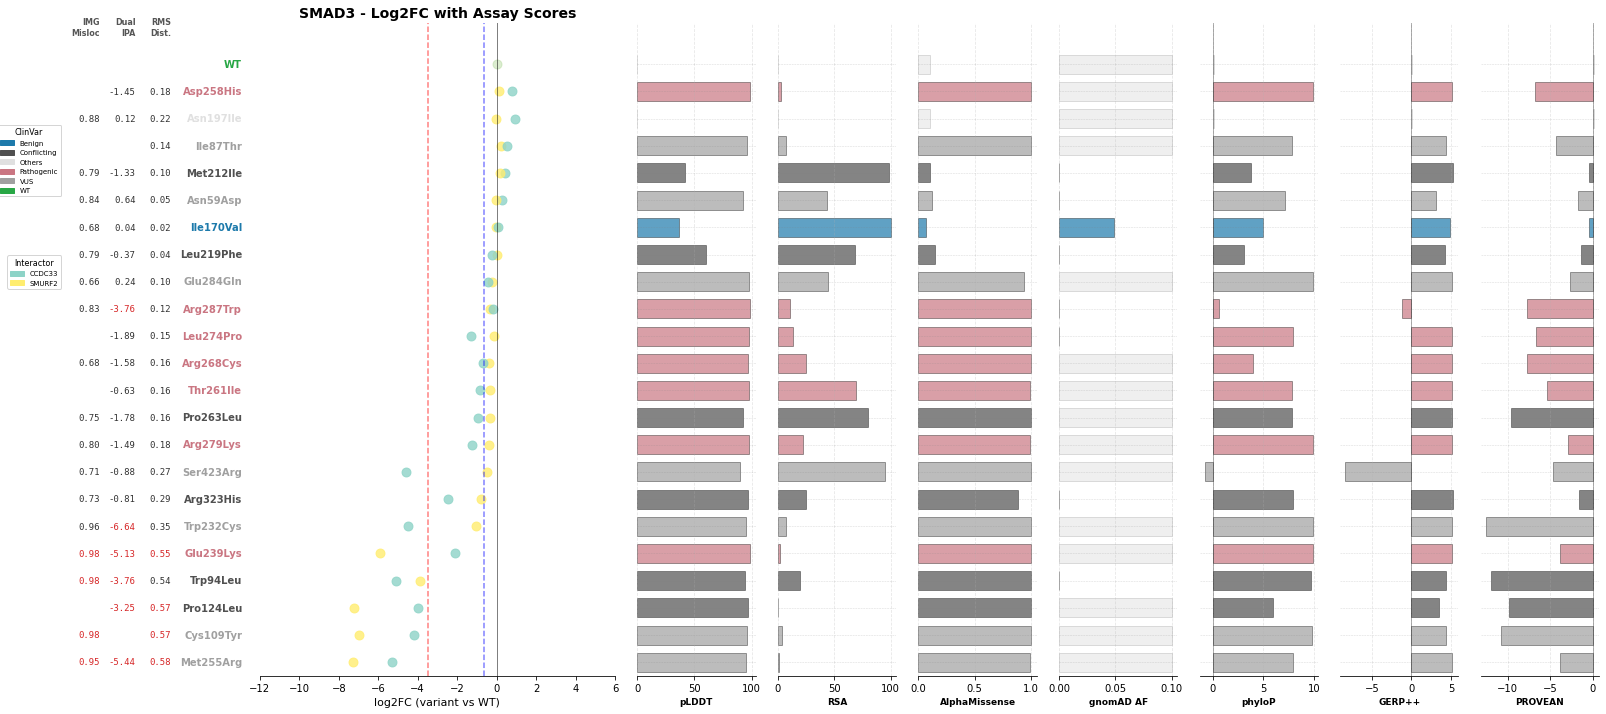

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/ASNS_log2fc_panel.pdf


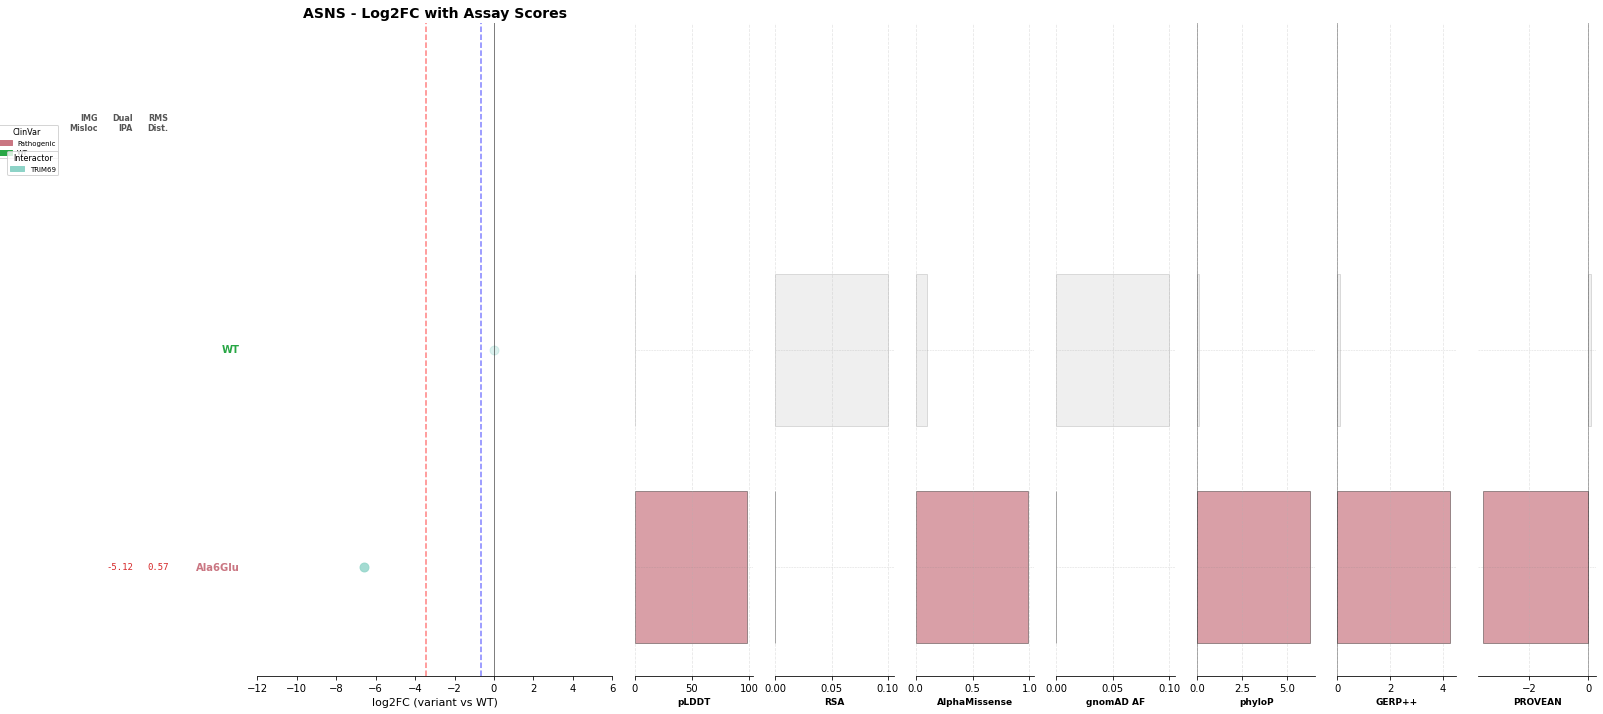

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_43929/3105447215.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: ../3_outputs/sqY2H/log2fc_barplots/PKP2_log2fc_panel.pdf


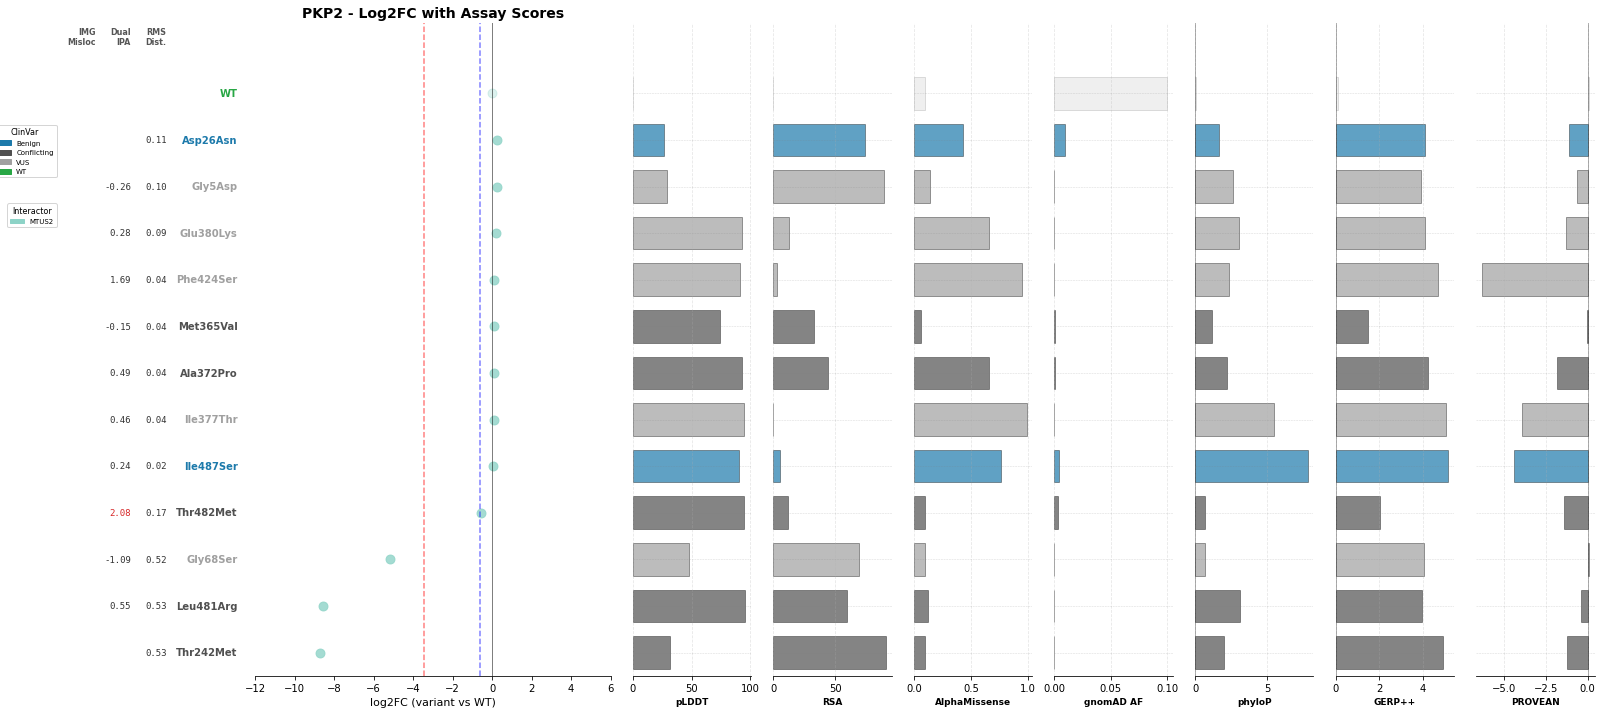

In [129]:
for symbol in edge_df['symbol'].unique():
    fig, axes = plot_log2fc_panel(
        edge_df=edge_df,
        db_symbol=symbol,
        orf_distances=orf_distances,
        all_assay_df=all_assay_df,
        palette_dict=palette_dict,
        save_path=f'{outputs_dir}/log2fc_barplots/{symbol}_log2fc_panel.pdf'
    )